In [ ]:
# Instala dependencias no Colab
!pip install -q yfinance statsmodels scikit-learn tensorflow keras pmdarima

# TCC Final - Comparação Preditiva Multiativo em Criptoativos

**Objetivo.** Reunir apenas a trilha analítica final do TCC no alvo harmonizado `price`, preservando benchmark ARIMA, ETS, redes neurais, baseline ingênuo, teste de Diebold-Mariano, robustez por múltiplas seeds e cross-asset corrigido.

**Escopo.** A comparação principal cobre `BTC-USD`, `ETH-USD`, `LTC-USD` e `XRP-USD`.

**Guia de leitura.** A narrativa central deste notebook está organizada em `price`.


In [ ]:
NOTEBOOK_PATH_FINAL = "TCC_final_price.ipynb"

import time
import numpy as np
import pandas as pd
import yfinance as yf
from IPython.display import display

def _dl_one(symbol, start, end, retries=3, sleep=1.5):  #baixa os dados do yf para cada ativo, 3 tentativas se erro, e sleep de 1.5 seg;
    last_err = None
    for k in range(retries):
        try:
            df = yf.download(
                symbol, start=start, end=end,
                interval="1d", auto_adjust=False, progress=False,
                threads=False
            )
            if isinstance(df, pd.DataFrame) and not df.empty:
                # prefira 'Adj Close' quando existir; caso contrário, 'Close'
                col = "Close"                #"Adj Close" if "Adj Close" in df.columns else "Close"
                close = df[[col]].copy() if isinstance(df[col], pd.DataFrame) else df[col]

                if isinstance(close, pd.DataFrame):
                    # DataFrame de 1 coluna -> renomeia o nome da coluna
                    close.columns = [symbol]
                    return close
                else:
                    # Series -> define o .name e converte para DataFrame
                    return close.rename(symbol).to_frame()
        except Exception as e:
            last_err = e
        time.sleep(sleep)

    print(f"[WARN] Falha ao baixar {symbol}: {last_err}")
    return pd.DataFrame(columns=[symbol])

def load_prices(tickers, start, end): #para 1 ou mais tickers e te devolve um único DataFrame pronto para uso.
    if isinstance(tickers, str):
        tickers = [tickers]
    frames = []
    for t in tickers:
      close_t = _dl_one(t, start, end)
      frames.append(close_t)
    close = pd.concat(frames, axis=1).ffill().dropna(how="all")
    #.ffill(): preenche valores faltantes para frente (carrega o último valor conhecido).
    #.dropna(how="all"): remove linhas em que todas as colunas são NaN.
    #Se ficar vazio, lança erro; senão define close.index.name = "Date" e retorna.
    if close.empty:
      raise RuntimeError("Nenhum preço baixado. Tente novamente mais tarde ou reduza a lista de tickers.")
    close.index.name = "Date"
    return close

In [ ]:
# Padrão visual central das figuras e tabelas

from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, PercentFormatter, AutoLocator

try:
    import seaborn as sns
except Exception:
    sns = None

THESIS_MODEL_ORDER = ["ARIMA", "ETS", "LSTM", "RNN", "GRU", "NAIVE_ZERO"]
THESIS_ASSET_ORDER = ["BTC-USD", "ETH-USD", "LTC-USD", "XRP-USD"]
THESIS_MODEL_COLORS = {
    "ARIMA": "#1f4e79",
    "ETS": "#3a7d44",
    "LSTM": "#9c4f2f",
    "RNN": "#6b4c9a",
    "GRU": "#2b6f89",
    "NAIVE_ZERO": "#6c757d",
}
THESIS_METRIC_COLORS = {"RMSE": "#1f4e79", "MAE": "#3a7d44", "Direction": "#9c4f2f"}


def set_thesis_plot_style():
    palette_cycle = [
        THESIS_MODEL_COLORS["ARIMA"], THESIS_MODEL_COLORS["ETS"], THESIS_MODEL_COLORS["LSTM"],
        THESIS_MODEL_COLORS["RNN"], THESIS_MODEL_COLORS["GRU"], THESIS_MODEL_COLORS["NAIVE_ZERO"],
        "#8c8c8c", "#b07d2c",
    ]
    plt.rcParams.update({
        "figure.dpi": 160,
        "savefig.dpi": 320,
        "figure.figsize": (7.0, 4.4),
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "font.family": "serif",
        "font.serif": ["STIXGeneral", "DejaVu Serif", "Times New Roman"],
        "mathtext.fontset": "stix",
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#7f8c8d",
        "axes.linewidth": 0.8,
        "axes.grid": True,
        "grid.color": "#d9dde3",
        "grid.linestyle": "-",
        "grid.linewidth": 0.6,
        "grid.alpha": 0.7,
        "lines.linewidth": 1.8,
        "lines.markersize": 5,
        "legend.frameon": False,
        "axes.prop_cycle": plt.cycler(color=palette_cycle),
    })
    return THESIS_MODEL_COLORS.copy()



def finalize_thesis_axis(ax, title=None, xlabel=None, ylabel=None, zero_line=False, legend=True):
    if title:
        ax.set_title(title, loc="left", pad=8, fontweight="semibold")
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    if zero_line:
        ax.axhline(0.0, color="#7f8c8d", linestyle="--", linewidth=0.9, alpha=0.85, zorder=0)
    ax.grid(True, axis="y")
    ax.grid(False, axis="x")
    ax.spines["left"].set_color("#7f8c8d")
    ax.spines["bottom"].set_color("#7f8c8d")
    handles, labels = ax.get_legend_handles_labels()
    if legend and handles:
        if len(handles) > 4 or max(len(str(label)) for label in labels) > 12:
            ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), ncol=1)
        else:
            ax.legend(loc="best")
    elif ax.get_legend() is not None:
        ax.get_legend().remove()
    return ax



def save_thesis_figure(fig, name, folder="images", formats=("png",)):
    if fig is None:
        raise ValueError("Figure is None and cannot be saved.")
    output_dir = Path(folder)
    output_dir.mkdir(parents=True, exist_ok=True)
    safe_name = str(name).strip().replace(" ", "_")
    saved_paths = {}
    for fmt in formats:
        fmt_clean = str(fmt).lower().strip(".")
        output_path = output_dir / f"{safe_name}.{fmt_clean}"
        fig.savefig(output_path, bbox_inches="tight")
        saved_paths[fmt_clean] = str(output_path)
    return saved_paths



def _thesis_model_sequence(models):
    seen = [str(model) for model in models]
    ordered = [model for model in THESIS_MODEL_ORDER if model in seen]
    ordered.extend(sorted(set(seen).difference(ordered)))
    return ordered



def _thesis_model_color(model_name):
    return THESIS_MODEL_COLORS.get(str(model_name), "#5f6b7a")



def _format_display_number(value, decimals=4):
    return "NA" if pd.isna(value) else f"{float(value):.{decimals}f}"



def _format_display_percent(value, decimals=2):
    return "NA" if pd.isna(value) else f"{100.0 * float(value):.{decimals}f}%"



def _get_thesis_correlation_values(series, nlags, method="acf"):
    from statsmodels.tsa.stattools import acf as sm_acf, pacf as sm_pacf

    clean_series = pd.Series(series).dropna().astype(float)
    if method == "acf":
        return sm_acf(clean_series, nlags=nlags, fft=True)
    return sm_pacf(clean_series, nlags=nlags, method="ywm")



def _plot_thesis_correlation_function(ax, values, n_obs, title, ylabel):
    coeffs = np.asarray(values[1:], dtype=float)
    lags = np.arange(1, coeffs.shape[0] + 1)
    conf = 1.96 / np.sqrt(max(int(n_obs), 1))
    ax.axhspan(-conf, conf, color="#d9dde3", alpha=0.45, zorder=0)
    if coeffs.size:
        ax.vlines(lags, 0.0, coeffs, color="#1f4e79", linewidth=1.35)
        ax.scatter(lags, coeffs, color="#1f4e79", s=18, zorder=3)
        local_max = float(np.nanmax(np.abs(coeffs)))
    else:
        local_max = 0.0
    ylim = max(0.08, conf * 2.4, local_max * 1.3)
    ylim = min(ylim, 0.65)
    ax.set_xlim(0.5, max(len(lags), 1) + 0.5)
    ax.set_ylim(-ylim, ylim)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=min(8, max(len(lags), 2))))
    ax.yaxis.set_major_locator(AutoLocator())
    finalize_thesis_axis(ax, title=title, xlabel="Lag", ylabel=ylabel, zero_line=True, legend=False)
    return ax



def plot_series_and_differences_thesis(series, name="series"):
    set_thesis_plot_style()
    s = pd.Series(series).dropna().reset_index(drop=True)
    diff1 = s.diff().dropna()
    fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.0))
    axes[0].plot(s.index, s.values, color="#1f4e79")
    finalize_thesis_axis(axes[0], title=f"{name}: nível", xlabel="Observação", ylabel="Preço", legend=False)
    if diff1.empty:
        axes[1].text(0.5, 0.5, "Série curta", transform=axes[1].transAxes, ha="center", va="center")
        finalize_thesis_axis(axes[1], title="Primeira diferença", xlabel="Observação", ylabel="Delta do preço", legend=False)
    else:
        axes[1].plot(diff1.index, diff1.values, color="#9c4f2f")
        finalize_thesis_axis(axes[1], title="Primeira diferença", xlabel="Observação", ylabel="Delta do preço", zero_line=True, legend=False)
    fig.tight_layout()
    return fig



def plot_acf_pacf_diagnostics_thesis(series, name="series", lags=30):
    set_thesis_plot_style()
    s = pd.Series(series).dropna()
    max_lags = min(lags, len(s) // 2 - 1)
    if max_lags < 1:
        raise ValueError(f"{name}: series too short to plot ACF/PACF (n={len(s)})")
    acf_vals = _get_thesis_correlation_values(s, nlags=max_lags, method="acf")
    pacf_vals = _get_thesis_correlation_values(s, nlags=max_lags, method="pacf")
    fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.0))
    _plot_thesis_correlation_function(axes[0], acf_vals, len(s), f"ACF: {name}", "Autocorrelação")
    _plot_thesis_correlation_function(axes[1], pacf_vals, len(s), f"PACF: {name}", "Autocorrelação parcial")
    fig.tight_layout()
    return fig



def plot_differenced_acf_pacf_thesis(series, name="series", lags=30):
    set_thesis_plot_style()
    diff1 = pd.Series(series).dropna().diff().dropna()
    max_lags = min(lags, len(diff1) // 2 - 1)
    if max_lags < 1:
        raise ValueError(f"{name}: differenced series too short to plot ACF/PACF (n={len(diff1)})")
    acf_vals = _get_thesis_correlation_values(diff1, nlags=max_lags, method="acf")
    pacf_vals = _get_thesis_correlation_values(diff1, nlags=max_lags, method="pacf")
    fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.0))
    _plot_thesis_correlation_function(axes[0], acf_vals, len(diff1), f"ACF: {name} diff(1)", "Autocorrelação")
    _plot_thesis_correlation_function(axes[1], pacf_vals, len(diff1), f"PACF: {name} diff(1)", "Autocorrelação parcial")
    fig.tight_layout()
    return fig



def compare_price_diff_vs_log_return_thesis(series, name="series", lags=30):
    set_thesis_plot_style()
    s = pd.Series(series).dropna()
    diff1 = s.diff().dropna()
    log_ret = np.log(s).diff().dropna() if (s > 0).all() else None
    n_rows = 2 if log_ret is not None else 1
    fig, axes = plt.subplots(n_rows, 3, figsize=(14.4, 4.2 * n_rows))
    axes = np.atleast_2d(axes)

    axes[0, 0].plot(diff1.index, diff1.values, color="#9c4f2f")
    finalize_thesis_axis(axes[0, 0], title=f"{name}: diff(1)", xlabel="Observação", ylabel="Delta do preço", zero_line=True, legend=False)
    max_lags_d = min(lags, len(diff1) // 2 - 1)
    if max_lags_d >= 1:
        acf_diff = _get_thesis_correlation_values(diff1, nlags=max_lags_d, method="acf")
        pacf_diff = _get_thesis_correlation_values(diff1, nlags=max_lags_d, method="pacf")
        _plot_thesis_correlation_function(axes[0, 1], acf_diff, len(diff1), f"ACF: {name} diff(1)", "Autocorrelação")
        _plot_thesis_correlation_function(axes[0, 2], pacf_diff, len(diff1), f"PACF: {name} diff(1)", "Autocorrelação parcial")
    else:
        axes[0, 1].text(0.5, 0.5, "Série curta", transform=axes[0, 1].transAxes, ha="center", va="center")
        axes[0, 2].text(0.5, 0.5, "Série curta", transform=axes[0, 2].transAxes, ha="center", va="center")
        finalize_thesis_axis(axes[0, 1], title="ACF: diff(1)", xlabel="Lag", ylabel="Autocorrelação", zero_line=True, legend=False)
        finalize_thesis_axis(axes[0, 2], title="PACF: diff(1)", xlabel="Lag", ylabel="Autocorrelação parcial", zero_line=True, legend=False)

    if log_ret is not None:
        axes[1, 0].plot(log_ret.index, log_ret.values, color="#2b6f89")
        finalize_thesis_axis(axes[1, 0], title=f"{name}: log-ret", xlabel="Observação", ylabel="Log-retorno", zero_line=True, legend=False)
        max_lags_l = min(lags, len(log_ret) // 2 - 1)
        if max_lags_l >= 1:
            acf_log = _get_thesis_correlation_values(log_ret, nlags=max_lags_l, method="acf")
            pacf_log = _get_thesis_correlation_values(log_ret, nlags=max_lags_l, method="pacf")
            _plot_thesis_correlation_function(axes[1, 1], acf_log, len(log_ret), f"ACF: {name} log-ret", "Autocorrelação")
            _plot_thesis_correlation_function(axes[1, 2], pacf_log, len(log_ret), f"PACF: {name} log-ret", "Autocorrelação parcial")
        else:
            axes[1, 1].text(0.5, 0.5, "Série curta", transform=axes[1, 1].transAxes, ha="center", va="center")
            axes[1, 2].text(0.5, 0.5, "Série curta", transform=axes[1, 2].transAxes, ha="center", va="center")
            finalize_thesis_axis(axes[1, 1], title="ACF: log-ret", xlabel="Lag", ylabel="Autocorrelação", zero_line=True, legend=False)
            finalize_thesis_axis(axes[1, 2], title="PACF: log-ret", xlabel="Lag", ylabel="Autocorrelação parcial", zero_line=True, legend=False)
    fig.tight_layout()
    return fig



def plot_clean_correlation_heatmap(corr_matrix, title="Correlação estática sincronizada", annot=None):
    set_thesis_plot_style()
    corr = corr_matrix.copy() if isinstance(corr_matrix, pd.DataFrame) else pd.DataFrame(corr_matrix)
    if corr.empty:
        raise ValueError("corr_matrix is empty; heatmap cannot be created.")
    annotate = corr.shape[0] <= 12 if annot is None else bool(annot)
    size = max(6.0, min(12.0, 0.55 * corr.shape[0] + 2.5))
    fig, ax = plt.subplots(figsize=(size, size * 0.85))
    if sns is not None:
        cmap = sns.diverging_palette(240, 15, s=80, l=40, as_cmap=True)
        sns.heatmap(corr, ax=ax, cmap=cmap, center=0, vmin=-1, vmax=1, annot=annotate, fmt=".2f" if annotate else "", linewidths=0.4, linecolor="#f0f0f0", cbar_kws={"label": "Correlação"})
    else:
        image = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
        cbar = fig.colorbar(image, ax=ax)
        cbar.set_label("Correlação")
        ax.set_xticks(range(len(corr.columns)))
        ax.set_xticklabels(corr.columns)
        ax.set_yticks(range(len(corr.index)))
        ax.set_yticklabels(corr.index)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    finalize_thesis_axis(ax, title=title, xlabel="Ativo", ylabel="Ativo", legend=False)
    ax.grid(False)
    fig.tight_layout()
    return fig



def select_informative_rolling_assets(rolling_corr_dict, window=90, preferred_assets=("ETH", "Gold", "S&P500", "DXY", "CBOE"), max_assets=5):
    if window not in rolling_corr_dict:
        raise ValueError(f"Window {window} not found in rolling_corr_dict.")
    rolling_df = rolling_corr_dict[window]
    if rolling_df.empty or rolling_df.shape[1] == 0:
        raise ValueError(f"No rolling-correlation data available for window {window}.")
    selected = [asset for asset in preferred_assets if asset in rolling_df.columns]
    strength_order = rolling_df.abs().mean().sort_values(ascending=False).index.tolist()
    for asset in strength_order:
        if asset not in selected:
            selected.append(asset)
        if len(selected) >= max_assets:
            break
    return selected[:max_assets]



def plot_clean_rolling_correlations_thesis(rolling_corr_dict, target_asset="BTC", selected_assets=None, window=90, show=False):
    set_thesis_plot_style()
    if window not in rolling_corr_dict:
        raise ValueError(f"Window {window} not found in rolling_corr_dict.")
    rolling_df = rolling_corr_dict[window]
    if rolling_df.empty or rolling_df.shape[1] == 0:
        raise ValueError(f"No comparable assets available to plot for window {window}.")
    if selected_assets is None:
        selected_assets = select_informative_rolling_assets(rolling_corr_dict, window=window)
    plot_assets = [asset for asset in selected_assets if asset in rolling_df.columns]
    if not plot_assets:
        plot_assets = list(rolling_df.columns[: min(5, len(rolling_df.columns))])
    fig, ax = plt.subplots(figsize=(11.0, 5.4))
    for asset in plot_assets:
        ax.plot(rolling_df.index, rolling_df[asset], linewidth=1.8, label=asset)
    if isinstance(rolling_df.index, pd.DatetimeIndex):
        locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        fig.autofmt_xdate()
    finalize_thesis_axis(ax, title=f"Rolling correlation com {target_asset} ({window} dias)", xlabel="Data", ylabel="Correlação", zero_line=True, legend=True)
    fig.tight_layout()
    if show:
        plt.show()
    return fig



def build_metric_facet_figure(source_table, metric_col, title, ylabel, percent=False, reference_line=None):
    set_thesis_plot_style()
    if not isinstance(source_table, pd.DataFrame) or source_table.empty:
        raise ValueError(f"Source table for {metric_col} is unavailable or empty.")
    work = source_table.copy()
    work[metric_col] = pd.to_numeric(work[metric_col], errors="coerce")
    work["Horizon"] = pd.to_numeric(work["Horizon"], errors="coerce")
    work = work.dropna(subset=["Asset", "Horizon", "Model", metric_col])
    if work.empty:
        raise ValueError(f"No valid rows available to plot {metric_col}.")
    asset_priority = tuple(asset for asset in THESIS_ASSET_ORDER if asset in set(work["Asset"]))
    ordered_assets = [asset for asset in asset_priority if asset in set(work["Asset"])]
    ordered_assets.extend(sorted(set(work["Asset"]).difference(ordered_assets)))
    model_order = _thesis_model_sequence(work["Model"].astype(str).tolist())
    n_assets = len(ordered_assets)
    ncols = 2 if n_assets > 1 else 1
    nrows = int(np.ceil(n_assets / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 3.8 * nrows), sharex=True)
    axes = np.atleast_1d(axes).ravel()
    for ax, asset in zip(axes, ordered_assets):
        asset_df = work.loc[work["Asset"] == asset].copy()
        for model in model_order:
            model_df = asset_df.loc[asset_df["Model"].astype(str) == model].sort_values("Horizon")
            if model_df.empty:
                continue
            y_values = model_df[metric_col].to_numpy(dtype=float)
            if percent:
                y_values = y_values * 100.0
            ax.plot(model_df["Horizon"].to_numpy(dtype=float), y_values, marker="o", linewidth=1.9, color=_thesis_model_color(model), label=model)
        if reference_line is not None:
            ax.axhline(reference_line, color="#7f8c8d", linestyle=":", linewidth=1.0, alpha=0.9)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        if percent:
            ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
        finalize_thesis_axis(ax, title=asset, xlabel="Horizonte", ylabel=ylabel, legend=False)
    for ax in axes[n_assets:]:
        ax.set_visible(False)
    handles, labels = axes[0].get_legend_handles_labels() if n_assets else ([], [])
    if handles:
        fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=min(len(labels), 3), frameon=False)
    fig.suptitle(title, x=0.01, ha="left", y=1.06, fontsize=14, fontweight="semibold")
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    return fig



def build_model_win_count_figure(tbl_winners, title="Vitórias por modelo"):
    set_thesis_plot_style()
    metric_cols = {"RMSE": "best_rmse_model", "MAE": "best_mae_model", "Direction": "best_diracc_model"}
    rows = []
    for metric_label, metric_col in metric_cols.items():
        if metric_col not in tbl_winners.columns:
            continue
        counts = tbl_winners[metric_col].value_counts(dropna=True)
        for model, wins in counts.items():
            rows.append({"Metric": metric_label, "Model": str(model), "Wins": int(wins)})
    win_counts = pd.DataFrame(rows)
    if win_counts.empty:
        raise ValueError("No model-win information was available to plot.")
    model_order = _thesis_model_sequence(win_counts["Model"].tolist())
    metric_order = [metric for metric in ["RMSE", "MAE", "Direction"] if metric in set(win_counts["Metric"])]
    pivot = win_counts.pivot_table(index="Model", columns="Metric", values="Wins", aggfunc="sum", fill_value=0).reindex(index=model_order, columns=metric_order).fillna(0)
    fig, ax = plt.subplots(figsize=(8.6, 4.6))
    x = np.arange(len(pivot.index))
    width = 0.22 if len(metric_order) >= 3 else 0.28
    for idx, metric_label in enumerate(metric_order):
        offset = (idx - (len(metric_order) - 1) / 2.0) * width
        ax.bar(x + offset, pivot[metric_label].to_numpy(dtype=float), width=width, color=THESIS_METRIC_COLORS.get(metric_label, "#5f6b7a"), label=metric_label)
    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    finalize_thesis_axis(ax, title=title, xlabel="Modelo", ylabel="Contagem", legend=True)
    fig.tight_layout()
    return fig



def format_main_result_tables(table_map, asset_priority=THESIS_ASSET_ORDER):
    if not isinstance(table_map, dict):
        raise TypeError("table_map must be a dictionary of named DataFrames.")

    asset_priority = tuple(asset_priority)
    formatted_tables = {}

    def _asset_sort_key(series):
        categories = list(asset_priority) + [asset for asset in sorted(set(series.astype(str))) if asset not in asset_priority]
        return pd.Categorical(series.astype(str), categories=categories, ordered=True)

    def _model_sort_key(series):
        model_order = _thesis_model_sequence(series.astype(str).tolist())
        return pd.Categorical(series.astype(str), categories=model_order, ordered=True)

    table_names = ["tbl_family_logret_all", "tbl_family_logret_winners", "tbl_family_logret_rank_summary", "tbl_dm_logret", "tbl_network_seed_summary"]
    for table_name in table_names:
        table_obj = table_map.get(table_name)
        if not isinstance(table_obj, pd.DataFrame) or table_obj.empty:
            print(f"[{table_name}] is unavailable or empty; formatted copy not created.")
            continue
        work = table_obj.copy()
        if "Asset" in work.columns:
            work = work.assign(_asset_order=_asset_sort_key(work["Asset"]))
        if "Model" in work.columns:
            work = work.assign(_model_order=_model_sort_key(work["Model"]))
        sort_cols = [col for col in ["_asset_order", "Horizon", "_model_order"] if col in work.columns]
        if sort_cols:
            work = work.sort_values(sort_cols, na_position="last").reset_index(drop=True)
        formatted = work.drop(columns=[col for col in ["_asset_order", "_model_order"] if col in work.columns]).copy()
        if table_name == "tbl_family_logret_all":
            for col in ["RMSE", "MAE", "MAPE", "sMAPE", "TheilU1", "TheilU2"]:
                if col in formatted.columns:
                    formatted[col] = formatted[col].map(lambda v: _format_display_number(v, 6))
            if "DirectionalAccuracy" in formatted.columns:
                formatted["DirectionalAccuracy"] = formatted["DirectionalAccuracy"].map(lambda v: _format_display_percent(v, 2))
        elif table_name == "tbl_family_logret_winners":
            for col in ["best_rmse", "best_mae"]:
                if col in formatted.columns:
                    formatted[col] = formatted[col].map(lambda v: _format_display_number(v, 6))
            if "best_diracc" in formatted.columns:
                formatted["best_diracc"] = formatted["best_diracc"].map(lambda v: _format_display_percent(v, 2))
        elif table_name == "tbl_family_logret_rank_summary":
            for col in ["mean_rmse_rank", "mean_mae_rank", "mean_diracc_rank"]:
                if col in formatted.columns:
                    formatted[col] = formatted[col].map(lambda v: _format_display_number(v, 3))
        elif table_name == "tbl_dm_logret":
            if "DM_stat" in formatted.columns:
                formatted["DM_stat"] = formatted["DM_stat"].map(lambda v: _format_display_number(v, 6))
            if "p_value" in formatted.columns:
                formatted["p_value"] = formatted["p_value"].map(lambda v: _format_display_number(v, 6))
        elif table_name == "tbl_network_seed_summary":
            formatted["rmse_mean"] = formatted["rmse_mean"].map(lambda v: _format_display_number(v, 6))
            formatted["rmse_std"] = formatted["rmse_std"].map(lambda v: _format_display_number(v, 6))
            formatted["mae_mean"] = formatted["mae_mean"].map(lambda v: _format_display_number(v, 6))
            formatted["mae_std"] = formatted["mae_std"].map(lambda v: _format_display_number(v, 6))
            formatted["directional_accuracy_mean"] = formatted["directional_accuracy_mean"].map(lambda v: _format_display_percent(v, 2))
            formatted["directional_accuracy_std"] = formatted["directional_accuracy_std"].map(lambda v: _format_display_percent(v, 2))
            formatted = formatted.rename(columns={"rmse_mean": "RMSE Mean", "rmse_std": "RMSE Std", "mae_mean": "MAE Mean", "mae_std": "MAE Std", "directional_accuracy_mean": "Directional Accuracy Mean (%)", "directional_accuracy_std": "Directional Accuracy Std (%)"})
        formatted_tables[table_name] = formatted
    return formatted_tables


set_thesis_plot_style()



set_thesis_plot_style()



{'ARIMA': '#1f4e79',
 'ETS': '#3a7d44',
 'LSTM': '#9c4f2f',
 'RNN': '#6b4c9a',
 'GRU': '#2b6f89',
 'NAIVE_ZERO': '#6c757d'}

## Dados

As séries de preços são carregadas para os quatro criptoativos centrais do trabalho.


In [ ]:
df = load_prices(["BTC-USD", "ETH-USD","LTC-USD", "XRP-USD"], start="2017-11-09", end="2025-01-01")
df


,BTC-USD,ETH-USD,LTC-USD,XRP-USD
Date,,,,
2017-11-09,7143.580078,320.884003,64.269699,0.217488
2017-11-10,6618.140137,299.252991,59.260101,0.206483
2017-11-11,6357.600098,314.681000,62.303299,0.210430
2017-11-12,5950.069824,307.907990,59.005402,0.197339
2017-11-13,6559.490234,316.716003,61.396500,0.203442
...,...,...,...,...
2024-12-27,94164.859375,3328.916992,100.313965,2.141650
2024-12-28,95163.929688,3397.902344,100.584679,2.180824
2024-12-29,93530.226562,3349.513428,98.275055,2.093180


In [ ]:
btc = df["BTC-USD"]
eth = df["ETH-USD"]
ltc = df["LTC-USD"]
xrp = df["XRP-USD"]


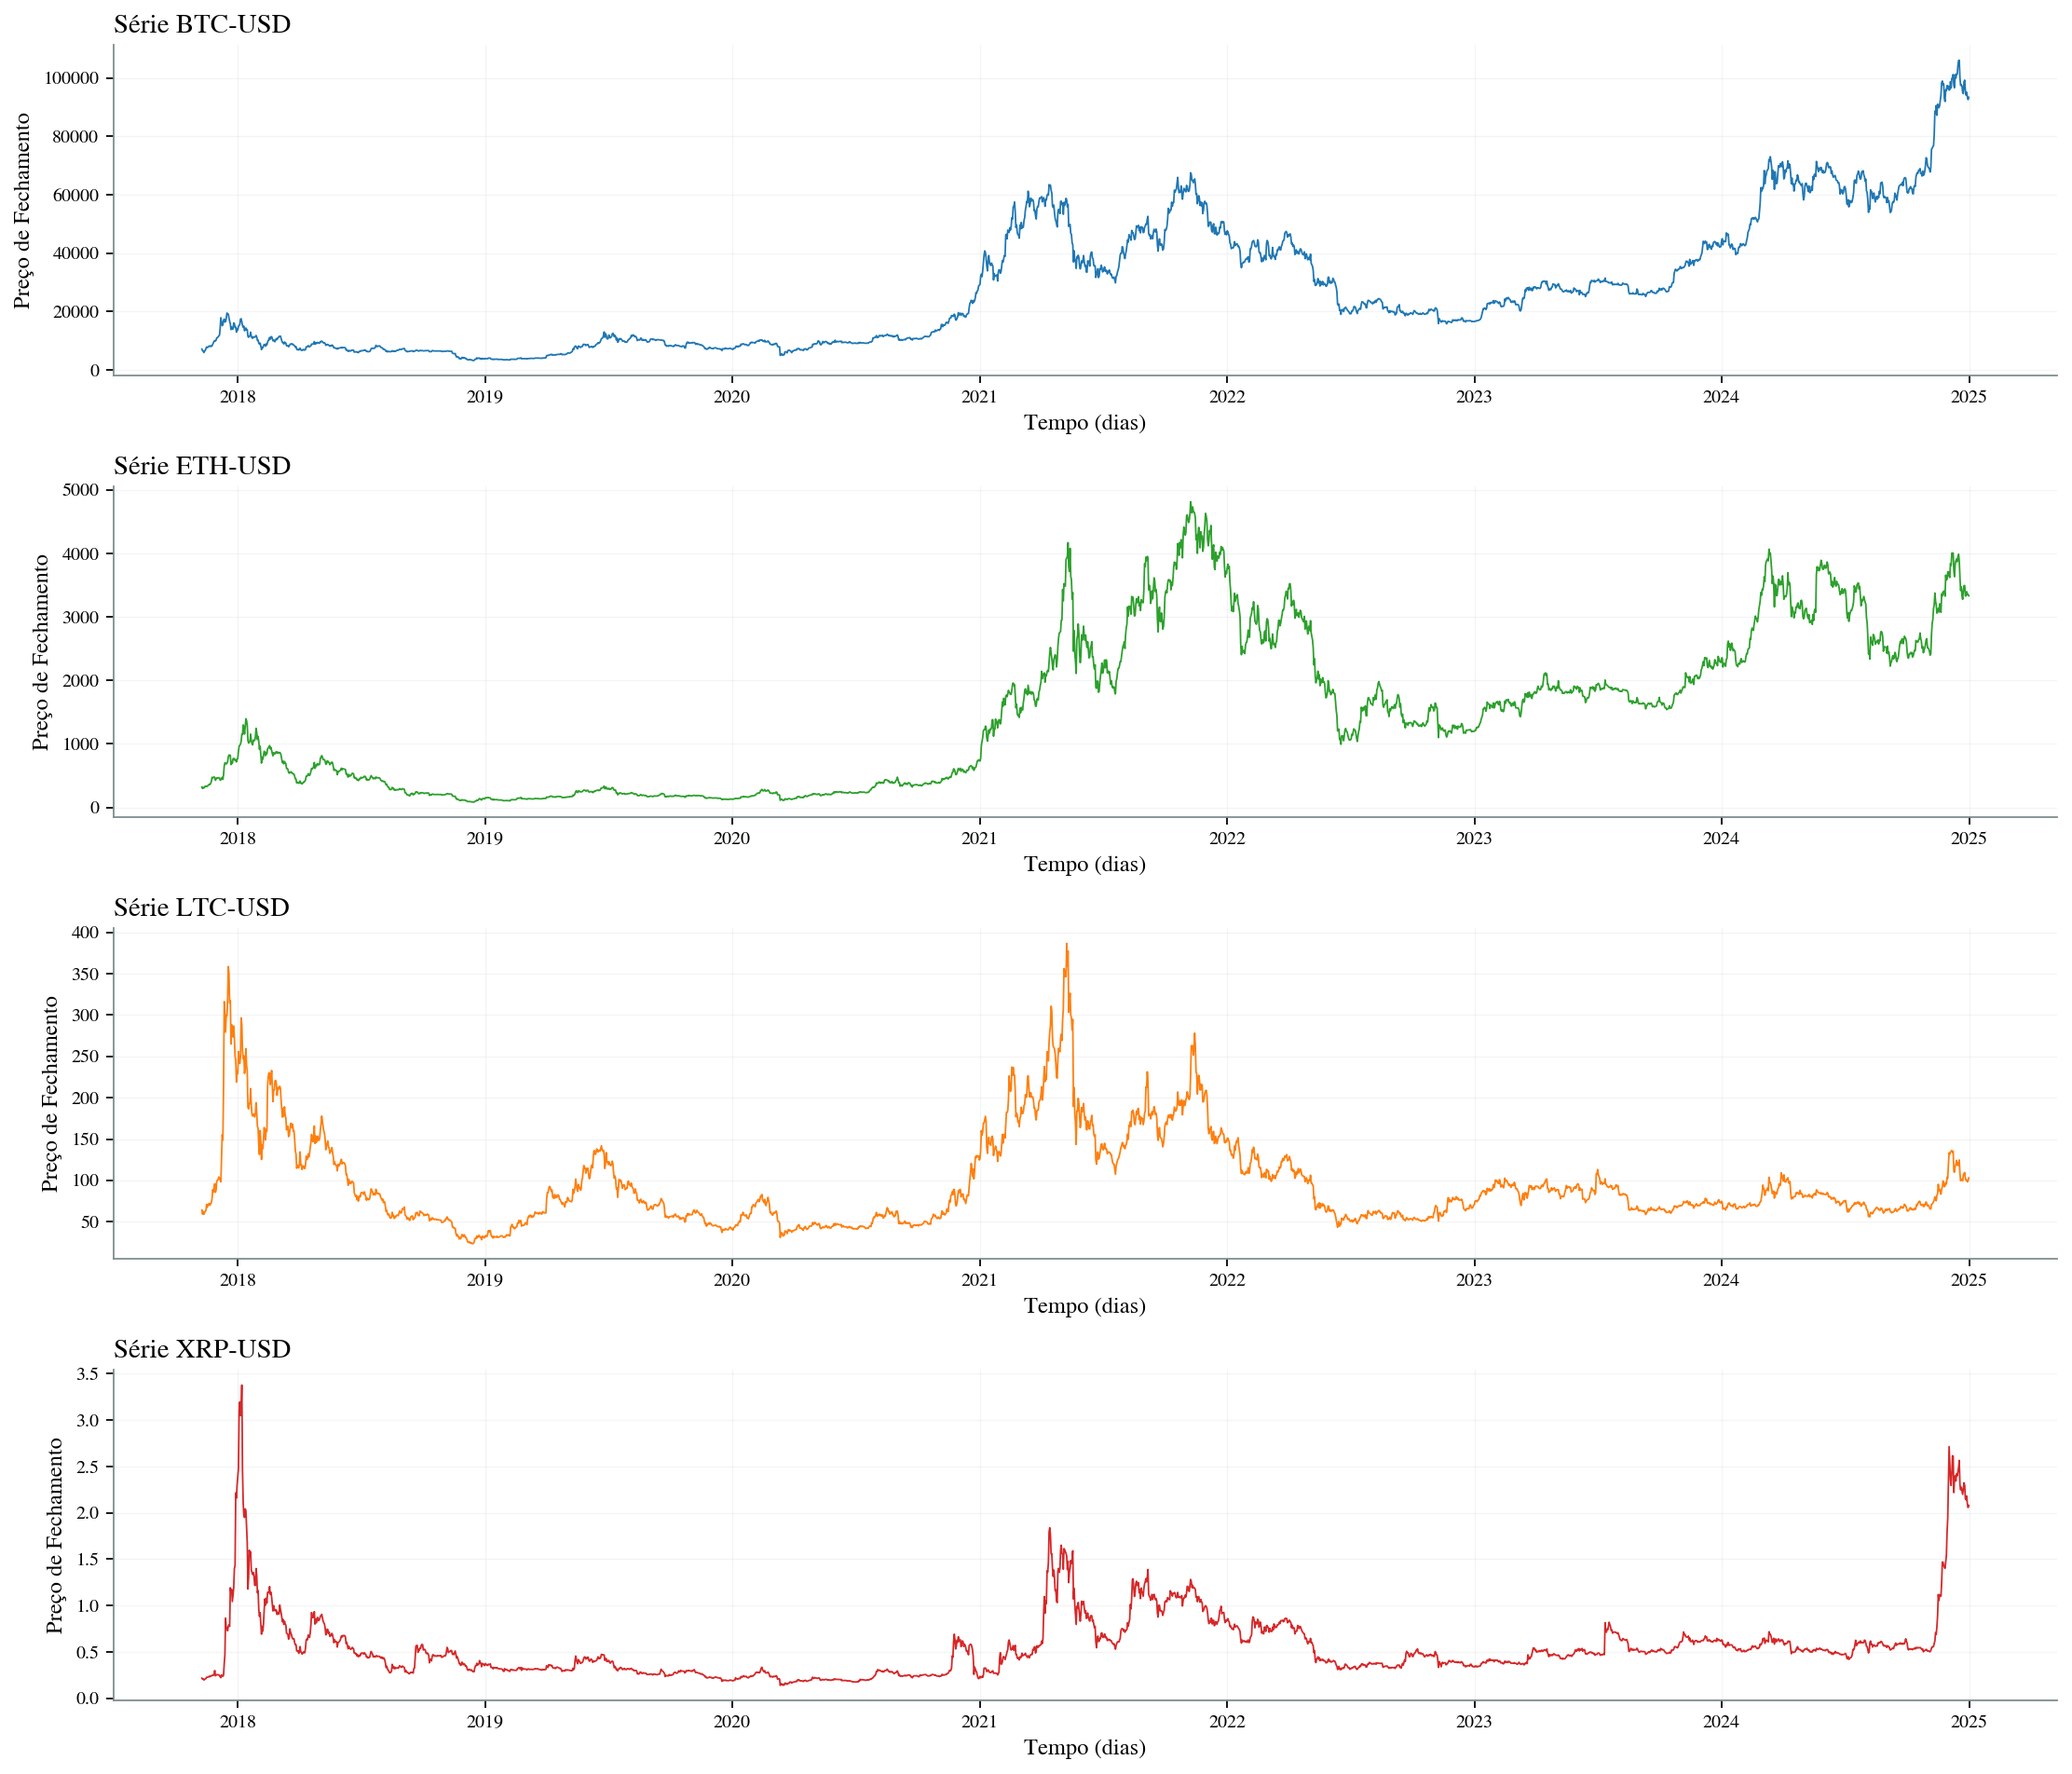

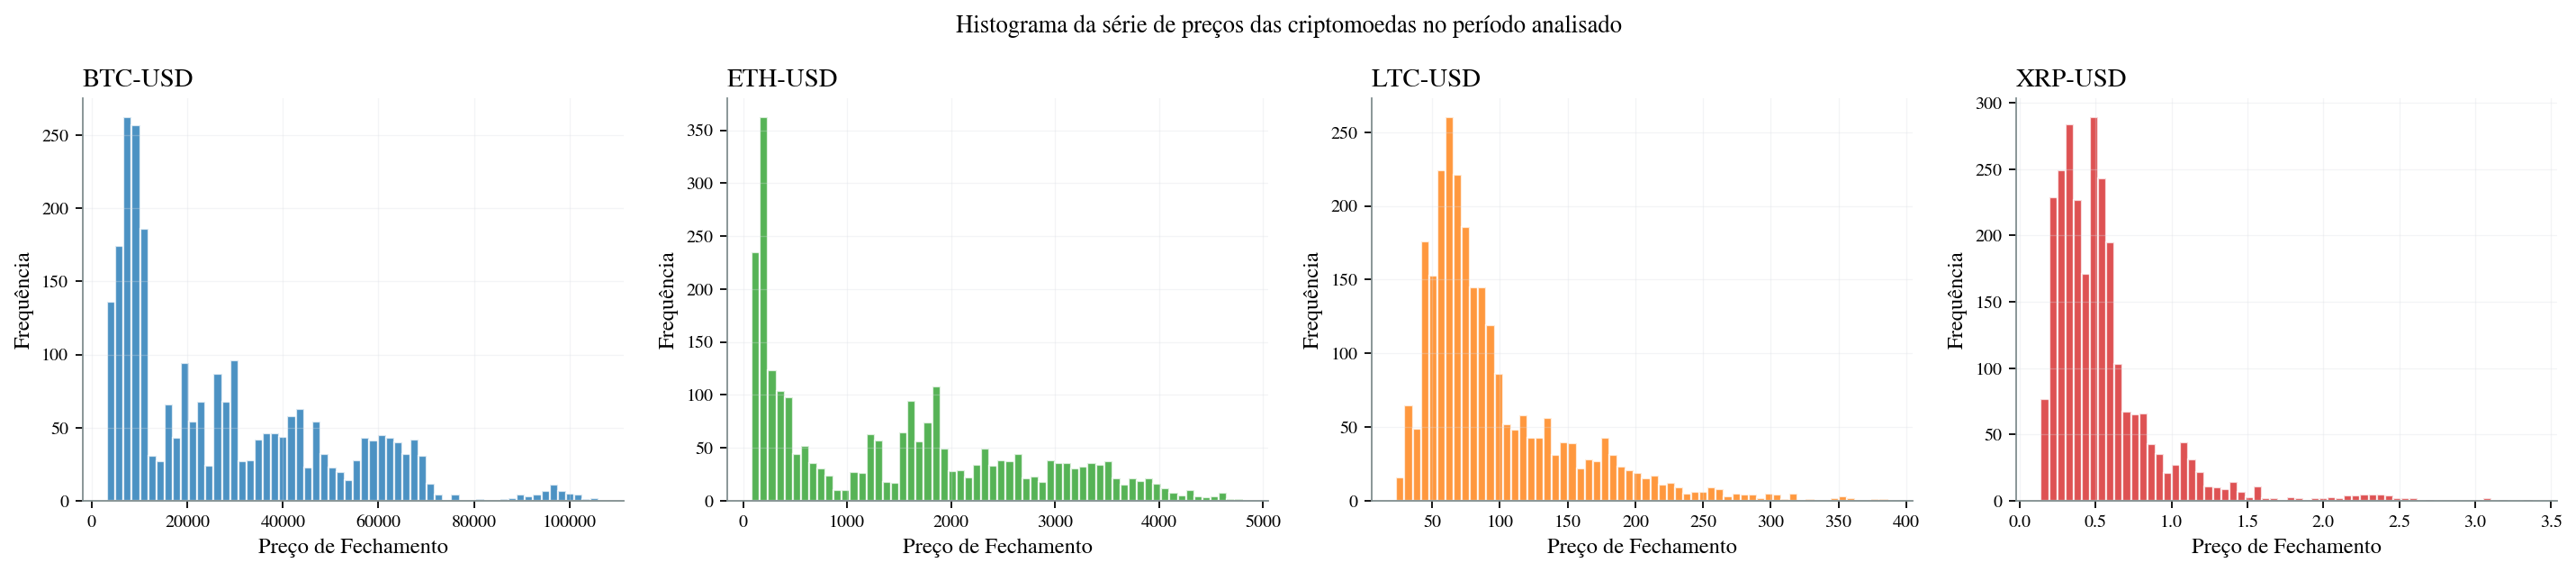

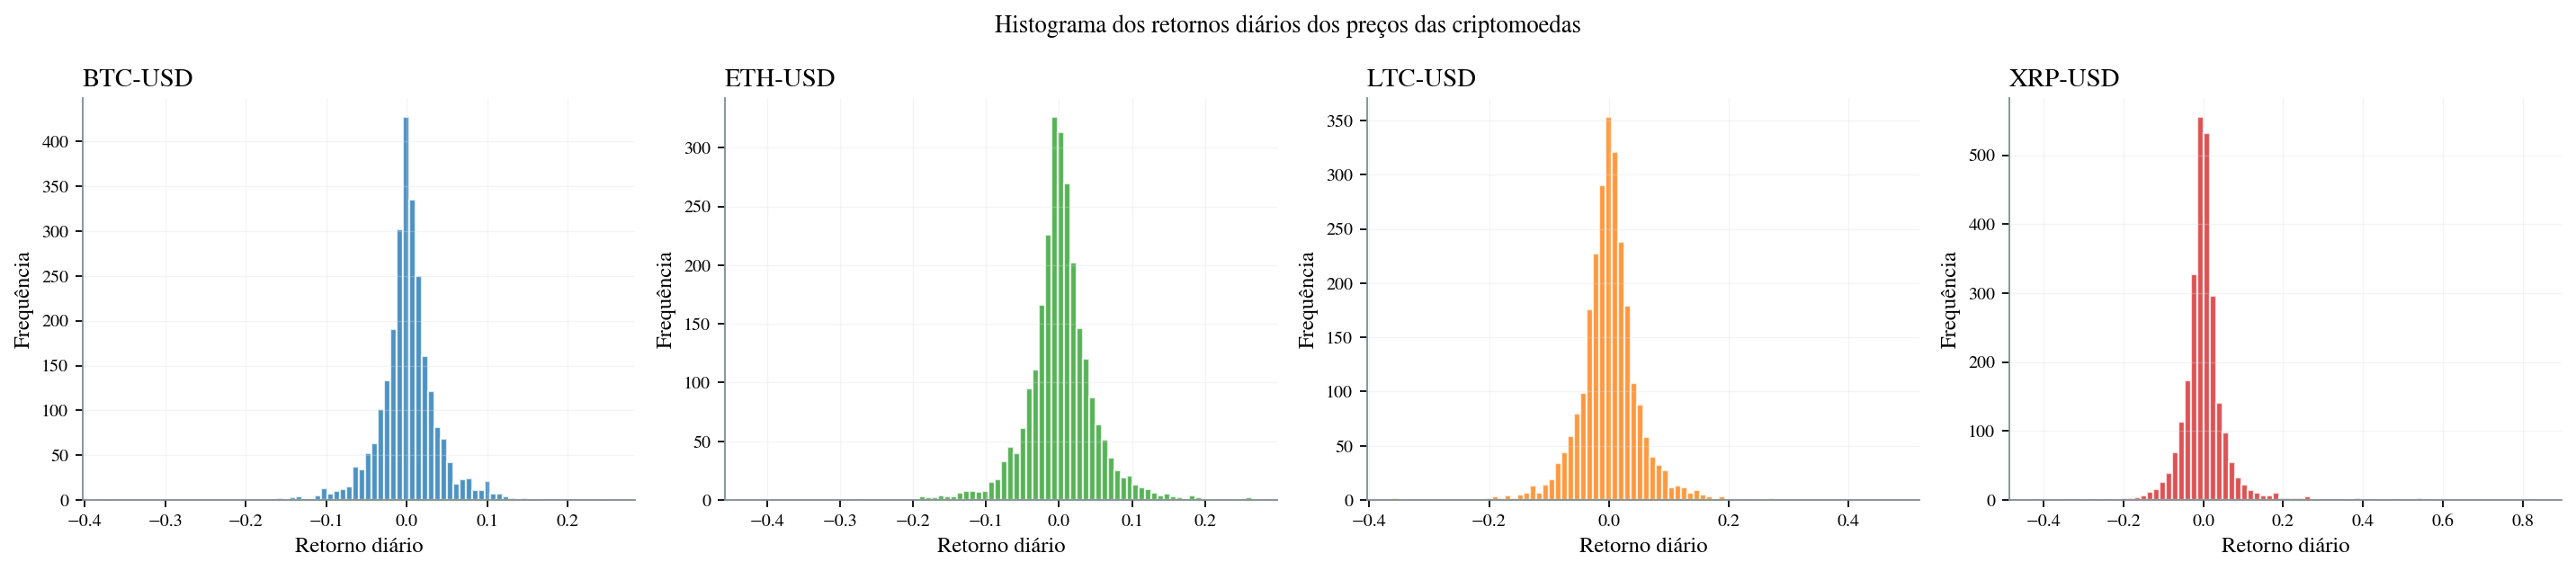

In [ ]:
# ── Figuras 1–3: séries de preços, histogramas de preços e retornos ──────────

_assets_plot = {"BTC-USD": btc, "ETH-USD": eth, "LTC-USD": ltc, "XRP-USD": xrp}
_colors      = ["tab:blue", "tab:green", "tab:orange", "tab:red"]

# Figura 1 – Séries temporais de preços
fig1, axes1 = plt.subplots(4, 1, figsize=(14, 12), sharex=False)
for ax, (name, s), color in zip(axes1, _assets_plot.items(), _colors):
    ax.plot(s.index, s.values, color=color, linewidth=0.8)
    ax.set_title(f"Série {name}")
    ax.set_ylabel("Preço de Fechamento")
    ax.set_xlabel("Tempo (dias)")
    ax.grid(True, alpha=0.3)
fig1.tight_layout()
save_thesis_figure(fig1, "price_fig_series_prices")
plt.show()

# Figura 2 – Histograma dos preços
fig2, axes2 = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, s), color in zip(axes2, _assets_plot.items(), _colors):
    ax.hist(s.dropna().values, bins=60, color=color, alpha=0.8, edgecolor="white")
    ax.set_title(name)
    ax.set_xlabel("Preço de Fechamento")
    ax.set_ylabel("Frequência")
    ax.grid(True, alpha=0.3)
fig2.suptitle("Histograma da série de preços das criptomoedas no período analisado")
fig2.tight_layout()
save_thesis_figure(fig2, "price_fig_histogram_prices")
plt.show()

# Figura 3 – Histograma dos retornos diários
_returns = {name: s.pct_change().dropna() for name, s in _assets_plot.items()}
fig3, axes3 = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, r), color in zip(axes3, _returns.items(), _colors):
    ax.hist(r.values, bins=80, color=color, alpha=0.8, edgecolor="white")
    ax.set_title(name)
    ax.set_xlabel("Retorno diário")
    ax.set_ylabel("Frequência")
    ax.grid(True, alpha=0.3)
fig3.suptitle("Histograma dos retornos diários dos preços das criptomoedas")
fig3.tight_layout()
save_thesis_figure(fig3, "price_fig_histogram_returns")
plt.show()


In [ ]:
def prepare_price_series(price_series, name="series"):
    """Valida e retorna a série de preços sem transformação.
    Preços são I(1) — a modelagem é feita diretamente em nível (d=1 para ARIMA).
    """
    s = pd.Series(price_series, name=name).copy()
    s = s.sort_index().dropna()

    if s.empty:
        raise ValueError(f"{name}: a série ficou vazia após ordenação e remoção de NaN.")

    if (s <= 0).any():
        raise ValueError(f"{name}: todos os valores devem ser positivos (série de preços).")

    s.name = "price"
    return s


In [ ]:
def build_multiasset_price_map(asset_map):
    """Constrói mapa {ticker: série de preços} validada."""
    price_map = {}
    for asset, series in asset_map.items():
        price = prepare_price_series(series, name=asset)
        price_map[asset] = price
        print(f"{asset}: n_prices={len(price)}")
    return price_map


In [ ]:
def comparison_protocol_summary(price_map, horizons=None, train_frac=0.8):
    if not 0 < train_frac < 1:
        raise ValueError("train_frac deve estar estritamente entre 0 e 1.")

    if horizons is not None:
        resolved_horizons = tuple(horizons) if not isinstance(horizons, (int, np.integer)) else (int(horizons),)
        print(f"Usando horizons informado: {resolved_horizons}")
    else:
        resolved_horizons = (1, 7, 14)
        print("Usando horizons padrão da comparação principal: (1, 7, 14)")

    rows = []
    for asset, price in price_map.items():
        n_obs = len(price)
        train_size = int(np.floor(n_obs * train_frac))
        test_size = n_obs - train_size
        rows.append({
            "asset": asset,
            "n_obs": n_obs,
            "train_size": train_size,
            "test_size": test_size,
            "target": "price (nivel)",
            "candidate_families": "ARIMA(d=1), ETS, LSTM, RNN, GRU",
            "horizons_used": resolved_horizons,
        })

    return pd.DataFrame(rows)


asset_map_compare = {
    "BTC-USD": btc,
    "ETH-USD": eth,
    "LTC-USD": ltc,
    "XRP-USD": xrp,
}

price_map = build_multiasset_price_map(asset_map_compare)
comparison_protocol_table = comparison_protocol_summary(price_map)
display(comparison_protocol_table)


BTC-USD: n_prices=2610
ETH-USD: n_prices=2610
LTC-USD: n_prices=2610
XRP-USD: n_prices=2610
Usando horizons padrão da comparação principal: (1, 7, 14)


,asset,n_obs,train_size,test_size,target,candidate_families,horizons_used
0,BTC-USD,2610,2088,522,price (nivel),"ARIMA(d=1), ETS, LSTM, RNN, GRU","(1, 7, 14)"
1,ETH-USD,2610,2088,522,price (nivel),"ARIMA(d=1), ETS, LSTM, RNN, GRU","(1, 7, 14)"
2,LTC-USD,2610,2088,522,price (nivel),"ARIMA(d=1), ETS, LSTM, RNN, GRU","(1, 7, 14)"
3,XRP-USD,2610,2088,522,price (nivel),"ARIMA(d=1), ETS, LSTM, RNN, GRU","(1, 7, 14)"


## Justificativa para comparação principal em preços

A comparação principal é conduzida em **preços** (série no nível), alinhada com a especificação do texto do trabalho (ARIMA com d=1). Preços de criptoativos são processos I(1) — possuem raiz unitária no nível e tornam-se estacionários após uma diferenciação. Esta seção documenta a análise de estacionariedade que justifica d=1 no ARIMA e a escolha de modelar o nível.

### Protocolo comparativo
| Item | Detalhe |
|------|---------|
| Alvo | Preço de fechamento diário (USD) |
| Horizonte | h ∈ {1, 7, 14} dias |
| Split | 80% treino / 20% teste (walk-forward) |
| Famílias | ARIMA(p,1,q), ETS (grid-search), LSTM, RNN, GRU |
| Métricas | RMSE, MAE, MAPE, sMAPE, Theil U1, Theil U2, DA |


=== Stationarity Report: BTC-USD ===
Sample size: 2610
ADF Test:
  Statistic : -0.3188
  p-value   : 0.9228
  Lags used : 28
  Result    : Non-stationary (p >= 0.05)
KPSS Test:
  Statistic : 5.0319
  p-value   : 0.0100
  Lags used : 30
  Result    : Non-stationary (p <= 0.05)


/tmp/ipykernel_800/504004575.py:25: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_p, kpss_lags, _ = kpss(s, regression="c", nlags="auto")


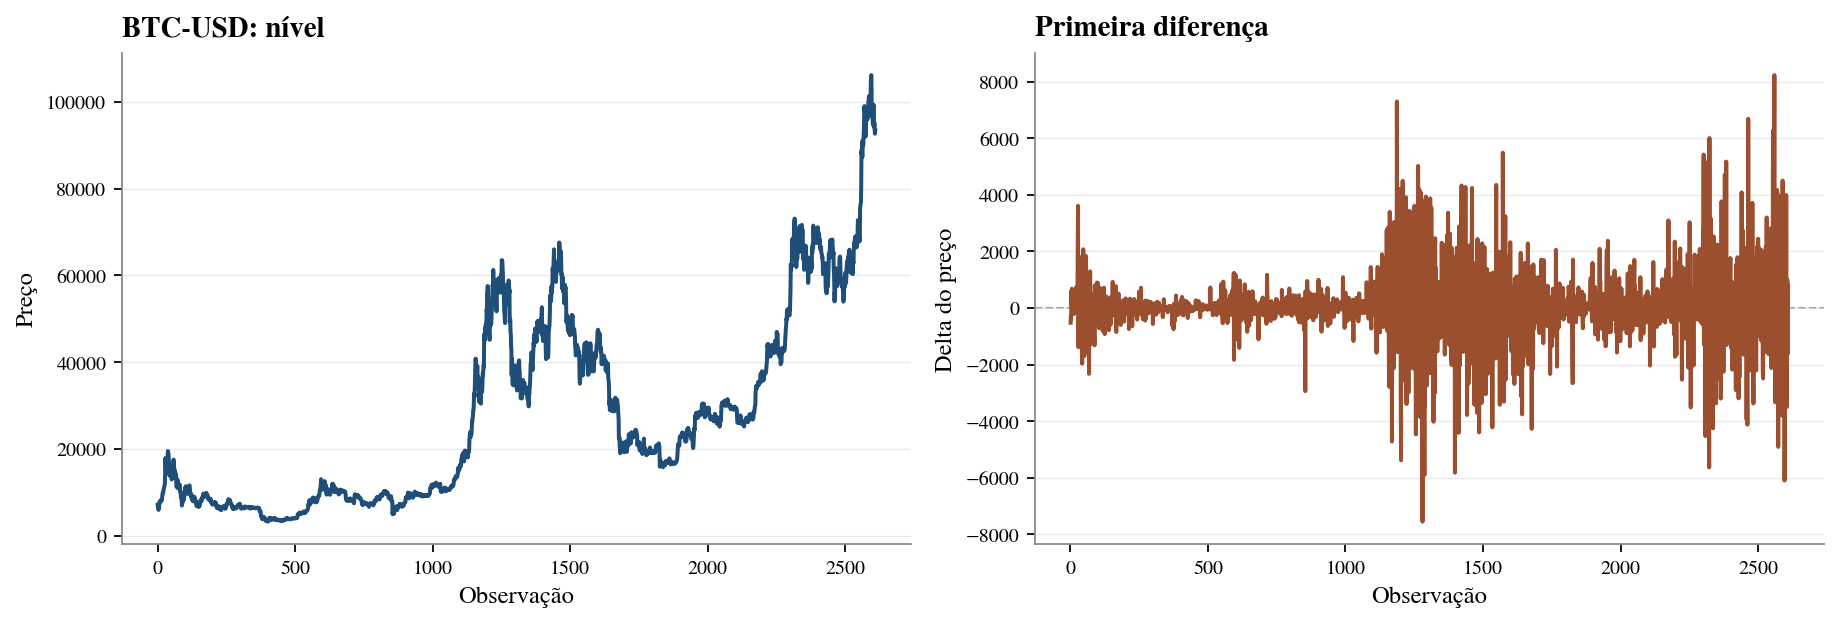

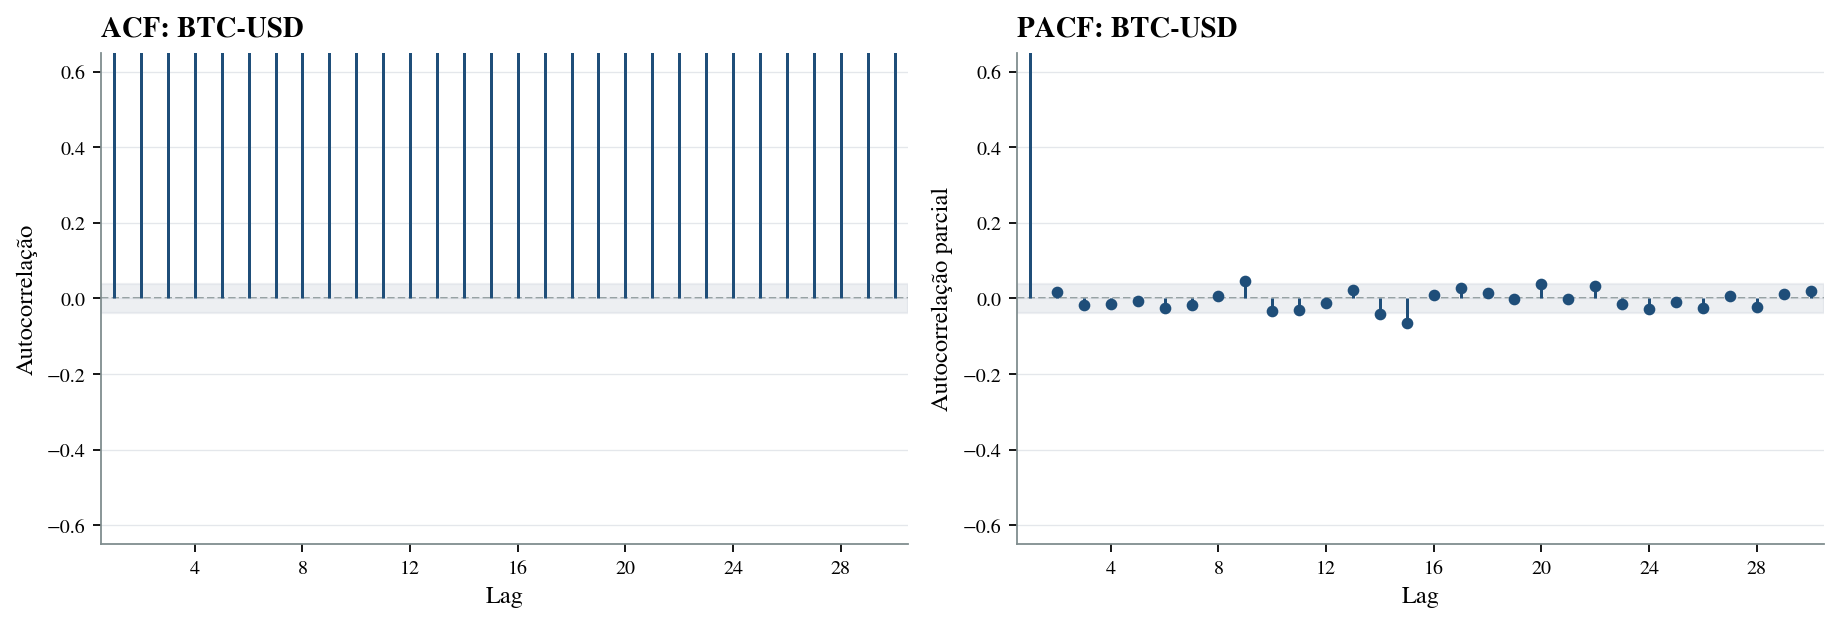

Integration order analysis: BTC-USD
-- Level --
  ADF p-value: 0.9228 -> Non-stationary
-- First Difference --
  ADF p-value: 0.0000 -> Stationary
-- Conclusion --
  Suggested integration order: d = 1


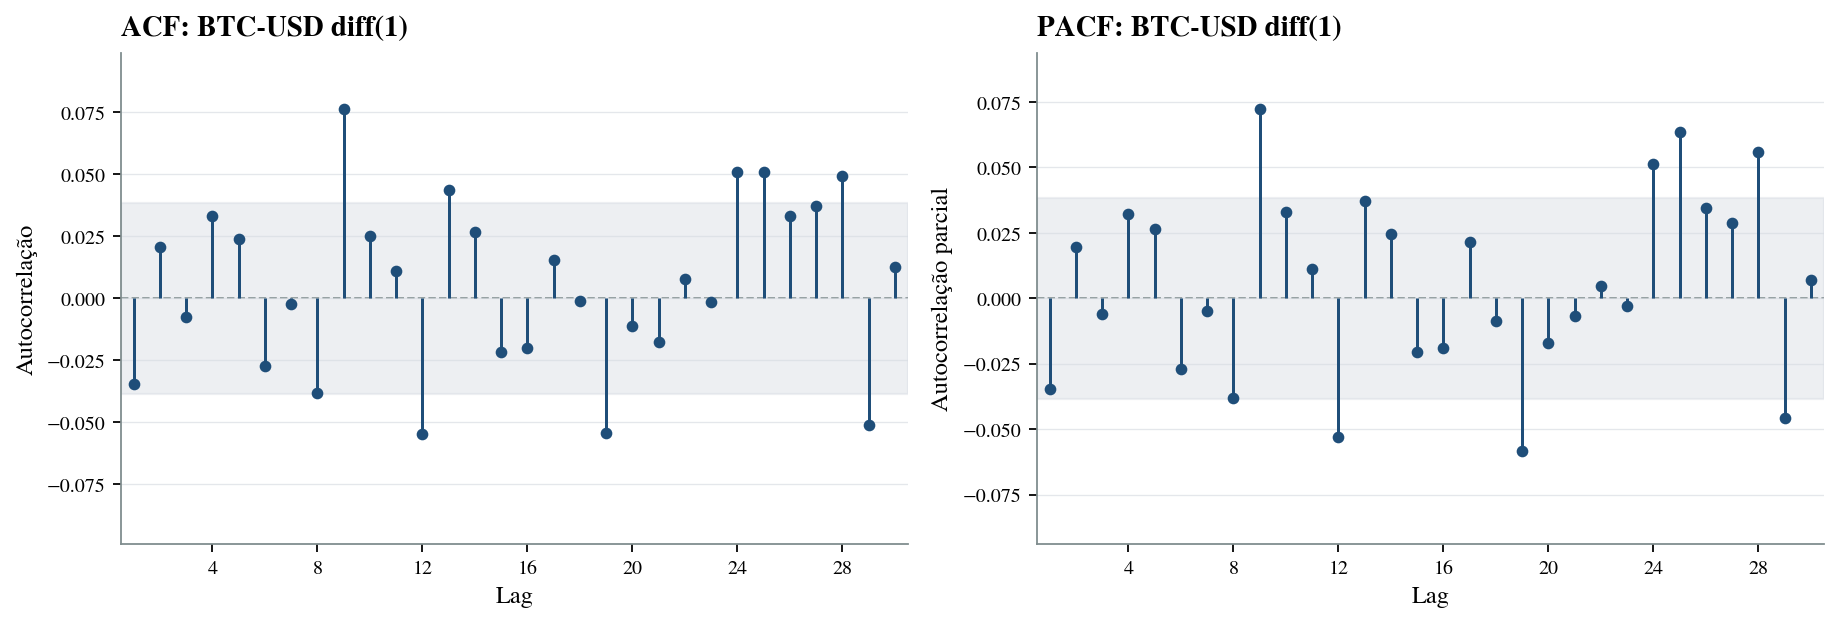

=== compare_price_diff_vs_log_return: BTC-USD ===
--- First Difference (n=2609) ---
  ADF  : stat=-8.2200  p=0.0000  lags=28  -> Stationary
  KPSS : stat=0.2336  p=0.1000  lags=9  -> Stationary
--- Log Return (n=2609) ---


/tmp/ipykernel_800/504004575.py:127: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, kpss_lags, _ = kpss(ts, regression="c", nlags="auto")


  ADF  : stat=-35.1699  p=0.0000  lags=1  -> Stationary
  KPSS : stat=0.0870  p=0.1000  lags=10  -> Stationary


/tmp/ipykernel_800/504004575.py:127: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, kpss_lags, _ = kpss(ts, regression="c", nlags="auto")


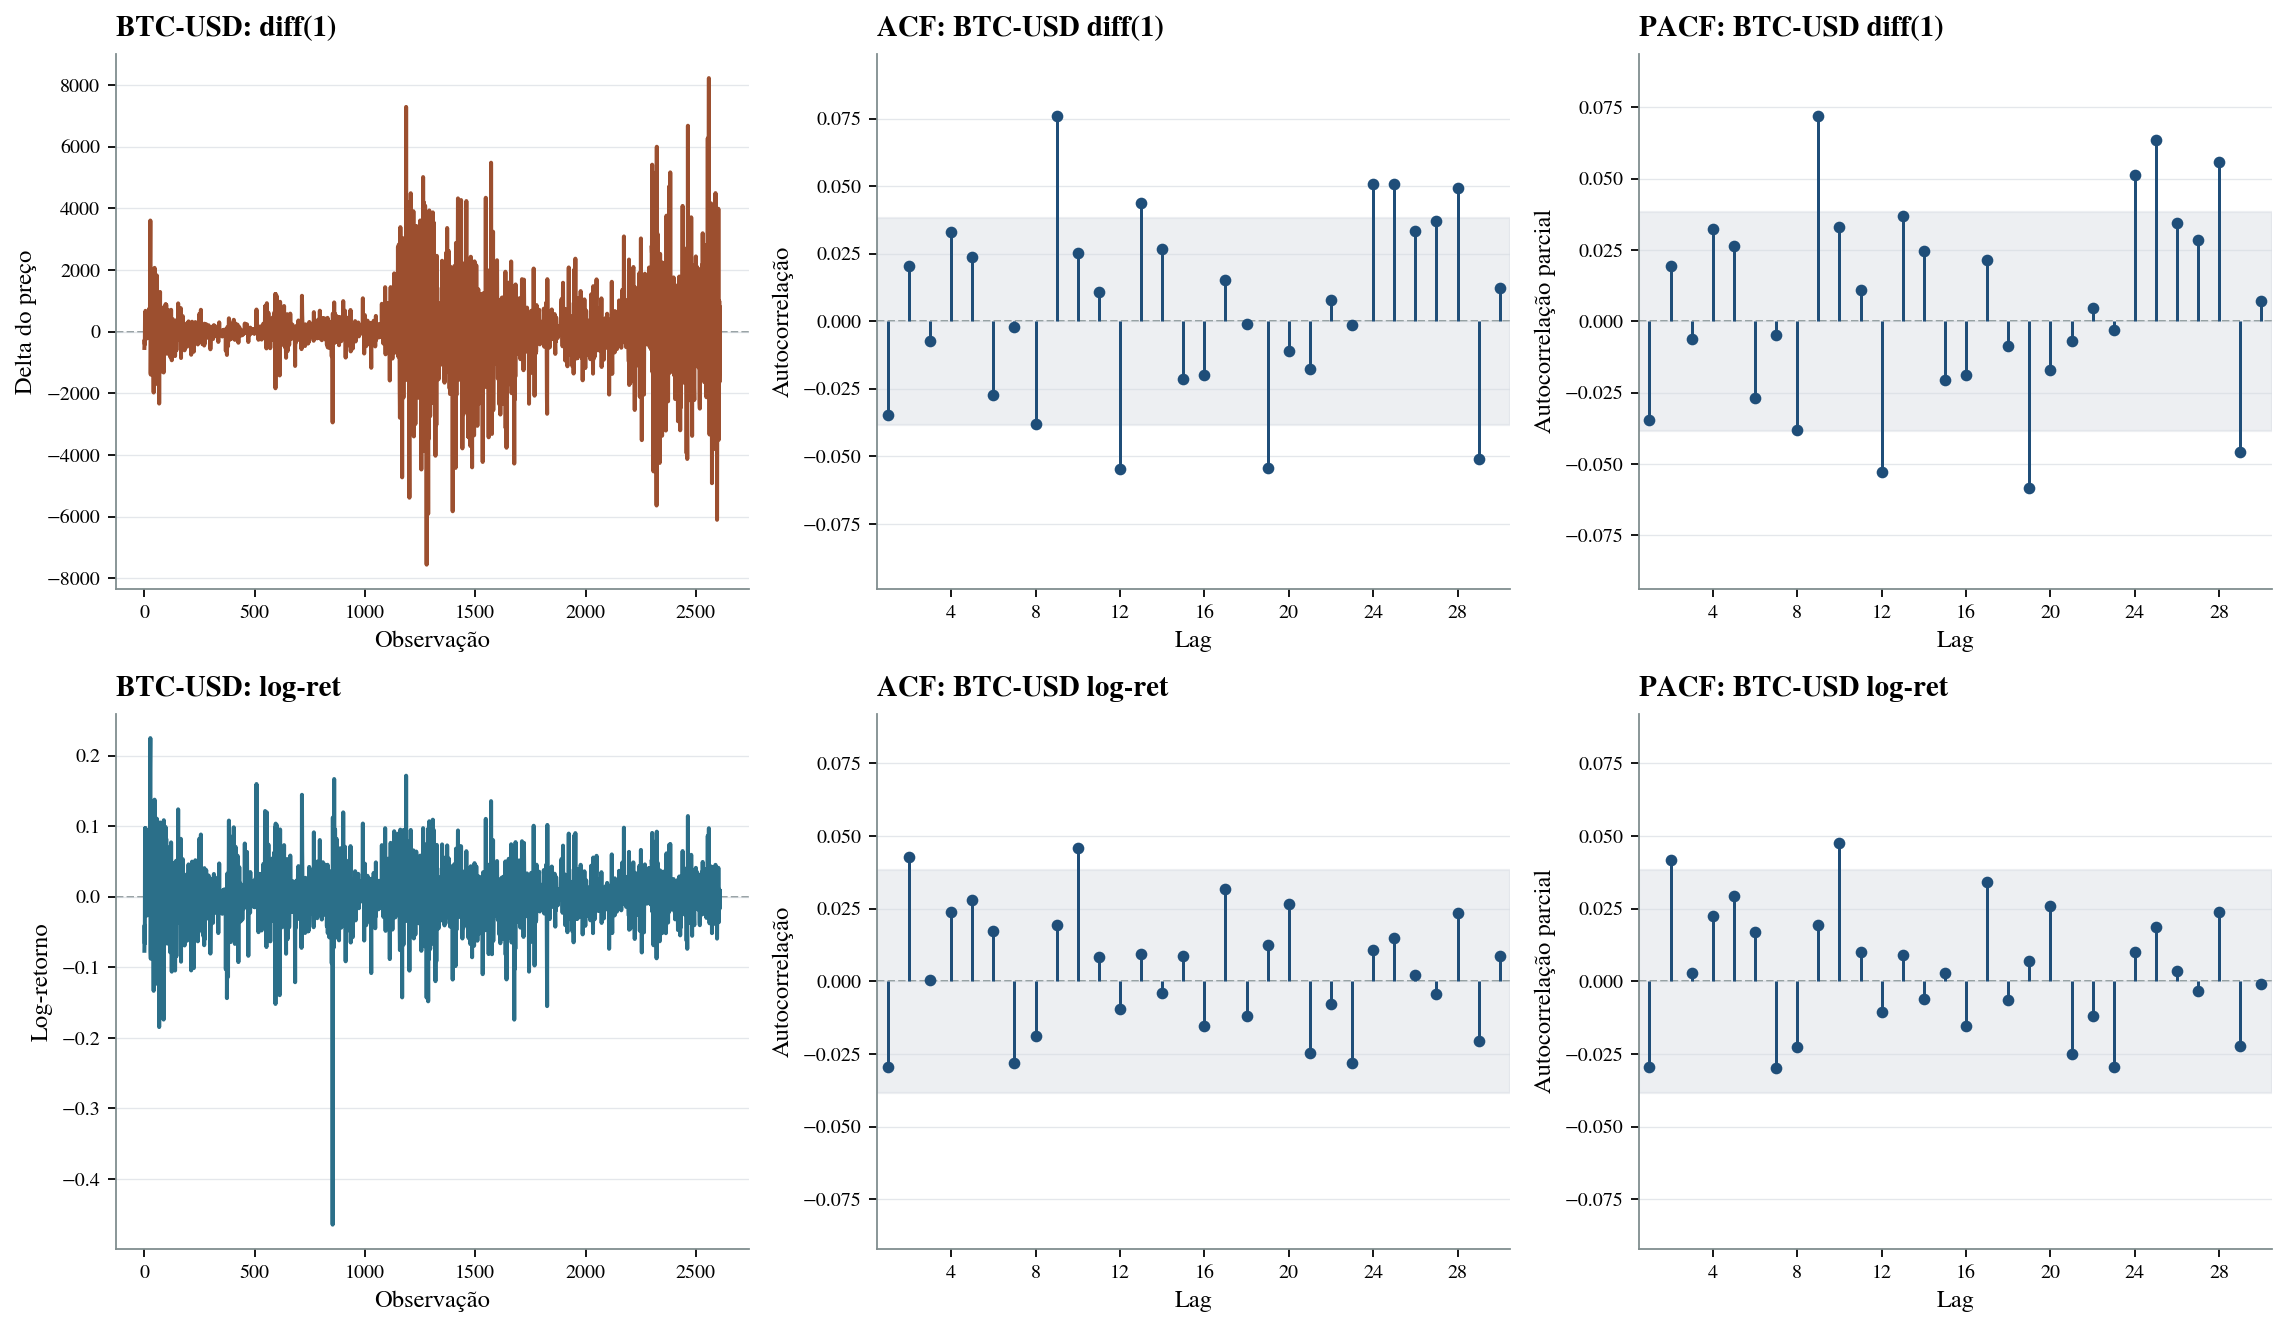

=== IC Grid: BTC-USD (diff1) (d=0) ===
Top 10 by BIC:
    order          aic          bic  nobs
(0, 0, 0) 44089.314945 44101.048389  2609
(1, 0, 0) 44088.180066 44105.780233  2609
(0, 0, 1) 44088.302059 44105.902226  2609
(1, 0, 1) 44088.951136 44112.418025  2609
(2, 0, 0) 44089.187708 44112.654597  2609
(0, 0, 2) 44089.301775 44112.768664  2609
(1, 0, 2) 44089.425691 44118.759302  2609
(2, 0, 1) 44090.892908 44120.226520  2609
(3, 0, 0) 44091.094602 44120.428213  2609
(0, 0, 3) 44091.220180 44120.553792  2609
Top 10 by AIC:
    order          aic          bic  nobs
(1, 0, 0) 44088.180066 44105.780233  2609
(0, 0, 1) 44088.302059 44105.902226  2609
(3, 0, 3) 44088.601993 44135.535772  2609
(1, 0, 1) 44088.951136 44112.418025  2609
(2, 0, 0) 44089.187708 44112.654597  2609
(0, 0, 2) 44089.301775 44112.768664  2609
(0, 0, 0) 44089.314945 44101.048389  2609
(1, 0, 2) 44089.425691 44118.759302  2609
(2, 0, 2) 44090.681072 44125.881406  2609
(2, 0, 1) 44090.892908 44120.226520  2609
=== IC 

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

# ---- Diagnostico de Estacionariedade ----

def stationarity_report(series, name="series"):
    s = pd.Series(series.values if hasattr(series, "values") else series).dropna()
    print(f"=== Stationarity Report: {name} ===")
    print(f"Sample size: {len(s)}")

    # ADF
    adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")
    adf_interp = "Stationary (p < 0.05)" if adf_p < 0.05 else "Non-stationary (p >= 0.05)"
    print("ADF Test:")
    print(f"  Statistic : {adf_stat:.4f}")
    print(f"  p-value   : {adf_p:.4f}")
    print(f"  Lags used : {adf_lags}")
    print(f"  Result    : {adf_interp}")

    # KPSS
    print("KPSS Test:")
    try:
        kpss_stat, kpss_p, kpss_lags, _ = kpss(s, regression="c", nlags="auto")
        kpss_interp = "Stationary (p > 0.05)" if kpss_p > 0.05 else "Non-stationary (p <= 0.05)"
        print(f"  Statistic : {kpss_stat:.4f}")
        print(f"  p-value   : {kpss_p:.4f}")
        print(f"  Lags used : {kpss_lags}")
        print(f"  Result    : {kpss_interp}")
    except Exception as e:
        print(f"  KPSS could not be computed: {e}")


def plot_series_and_differences(series, name="series"):
    fig = plot_series_and_differences_thesis(series, name=name)
    save_thesis_figure(fig, f"price_fig_series_diff_{name.replace('-', '_')}")
    plt.show()
    return fig


def plot_acf_pacf_diagnostics(series, name="series", lags=30):
    s = pd.Series(series.values if hasattr(series, "values") else series).dropna()
    max_lags = min(lags, len(s) // 2 - 1)
    if max_lags < 1:
        print(f"{name}: series too short to plot ACF/PACF (n={len(s)})")
        return
    try:
        fig = plot_acf_pacf_diagnostics_thesis(s, name=name, lags=lags)
        save_thesis_figure(fig, f"price_fig_acf_pacf_{name.replace('-', '_')}")
        plt.show()
        return fig
    except Exception as e:
        print(f"{name}: ACF/PACF plot failed - {e}")


# ---- Rodando diagnostico na serie principal (BTC-USD) ----
stationarity_report(btc, name="BTC-USD")
plot_series_and_differences(btc, name="BTC-USD")
plot_acf_pacf_diagnostics(btc, name="BTC-USD", lags=30)


def compare_integration_orders(series, name="series"):
    s = pd.Series(series.values if hasattr(series, "values") else series).dropna()
    diff1 = s.diff().dropna()

    print("=" * 50)
    print(f"Integration order analysis: {name}")
    print("=" * 50)

    print("-- Level --")
    adf_stat_l, adf_p_l, adf_lags_l, *_ = adfuller(s, autolag="AIC")
    level_stationary = adf_p_l < 0.05
    level_label = "Stationary" if level_stationary else "Non-stationary"
    print(f"  ADF p-value: {adf_p_l:.4f} -> {level_label}")

    print("-- First Difference --")
    adf_stat_d, adf_p_d, adf_lags_d, *_ = adfuller(diff1, autolag="AIC")
    diff_stationary = adf_p_d < 0.05
    diff_label = "Stationary" if diff_stationary else "Non-stationary"
    print(f"  ADF p-value: {adf_p_d:.4f} -> {diff_label}")

    print("-- Conclusion --")
    if not level_stationary and diff_stationary:
        print("  Suggested integration order: d = 1")
    else:
        print("  Suggested integration order requires further review")


def plot_differenced_acf_pacf(series, name="series", lags=30):
    s = pd.Series(series.values if hasattr(series, "values") else series).dropna()
    diff1 = s.diff().dropna()
    max_lags = min(lags, len(diff1) // 2 - 1)
    if max_lags < 1:
        print(f"{name} (diff): series too short to plot ACF/PACF (n={len(diff1)})")
        return
    try:
        fig = plot_differenced_acf_pacf_thesis(s, name=name, lags=lags)
        save_thesis_figure(fig, f"price_fig_diff_acf_pacf_{name.replace('-', '_')}")
        plt.show()
        return fig
    except Exception as e:
        print(f"{name} (diff): ACF/PACF plot failed - {e}")


compare_integration_orders(btc, name="BTC-USD")
plot_differenced_acf_pacf(btc, name="BTC-USD", lags=30)


def compare_price_diff_vs_log_return(series, name="series", lags=30):
    s = pd.Series(series.values if hasattr(series, "values") else series).dropna()
    diff1 = s.diff().dropna()

    has_log = (s > 0).all()
    if has_log:
        log_ret = np.log(s).diff().dropna()
    else:
        print(f"{name}: series contains non-positive values; log-return skipped")
        log_ret = None

    def _run_tests(ts, label):
        print(f"--- {label} (n={len(ts)}) ---")
        adf_stat, adf_p, adf_lags, *_ = adfuller(ts, autolag="AIC")
        adf_res = "Stationary" if adf_p < 0.05 else "Non-stationary"
        print(f"  ADF  : stat={adf_stat:.4f}  p={adf_p:.4f}  lags={adf_lags}  -> {adf_res}")
        try:
            kpss_stat, kpss_p, kpss_lags, _ = kpss(ts, regression="c", nlags="auto")
            kpss_res = "Stationary" if kpss_p > 0.05 else "Non-stationary"
            print(f"  KPSS : stat={kpss_stat:.4f}  p={kpss_p:.4f}  lags={kpss_lags}  -> {kpss_res}")
        except Exception as e:
            print(f"  KPSS could not be computed: {e}")

    print(f"=== compare_price_diff_vs_log_return: {name} ===")
    _run_tests(diff1, "First Difference")
    if log_ret is not None:
        _run_tests(log_ret, "Log Return")

    fig = compare_price_diff_vs_log_return_thesis(s, name=name, lags=lags)
    save_thesis_figure(fig, f"price_fig_diff_vs_logret_{name.replace('-', '_')}")
    plt.show()
    return fig


compare_price_diff_vs_log_return(btc, name="BTC-USD", lags=30)


def arima_information_criteria_grid(series, name="series", max_p=3, max_q=3, d=0):
    from statsmodels.tsa.arima.model import ARIMA as _ARIMA
    import warnings
    s = pd.Series(series.values if hasattr(series, "values") else series).dropna()
    records = []
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    res = _ARIMA(s, order=(p, d, q)).fit()
                records.append({"order": (p, d, q), "aic": res.aic, "bic": res.bic, "nobs": int(res.nobs)})
            except Exception as e:
                records.append({"order": (p, d, q), "aic": float("nan"), "bic": float("nan"), "nobs": None})
    df_ic = pd.DataFrame(records)
    df_ic_valid = df_ic.dropna(subset=["bic"])
    df_bic = df_ic_valid.sort_values("bic").reset_index(drop=True)
    df_aic = df_ic_valid.sort_values("aic").reset_index(drop=True)
    print(f"=== IC Grid: {name} (d={d}) ===")
    print("Top 10 by BIC:")
    print(df_bic.head(10).to_string(index=False))
    print("Top 10 by AIC:")
    print(df_aic.head(10).to_string(index=False))
    return df_bic


def compare_arima_ic_for_diff_and_logret(series, name="series", max_p=3, max_q=3):
    s = pd.Series(series.values if hasattr(series, "values") else series).dropna()
    diff1 = s.diff().dropna()

    ic_diff1 = arima_information_criteria_grid(diff1, name=name + " (diff1)", max_p=max_p, max_q=max_q, d=0)

    ic_logret = None
    if (s > 0).all():
        log_ret = np.log(s).diff().dropna()
        ic_logret = arima_information_criteria_grid(log_ret, name=name + " (log_ret)", max_p=max_p, max_q=max_q, d=0)
    else:
        print(f"{name}: non-positive values found; log-return IC grid skipped")

    print("=== Conclusion ===")
    best_diff1 = ic_diff1.iloc[0]["order"] if ic_diff1 is not None and len(ic_diff1) > 0 else None
    best_logret = ic_logret.iloc[0]["order"] if ic_logret is not None and len(ic_logret) > 0 else None
    print(f"  Best order by BIC for diff1   : {best_diff1}")
    print(f"  Best order by BIC for log_ret : {best_logret}")
    return ic_diff1, ic_logret


ic_diff1, ic_logret = compare_arima_ic_for_diff_and_logret(btc, name="BTC-USD", max_p=3, max_q=3)


def fit_and_diagnose_arima_candidates(
        series, name="series",
        candidate_orders=None,
        ljung_box_lags=(10, 20, 30)):
    import warnings
    if candidate_orders is None:
        candidate_orders = [(0, 0, 0), (1, 0, 0), (0, 0, 1), (2, 0, 0)]
    s = pd.Series(series.values if hasattr(series, "values") else series).dropna()
    records = []
    for order in candidate_orders:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                res = ARIMA(s, order=order).fit()
            resid = pd.Series(res.resid).dropna()
            row = {
                "order": order,
                "aic": round(res.aic, 4),
                "bic": round(res.bic, 4),
                "resid_mean": round(float(resid.mean()), 6),
                "resid_std": round(float(resid.std()), 6),
            }
            lb = acorr_ljungbox(resid, lags=list(ljung_box_lags), return_df=True)
            for lag in ljung_box_lags:
                pval = lb.loc[lag, "lb_pvalue"] if lag in lb.index else float("nan")
                row[f"lb_p_lag{lag}"] = round(float(pval), 4)
            # ARCH-LM test (Engle 1982) — heterocedasticidade condicional
            try:
                arch_stat, arch_p, _, _ = het_arch(resid.values, nlags=10)
                row["arch_lm_stat"] = round(float(arch_stat), 4)
                row["arch_lm_pvalue"] = round(float(arch_p), 4)
            except Exception:
                row["arch_lm_stat"] = float("nan")
                row["arch_lm_pvalue"] = float("nan")
            records.append(row)
        except Exception as e:
            print(f"  ARIMA{order} failed: {e}")

    if not records:
        print(f"{name}: no models fitted successfully")
        return pd.DataFrame()

    df_diag = pd.DataFrame(records).sort_values("bic").reset_index(drop=True)

    print(f"=== ARIMA candidate diagnostics: {name} ===")
    print(df_diag.to_string(index=False))

    lb_cols = [f"lb_p_lag{lag}" for lag in ljung_box_lags]
    print("--- Assessment ---")
    for _, row in df_diag.iterrows():
        order = row["order"]
        lb_pvals = [row[c] for c in lb_cols if c in row and not pd.isna(row[c])]
        no_autocorr = all(p > 0.05 for p in lb_pvals) if lb_pvals else False
        import math
        arch_p_val = row.get("arch_lm_pvalue", float("nan"))
        has_arch = (not math.isnan(arch_p_val)) and (arch_p_val < 0.05)
        tags = []
        if _ == 0:
            tags.append("most parsimonious by BIC")
        if no_autocorr:
            tags.append("no residual autocorrelation (Ljung-Box p > 0.05)")
        if has_arch:
            tags.append(f"ARCH effects detected (arch_lm_p={arch_p_val:.4f}) — consider GARCH")
        elif not math.isnan(arch_p_val):
            tags.append(f"no ARCH effects (arch_lm_p={arch_p_val:.4f})")
        if tags:
            print(f"  ARIMA{order}: " + ", ".join(tags))

    return df_diag


# ── Execução: estacionariedade nos PREÇOS e nas diferenças ──────────────────
# Preços são I(1): ADF nao rejeita H0 (raiz unitaria)
# Primeira diferença é I(0): ADF rejeita H0 com p < 0.05
# → justifica d=1 para ARIMA em preços
for _asset, _series in price_map.items():
    compare_integration_orders(_series, name=_asset)

# Grid AIC para BTC em preços d=1 (confirma ordens p,q do texto)
s_btc_price = pd.Series(btc.values if hasattr(btc, "values") else btc).dropna()
ic_price_btc = arima_information_criteria_grid(s_btc_price, name="BTC-USD (price)", max_p=3, max_q=3, d=1)

# Diagnóstico ARIMA em primeira diferença para BTC
diff1_btc = s_btc_price.diff().dropna()
_adf_diff1 = adfuller(diff1_btc, autolag="AIC")[1]
if _adf_diff1 < 0.05:
    print(f"BTC-USD diff1 ADF p={_adf_diff1:.4f} < 0.05 -- I(0) confirmado, d=1 justificado.")
else:
    print(f"[AVISO] BTC-USD diff1 ADF p={_adf_diff1:.4f} -- verificar ordem de integração.")

diag_price_btc = fit_and_diagnose_arima_candidates(
    diff1_btc, name="BTC-USD diff1",
    candidate_orders=[(1,0,0),(1,0,1),(1,0,2),(2,0,2)]
)



## Benchmark ARIMA em preços (d=1)

O benchmark ARIMA opera no nível dos preços com d=1, consistente com a ordem de integração I(1) confirmada pelos testes ADF/KPSS. As ordens utilizadas seguem a seleção por AIC/BIC reportada no texto: **(1,1,2)** para BTC-USD e **(2,1,2)** para ETH-USD, LTC-USD e XRP-USD. A síntese multiativo é produzida na função `run_multiasset_arima_diagnostics`.


In [ ]:
# ---- Walk-forward ARIMA on price (d=1) ----
def _directional_metrics_price(y_true_s, y_pred_s, y_lag_s):
    df = pd.concat(
        [
            pd.Series(y_true_s).rename("y_true"),
            pd.Series(y_pred_s).rename("y_pred"),
            pd.Series(y_lag_s).rename("y_lag"),
        ],
        axis=1,
    ).replace([np.inf, -np.inf], np.nan).dropna()

    if df.empty:
        return {
            "accuracy": np.nan,
            "n": 0,
            "hit_up": np.nan,
            "hit_down": np.nan,
        }

    real_dir = np.sign(df["y_true"].values - df["y_lag"].values)
    pred_dir = np.sign(df["y_pred"].values - df["y_lag"].values)

    # Exclui apenas estabilidade REAL.
    # Previsão de estabilidade em um movimento real continua contando como erro.
    effective = real_dir != 0
    real_dir = real_dir[effective]
    pred_dir = pred_dir[effective]

    if len(real_dir) == 0:
        return {
            "accuracy": np.nan,
            "n": 0,
            "hit_up": np.nan,
            "hit_down": np.nan,
        }

    mask_up = real_dir == 1
    mask_down = real_dir == -1

    return {
        "accuracy": float(np.mean(pred_dir == real_dir)),
        "n": int(len(real_dir)),
        "hit_up": (
            float(np.mean(pred_dir[mask_up] == real_dir[mask_up]))
            if mask_up.any() else np.nan
        ),
        "hit_down": (
            float(np.mean(pred_dir[mask_down] == real_dir[mask_down]))
            if mask_down.any() else np.nan
        ),
    }

def walk_forward_arima_price_compare(
        series, name="series", train_frac=0.8, candidate_orders=None):
    """Walk-forward ARIMA diretamente em preços (d=1).
    Previsão h=1 iterativa; a acurácia direcional compara sign(ŷ-y_lag) vs sign(y-y_lag).
    """
    import warnings

    s = pd.Series(series).dropna()
    if not (s > 0).all():
        print(f"{name}: série contém valores não positivos")
        return pd.DataFrame(columns=["order","rmse","mae","mape","directional_accuracy","n_test"])

    if candidate_orders is None:
        # ordens do texto: (1,1,2) BTC, (2,1,2) outros; inclui benchmark
        candidate_orders = [(0,1,0),(1,1,0),(1,1,1),(1,1,2),(2,1,2)]

    split = int(len(s) * train_frac)
    train = s.iloc[:split]
    test  = s.iloc[split:]
    print(f"{name}: n={len(s)}  train={len(train)}  test={len(test)}")

    records = []
    for order in candidate_orders:
        history = list(train)
        y_pred_list = []
        y_true_list = []
        y_lag_list  = []  # preço no passo anterior (para DA)
        failed = False

        for step_idx in range(len(test)):
            actual = float(test.iloc[step_idx])
            lag    = float(history[-1])  # y_{t-1}
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    fitted = ARIMA(history, order=order).fit()
                pred = float(np.asarray(fitted.forecast(steps=1))[0])
            except Exception as e:
                print(f"ARIMA{order} falhou no step {step_idx}: {e}")
                failed = True
                break

            y_pred_list.append(pred)
            y_true_list.append(actual)
            y_lag_list.append(lag)
            history.append(actual)

        if failed or not y_pred_list:
            continue

        y_pred = np.asarray(y_pred_list, float)
        y_true = np.asarray(y_true_list, float)
        y_lag  = np.asarray(y_lag_list, float)
        rmse = float(np.sqrt(np.mean((y_pred - y_true)**2)))
        mae  = float(np.mean(np.abs(y_pred - y_true)))
        mask = y_true != 0
        mape = float(np.mean(np.abs((y_true[mask]-y_pred[mask])/y_true[mask]))*100) if mask.any() else float("nan")
        # DA: sign(ŷ - y_{t-1}) == sign(y - y_{t-1})
        da = float(np.mean(np.sign(y_pred - y_lag) == np.sign(y_true - y_lag)))

        records.append({
            "order": order,
            "rmse": round(rmse, 6),
            "mae":  round(mae, 6),
            "mape": round(mape, 4),
            "directional_accuracy": round(da, 4),
            "n_test": len(y_true),
        })

    cols = ["order","rmse","mae","mape","directional_accuracy","n_test"]
    if not records:
        print(f"{name}: nenhum modelo produziu resultados")
        return pd.DataFrame(columns=cols)

    df_wf = pd.DataFrame(records, columns=cols).sort_values("rmse").reset_index(drop=True)
    print(f"=== Walk-forward price (d=1): {name} ===")
    print(df_wf.to_string(index=False))
    return df_wf


wf_price_results = walk_forward_arima_price_compare(btc, name="BTC-USD")
wf_price_results


BTC-USD: n=2610  train=2088  test=522
=== Walk-forward price (d=1): BTC-USD ===
    order        rmse         mae   mape  directional_accuracy  n_test
(1, 1, 1) 1606.339894 1068.572561 1.8126                0.5192     522
(1, 1, 0) 1606.532308 1069.165471 1.8134                0.5249     522
(0, 1, 0) 1606.668444 1071.296419 1.8170                0.0000     522
(1, 1, 2) 1610.377959 1071.619071 1.8180                0.5096     522
(2, 1, 2) 1617.264026 1077.437350 1.8260                0.4866     522


,order,rmse,mae,mape,directional_accuracy,n_test
0,"(1, 1, 1)",1606.339894,1068.572561,1.8126,0.5192,522
1,"(1, 1, 0)",1606.532308,1069.165471,1.8134,0.5249,522
2,"(0, 1, 0)",1606.668444,1071.296419,1.8170,0.0000,522
3,"(1, 1, 2)",1610.377959,1071.619071,1.8180,0.5096,522
4,"(2, 1, 2)",1617.264026,1077.437350,1.8260,0.4866,522


In [ ]:
# ---- ARIMA selection summary for log-return diagnostics ----


def build_arima_selection_summary(ic_table, diag_table, wf_table, name="series"):
    ic = ic_table.copy() if ic_table is not None else pd.DataFrame()
    diag = diag_table.copy() if diag_table is not None else pd.DataFrame()
    wf = wf_table.copy() if wf_table is not None else pd.DataFrame()

    if "order" not in diag.columns or "order" not in wf.columns:
        raise ValueError("diag_table and wf_table must contain the column 'order'")
    if not ic.empty and "order" not in ic.columns:
        raise ValueError("ic_table must contain the column 'order'")

    ic_cols = [c for c in ["order", "aic", "bic", "nobs"] if c in ic.columns]
    diag_cols = ["order"] + [c for c in diag.columns if c not in {"order", "aic", "bic", "nobs"}]
    wf_cols = [c for c in ["order", "rmse", "mae", "directional_accuracy", "n_test"] if c in wf.columns]

    summary = diag[diag_cols].merge(wf[wf_cols], on="order", how="inner")
    if ic_cols:
        summary = summary.merge(ic[ic_cols], on="order", how="left")

    for col in ["aic", "bic", "nobs"]:
        if col not in summary.columns:
            summary[col] = np.nan

    summary["rmse_rank"] = summary["rmse"].rank(method="min", ascending=True)
    summary["mae_rank"] = summary["mae"].rank(method="min", ascending=True)
    summary["diracc_rank"] = summary["directional_accuracy"].rank(method="min", ascending=False)
    summary["bic_rank"] = summary["bic"].rank(method="min", ascending=True)

    lb_cols = sorted(c for c in summary.columns if c.startswith("lb_p_lag"))
    if lb_cols:
        summary["residual_ok"] = (summary[lb_cols] > 0.05).sum(axis=1) >= 2
    else:
        summary["residual_ok"] = False

    baseline_mask = summary["order"] == (0, 0, 0)
    baseline_rmse = summary.loc[baseline_mask, "rmse"].dropna()
    if len(baseline_rmse) > 0 and float(baseline_rmse.iloc[0]) != 0.0:
        baseline_value = float(baseline_rmse.iloc[0])
        summary["rmse_gain_vs_000"] = 100.0 * (baseline_value - summary["rmse"]) / baseline_value
    else:
        summary["rmse_gain_vs_000"] = np.nan

    rank_cols = ["rmse_rank", "mae_rank", "diracc_rank", "bic_rank"]
    for col in rank_cols:
        summary[col] = summary[col].astype("Int64")

    ordered_cols = [
        "order", "aic", "bic", "nobs", "resid_mean", "resid_std",
        *lb_cols,
        "rmse", "mae", "directional_accuracy", "n_test",
        "rmse_rank", "mae_rank", "diracc_rank", "bic_rank",
        "residual_ok", "rmse_gain_vs_000",
    ]
    ordered_cols = [c for c in ordered_cols if c in summary.columns]
    extra_cols = [c for c in summary.columns if c not in ordered_cols]
    summary = summary[ordered_cols + extra_cols]
    summary = summary.sort_values(["rmse_rank", "bic_rank"], ascending=[True, True], na_position="last").reset_index(drop=True)

    print(f"=== ARIMA selection summary: {name} ===")
    print(summary.to_string(index=False))

    if summary.empty:
        print("Best order by RMSE: unavailable")
        print("Best order by BIC: unavailable")
        print("Conclusion: no materially relevant out-of-sample gain over the parsimonious benchmark")
        return summary

    best_rmse_row = summary.sort_values(["rmse_rank", "bic_rank"], na_position="last").iloc[0]
    print(f"Best order by RMSE: ARIMA{best_rmse_row['order']}")

    bic_valid = summary.dropna(subset=["bic"])
    bic_prefers_000 = False
    if not bic_valid.empty:
        best_bic_row = bic_valid.sort_values(["bic_rank", "rmse_rank"], na_position="last").iloc[0]
        bic_prefers_000 = best_bic_row["order"] == (0, 0, 0)
        print(f"Best order by BIC: ARIMA{best_bic_row['order']}")
    else:
        print("Best order by BIC: unavailable")

    best_gain = best_rmse_row.get("rmse_gain_vs_000", np.nan)
    if pd.notna(best_gain) and best_gain < 0.5:
        print("Conclusion: no materially relevant out-of-sample gain over the parsimonious benchmark")
        if bic_prefers_000:
            print("Preferred academic conclusion: weak linear predictability in the conditional mean")
    else:
        tech_candidates = summary[(summary["rmse_gain_vs_000"] >= 0.5) & (summary["residual_ok"])].copy()
        if not tech_candidates.empty:
            tech_row = tech_candidates.sort_values(["rmse_rank", "bic_rank"], na_position="last").iloc[0]
            print(f"Preferred technical benchmark: ARIMA{tech_row['order']}")

    return summary


arima_summary_price = build_arima_selection_summary(
    ic_price_btc,
    diag_price_btc,
    wf_price_results,
    name="BTC-USD price (d=1)",
)
try:
    display(arima_summary_price)
except NameError:
    print(arima_summary_price.to_string(index=False))


=== ARIMA selection summary: BTC-USD price (d=1) ===
Empty DataFrame
Columns: [order, aic, bic, nobs, resid_mean, resid_std, lb_p_lag10, lb_p_lag20, lb_p_lag30, rmse, mae, directional_accuracy, n_test, rmse_rank, mae_rank, diracc_rank, bic_rank, residual_ok, rmse_gain_vs_000, arch_lm_stat, arch_lm_pvalue]
Index: []
Best order by RMSE: unavailable
Best order by BIC: unavailable
Conclusion: no materially relevant out-of-sample gain over the parsimonious benchmark


,order,aic,bic,nobs,resid_mean,resid_std,lb_p_lag10,lb_p_lag20,lb_p_lag30,rmse,...,directional_accuracy,n_test,rmse_rank,mae_rank,diracc_rank,bic_rank,residual_ok,rmse_gain_vs_000,arch_lm_stat,arch_lm_pvalue


In [ ]:
# ---- Multiasset ARIMA diagnostics on price (d=1) ----


def run_multiasset_arima_diagnostics(asset_map, train_frac=0.8):
    import warnings

    # Ordens fixadas conforme texto do trabalho (seleção por AIC/BIC)
    PAPER_ORDERS = {
        "BTC-USD": (1, 1, 2),
        "ETH-USD": (2, 1, 2),
        "LTC-USD": (2, 1, 2),
        "XRP-USD": (2, 1, 2),
    }
    candidate_orders = [(0,1,0),(1,1,0),(1,1,1),(1,1,2),(2,1,2)]
    summary_records = []
    details = {}

    def _safe_pvalues(ts, asset, stage):
        ts = pd.Series(ts).dropna()
        stats = {"adf_pvalue": float("nan"), "kpss_pvalue": float("nan")}
        if ts.empty:
            return stats
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                stats["adf_pvalue"] = float(adfuller(ts, autolag="AIC")[1])
        except Exception as e:
            print(f"{asset} | {stage} ADF failed: {e}")
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                stats["kpss_pvalue"] = float(kpss(ts, regression="c", nlags="auto")[1])
        except Exception as e:
            print(f"{asset} | {stage} KPSS failed: {e}")
        return stats

    for asset, series in asset_map.items():
        print("=" * 80)
        print(f"ARIMA price diagnostics: {asset}")

        try:
            s = pd.Series(series).dropna()
        except Exception as e:
            print(f"{asset} | preprocessing failed: {e}"); continue

        if s.empty or not (s > 0).all():
            print(f"{asset} | série inválida (vazia ou valores <= 0)"); continue

        diff1 = s.diff().dropna()

        try:
            stationarity_report(s, name=asset)
            plot_series_and_differences(s, name=asset)
            plot_acf_pacf_diagnostics(s, name=asset, lags=30)
            compare_integration_orders(s, name=asset)
            plot_differenced_acf_pacf(s, name=asset, lags=30)
        except Exception as e:
            print(f"{asset} | diagnostics failed: {e}"); continue

        level_stats = _safe_pvalues(s,     asset, "level")
        diff1_stats = _safe_pvalues(diff1, asset, "diff1")

        # Confirma I(1) para preços: nível não-estacionário + diff1 estacionário
        _adf_level = level_stats.get("adf_pvalue", float("nan"))
        _adf_diff1 = diff1_stats.get("adf_pvalue", float("nan"))
        if not np.isnan(_adf_level) and not np.isnan(_adf_diff1):
            if _adf_level >= 0.05 and _adf_diff1 < 0.05:
                print(f"{asset}: nivel ADF p={_adf_level:.4f} (I(1) confirmado) -- I(0) confirmado em diff1 (d=1 justificado).")
            else:
                print(f"[AVISO] {asset}: nivel ADF p={_adf_level:.4f}, diff1 ADF p={_adf_diff1:.4f} -- verificar ordem.")

        try:
            ic_price = arima_information_criteria_grid(
                s, name=f"{asset} (price)", max_p=3, max_q=3, d=1
            )
        except Exception as e:
            print(f"{asset} | ic_grid failed: {e}"); continue

        try:
            diag_price = fit_and_diagnose_arima_candidates(
                diff1, name=f"{asset} diff1",
                candidate_orders=[(p,0,q) for (p,d,q) in candidate_orders],
            )
        except Exception as e:
            print(f"{asset} | candidate_diagnostics failed: {e}"); continue

        try:
            wf_price = walk_forward_arima_price_compare(
                s, name=asset, train_frac=train_frac, candidate_orders=candidate_orders
            )
        except Exception as e:
            print(f"{asset} | walk_forward failed: {e}"); continue

        if wf_price is None or wf_price.empty:
            print(f"{asset} | walk_forward: nenhum modelo completado"); continue

        try:
            selection_summary = build_arima_selection_summary(
                ic_price, diag_price, wf_price.rename(columns={"mape":"mape_wf","directional_accuracy":"directional_accuracy"}),
                name=f"{asset} price (d=1)",
            )
        except Exception as e:
            selection_summary = wf_price.copy()
            print(f"{asset} | selection_summary fallback: {e}")

        paper_order = PAPER_ORDERS.get(asset, (2, 1, 2))
        best_rmse_row = wf_price.sort_values("rmse").iloc[0] if not wf_price.empty else {}
        best_rmse_order = tuple(best_rmse_row.get("order", (0,1,0))) if isinstance(best_rmse_row, dict) or hasattr(best_rmse_row, "get") else (0,1,0)

        # row da ordem do texto (para comparação)
        paper_row = wf_price[wf_price["order"] == paper_order]
        paper_rmse = float(paper_row["rmse"].iloc[0]) if not paper_row.empty else float("nan")
        benchmark_row = wf_price[wf_price["order"] == (0,1,0)]
        benchmark_rmse = float(benchmark_row["rmse"].iloc[0]) if not benchmark_row.empty else float("nan")

        summary_records.append({
            "asset": asset,
            "n_obs": int(len(s)),
            "level_adf_pvalue": level_stats["adf_pvalue"],
            "level_kpss_pvalue": level_stats["kpss_pvalue"],
            "diff1_adf_pvalue": diff1_stats["adf_pvalue"],
            "diff1_kpss_pvalue": diff1_stats["kpss_pvalue"],
            "paper_order": paper_order,
            "paper_rmse": paper_rmse,
            "best_rmse_order_price": best_rmse_order,
            "best_rmse_price": float(best_rmse_row.get("rmse", float("nan"))) if isinstance(best_rmse_row, dict) else float(best_rmse_row["rmse"]),
            "benchmark_rmse_010": benchmark_rmse,
        })

        details[asset] = {
            "series": s,
            "diff1": diff1,
            "level_stats": level_stats,
            "diff1_stats": diff1_stats,
            "ic_price": ic_price,
            "diag_price": diag_price,
            "wf_price": wf_price,
        }

    multiasset_arima_summary = pd.DataFrame(summary_records)
    if multiasset_arima_summary.empty:
        print("Nenhum resultado ARIMA multiativo produzido")
        return multiasset_arima_summary, details

    for col in ["level_adf_pvalue","level_kpss_pvalue","diff1_adf_pvalue","diff1_kpss_pvalue","paper_rmse","best_rmse_price","benchmark_rmse_010"]:
        if col in multiasset_arima_summary.columns:
            multiasset_arima_summary[col] = multiasset_arima_summary[col].astype(float).round(6)

    multiasset_arima_summary = multiasset_arima_summary.sort_values("asset").reset_index(drop=True)
    print("=== Multiasset ARIMA price summary ===")
    print(multiasset_arima_summary.to_string(index=False))
    return multiasset_arima_summary, details


asset_map = {
    "BTC-USD": btc,
    "ETH-USD": eth,
    "LTC-USD": ltc,
    "XRP-USD": xrp,
}

multiasset_arima_summary, multiasset_arima_details = run_multiasset_arima_diagnostics(asset_map, train_frac=0.8)
multiasset_arima_summary


In [ ]:
import pandas as pd

arima_multiasset_final_table = (
    multiasset_arima_summary.loc[
        :,
        [
            "asset",
            "n_obs",
            "level_adf_pvalue",
            "diff1_adf_pvalue",
            "paper_order",
            "paper_rmse",
            "best_rmse_order_price",
            "best_rmse_price",
            "benchmark_rmse_010",
        ],
    ]
    .copy()
    .sort_values("asset")
    .reset_index(drop=True)
)

arima_multiasset_final_table


## ETS em preços

O ETS é avaliado diretamente em preços com seleção automática de configuração via AIC. O grid de candidatos cobre combinações de `trend ∈ {add, mul, None}`, `seasonal ∈ {add, mul, None}` e `seasonal_periods ∈ {None, 7}`. A melhor configuração é selecionada por sMAPE em 20% do treino como validação. O walk-forward re-ajusta o modelo a cada 5 passos para capturar mudanças de regime.


In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing


# ── helpers ──────────────────────────────────────────────────────────────

def _smape_np(y, yhat):
    y = np.asarray(y, float); yhat = np.asarray(yhat, float)
    denom = (np.abs(y) + np.abs(yhat)) / 2.0
    ok = denom > 0
    out = np.zeros_like(y, float)
    out[ok] = np.abs(y[ok] - yhat[ok]) / denom[ok]
    return float(np.mean(out) * 100)


def _aic_or_inf(fit_res):
    try:
        return float(fit_res.aic)
    except Exception:
        return float("inf")


def _make_candidates(
    trend_opts=("add", "mul", None),
    seasonal_opts=("add", "mul", None),
    seasonal_periods_opts=(None, 7),
    damped_opts=(False, True),
):
    """Gera combinações válidas para ExponentialSmoothing em preços."""
    cands = []
    for tr in trend_opts:
        for se in seasonal_opts:
            for m in seasonal_periods_opts:
                for damp in damped_opts:
                    if se is None and m is not None:
                        continue
                    if se in ("add", "mul") and (m is None or int(m) < 2):
                        continue
                    cands.append({"trend": tr, "seasonal": se,
                                  "seasonal_periods": m, "damped_trend": damp})
    return cands


def _fit_once(y, cfg, use_boxcox=None):
    try:
        mod = ExponentialSmoothing(
            y,
            trend=cfg["trend"],
            damped_trend=cfg["damped_trend"],
            seasonal=cfg["seasonal"],
            seasonal_periods=cfg["seasonal_periods"],
            initialization_method="estimated",
        )
        return mod.fit(optimized=True, use_boxcox=use_boxcox, remove_bias=False)
    except Exception:
        return None


def _auto_boxcox_flag(y, cfg):
    needs_mul = (cfg["trend"] == "mul") or (cfg["seasonal"] == "mul")
    if not needs_mul:
        return None
    return "log" if np.nanmin(np.asarray(y, float)) <= 0 else None


def _select_best_ets(y_train, select_by="smape", val_frac=0.2, candidates=None):
    if candidates is None:
        candidates = _make_candidates()
    n = len(y_train)
    val_start = int(np.floor((1 - val_frac) * n)) if select_by == "smape" else None
    y_tr = y_train[:val_start] if val_start else y_train
    y_val = y_train[val_start:] if val_start else None

    best_cfg = None
    best_score = np.inf

    for cfg in candidates:
        use_boxcox = _auto_boxcox_flag(y_train, cfg)
        if select_by == "smape":
            fit = _fit_once(y_tr, cfg, use_boxcox=use_boxcox)
            if fit is None or y_val is None or len(y_val) == 0:
                continue
            try:
                fc = np.asarray(fit.forecast(len(y_val)), float)
                score = _smape_np(y_val.values, fc)
            except Exception:
                score = np.inf
        else:  # 'aic'
            fit = _fit_once(y_train, cfg, use_boxcox=use_boxcox)
            if fit is None:
                continue
            score = _aic_or_inf(fit)

        if score < best_score:
            best_score = score
            best_cfg = {**cfg, "use_boxcox": use_boxcox}

    return best_cfg


# ── métricas ETS ───────────────────────────────────────────────────────────

def _compute_ets_price_metrics(y_true_arr, yhat_arr, h, y_lag_arr=None):
    """Calcula métricas para ETS em preços. DA usa sign(ŷ-y_lag)==sign(y-y_lag).
    Theil U2 = sqrt(MSE_modelo / MSE_naive), com naive = y_{t-h}."""
    empty = {
        "Horizon": int(h), "RMSE": np.nan, "MAE": np.nan,
        "MAPE": np.nan, "sMAPE": np.nan,
        "TheilU1": np.nan, "TheilU2": np.nan, "DirectionalAccuracy": np.nan,
    }
    if len(y_true_arr) == 0:
        return empty
    y = y_true_arr.astype(float)
    yhat = yhat_arr.astype(float)
    rmse = float(np.sqrt(np.mean((y - yhat) ** 2)))
    mae  = float(np.mean(np.abs(y - yhat)))
    mask_mape = y != 0
    mape  = float(np.mean(np.abs((y[mask_mape]-yhat[mask_mape])/y[mask_mape]))*100) if mask_mape.any() else np.nan
    ds    = (np.abs(y) + np.abs(yhat)) / 2.0
    mask_s = ds > 0
    smape = float(np.mean(np.abs(y[mask_s]-yhat[mask_s])/ds[mask_s])*100) if mask_s.any() else np.nan
    u1_num = np.sqrt(np.mean((yhat - y)**2))
    u1_den = np.sqrt(np.mean(y**2)) + np.sqrt(np.mean(yhat**2))
    theil_u1 = float(u1_num / u1_den) if u1_den > 1e-12 else np.nan
    # Theil U2 — sqrt(MSE_modelo / MSE_naive) com naive = y_{t-h}
    if y_lag_arr is not None and len(y_lag_arr) == len(y):
        yl = y_lag_arr.astype(float)
        mse_model = np.mean((yhat - y)**2)
        mse_naive = np.mean((yl - y)**2)
        theil_u2 = float(np.sqrt(mse_model / mse_naive)) if mse_naive > 1e-12 else np.nan
    else:
        theil_u2 = np.nan
    return {
        "Horizon": int(h), "RMSE": rmse, "MAE": mae,
        "MAPE": mape, "sMAPE": smape,
        "TheilU1": theil_u1, "TheilU2": theil_u2,
        "DirectionalAccuracy": np.nan,
    }


# ── walk-forward ETS em preços ─────────────────────────────────────────────

def ets_walk_forward_price(
    y_series,
    horizons=(1, 7, 14),
    train_frac=0.8,
    select_by="smape",
    val_frac=0.2,
    candidates=None,
    refit_every=1,
):
    """
    ETS walk-forward diretamente em preços (série no nível).

    Configuração: selecionada por grid-search sobre trend/seasonal/seasonal_periods
    via sMAPE em 20% do treino como validação (select_by="smape").

    Acurácia Direcional: sign(ŷ_t − y_{t−h}) == sign(y_t − y_{t−h}).
    """
    y = pd.Series(y_series).astype("float64").sort_index().dropna()
    n = len(y)
    if n < 50:
        raise ValueError("Série muito curta.")

    resolved_horizons = tuple(sorted({int(h) for h in horizons}))
    split = int(np.floor(train_frac * n))
    y_train = y.iloc[:split]

    if candidates is None:
        candidates = _make_candidates()

    best_cfg = _select_best_ets(y_train, select_by=select_by,
                                val_frac=val_frac, candidates=candidates)
    if best_cfg is None:
        raise RuntimeError("Nenhuma configuração ETS pôde ser ajustada.")

    use_boxcox = best_cfg.get("use_boxcox", None)
    fit = _fit_once(y_train, best_cfg, use_boxcox=use_boxcox)
    if fit is None:
        raise RuntimeError("Falha ao ajustar ETS com a melhor configuração no treino.")

    preds = {h: pd.Series(np.nan, index=y.index, dtype="float64") for h in resolved_horizons}
    last_seen_idx = split - 1
    step_count = 0

    for t in range(split, n):
        try:
            max_h = max(resolved_horizons)
            fc_all = np.asarray(fit.forecast(max_h), float)
            for h in resolved_horizons:
                target_pos = last_seen_idx + h
                if target_pos < n:
                    preds[h].iloc[target_pos] = fc_all[h - 1]
        except Exception:
            pass

        step_count += 1
        if step_count % int(refit_every) == 0:
            y_seen = y.iloc[:t + 1]
            fit = _fit_once(y_seen, best_cfg, use_boxcox=use_boxcox) or fit

        last_seen_idx = t

    metrics_rows = []
    for h in resolved_horizons:
        start_eval = max(split, (split - 1) + h)
        y_true_s = y.iloc[start_eval:]
        y_pred_s = preds[h].iloc[start_eval:]
        y_lag_s  = y.shift(h).iloc[start_eval:]  # y_{t-h}

        aligned = pd.DataFrame({
            "y_true": y_true_s,
            "y_pred": y_pred_s,
            "y_lag":  y_lag_s,
        }).dropna()

        if aligned.empty:
            metrics_rows.append({"Horizon": int(h), "RMSE": np.nan, "MAE": np.nan,
                                  "MAPE": np.nan, "sMAPE": np.nan,
                                  "TheilU1": np.nan, "TheilU2": np.nan,
                                  "DirectionalAccuracy": np.nan})
            continue

        row = _compute_ets_price_metrics(
            aligned["y_true"].values, aligned["y_pred"].values, h,
            y_lag_arr=aligned["y_lag"].values,
        )
        # Override DA com fórmula price-based
        real_dir = np.sign(
            aligned["y_true"].values - aligned["y_lag"].values
        )
        pred_dir = np.sign(
            aligned["y_pred"].values - aligned["y_lag"].values
        )

        effective = real_dir != 0

        da = (
            float(np.mean(pred_dir[effective] == real_dir[effective]))
            if np.any(effective)
            else np.nan
        )
        row["DirectionalAccuracy"] = da
        metrics_rows.append(row)

    metrics_table = pd.DataFrame(metrics_rows)[
        ["Horizon", "RMSE", "MAE", "MAPE", "sMAPE", "TheilU1", "TheilU2", "DirectionalAccuracy"]
    ]
    return {
        "preds": preds,
        "y_true": y,
        "y": y,
        "split": split,
        "metrics_table": metrics_table,
        "best_cfg": best_cfg,
    }


In [ ]:
def evaluate_ets_price_multiasset(price_map, horizons=(1, 7, 14), train_frac=0.8):
    resolved_horizons = tuple(sorted({int(h) for h in horizons}))
    outs_ets_price = {}
    candidates = _make_candidates()

    for asset, series in price_map.items():
        try:
            print(f"[ETS_PRICE][{asset}] iniciando avaliação")
            series_named = pd.Series(series).copy()
            series_named.name = asset
            out = ets_walk_forward_price(
                series_named,
                horizons=resolved_horizons,
                train_frac=train_frac,
                select_by="aic",
                val_frac=0.2,
                candidates=candidates,
                refit_every=1,
            )
            metrics_table = out["metrics_table"].copy()
            metrics_table["Asset"] = asset
            outs_ets_price[asset] = {
                "preds":         out["preds"],
                "y_true":        out["y_true"],
                "y":             out["y"],
                "split":         out["split"],
                "metrics_table": metrics_table[
                    ["Asset", "Horizon", "RMSE", "MAE", "MAPE", "sMAPE",
                     "TheilU1", "TheilU2", "DirectionalAccuracy"]
                ],
                "best_cfg": out.get("best_cfg"),
            }
            print(f"[ETS_PRICE][{asset}] OK  cfg={out.get('best_cfg')}")
        except Exception as exc:
            print(f"[ETS_PRICE][{asset}] FALHOU: {exc}")
            y_s = pd.Series(series).sort_index().dropna()
            split = int(np.floor(len(y_s) * train_frac)) if len(y_s) else 0
            empty_metrics = pd.DataFrame([
                {"Asset": asset, "Horizon": h,
                 "RMSE": np.nan, "MAE": np.nan, "MAPE": np.nan, "sMAPE": np.nan,
                 "TheilU1": np.nan, "TheilU2": np.nan, "DirectionalAccuracy": np.nan}
                for h in resolved_horizons
            ])
            outs_ets_price[asset] = {
                "preds": {h: pd.Series(np.nan, index=y_s.index, dtype="float64") for h in resolved_horizons},
                "y_true": y_s, "y": y_s, "split": split,
                "metrics_table": empty_metrics,
                "best_cfg": None,
            }

    return outs_ets_price


outs_ets_price = evaluate_ets_price_multiasset(price_map, horizons=(1, 7, 14), train_frac=0.8)

tbl_ets_price = pd.concat([
    out["metrics_table"] for out in outs_ets_price.values()
], ignore_index=True)
tbl_ets_price["Model"] = "ETS"
tbl_ets_price = tbl_ets_price[
    ["Asset", "Horizon", "RMSE", "MAE", "MAPE", "sMAPE", "TheilU1", "TheilU2", "DirectionalAccuracy", "Model"]
].sort_values(["Asset", "Horizon"]).reset_index(drop=True)

display(tbl_ets_price)


In [ ]:
# Tabela 3.3 — Configuração ETS selecionada por AIC para cada ativo
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ets_config_rows = []
for asset, out in outs_ets_price.items():
    cfg = out.get("best_cfg")
    if cfg is None:
        ets_config_rows.append({"Ativo": asset, "Trend": "—", "Seasonal": "—",
                                "Damped": "—", "Periods": "—", "AIC": np.nan})
        continue
    y_train = out["y"].iloc[:out["split"]]
    try:
        fit = ExponentialSmoothing(
            y_train, trend=cfg["trend"], damped_trend=cfg["damped_trend"],
            seasonal=cfg["seasonal"], seasonal_periods=cfg["seasonal_periods"],
            initialization_method="estimated",
        ).fit(optimized=True, use_boxcox=cfg.get("use_boxcox"), remove_bias=False)
        aic = float(fit.aic)
    except Exception:
        aic = np.nan
    ets_config_rows.append({
        "Ativo": asset,
        "Trend": cfg["trend"] if cfg["trend"] else "None",
        "Seasonal": cfg["seasonal"] if cfg["seasonal"] else "None",
        "Damped": "sim" if cfg["damped_trend"] else "não",
        "Periods": cfg["seasonal_periods"] if cfg["seasonal_periods"] else "—",
        "AIC": round(aic, 2),
    })

tbl_ets_config = pd.DataFrame(ets_config_rows)
display(tbl_ets_config)

## Redes neurais em preços

A trilha neural final opera em preços com MinMaxScaler ajustado exclusivamente no treino. A acurácia direcional (DA) é calculada como `sign(ŷₜ − yₜ₋ₕ) = sign(yₜ − yₜ₋ₕ)`, comparando a previsão e o valor real em relação ao preço h dias antes — definição coerente com a seção 3.6.1 do texto. As arquiteturas LSTM, RNN e GRU são avaliadas com os mesmos hiperparâmetros para comparação fair.


In [ ]:
import os

import numpy as np
import pandas as pd

def _make_sequences(arr, look_back, h):
    X, y = [], []
    for i in range(look_back, len(arr) - h + 1):
        X.append(arr[i - look_back:i])
        y.append(arr[i + h - 1])
    X = np.array(X).reshape(-1, look_back, 1)
    y = np.array(y).reshape(-1, 1)
    return X, y

def tidy_metrics(outs, model_name="MODEL"):
    """Converte outs->{asset->{metrics|metrics_table}} em uma única tabela padronizada."""
    needed = ["RMSE", "MAE", "MAPE", "sMAPE", "TheilU1", "TheilU2"]
    frames = []
    for asset, out in outs.items():
        dfm = out.get("metrics_table")
        if not isinstance(dfm, pd.DataFrame) or dfm.empty:
            dfm = pd.DataFrame(out.get("metrics", {})).T
        if dfm is None or dfm.empty:
            continue
        for c in needed:
            if c not in dfm.columns:
                dfm[c] = np.nan
        dfm = dfm[needed].copy()
        try:
            horizon = pd.Index(dfm.index).astype(int)
        except Exception:
            horizon = pd.to_numeric(pd.Index(dfm.index.astype(str)).str.extract(r"(\d+)")[0], errors="coerce")
        dfm.insert(0, "Horizon", horizon)
        dfm.insert(0, "Asset", asset)
        dfm["Model"] = model_name
        frames.append(dfm.reset_index(drop=True))
    if not frames:
        return pd.DataFrame(columns=["Asset", "Horizon", "RMSE", "MAE", "MAPE", "sMAPE", "TheilU1", "TheilU2", "Model"])
    res = pd.concat(frames, ignore_index=True)
    num_cols = ["Horizon", "RMSE", "MAE", "MAPE", "sMAPE", "TheilU1", "TheilU2"]
    for c in num_cols:
        res[c] = pd.to_numeric(res[c], errors="coerce")
    return res[["Asset", "Horizon", "RMSE", "MAE", "MAPE", "sMAPE", "TheilU1", "TheilU2", "Model"]]

def build_directional_tables(outs_dict):
    """Monta {asset:{h: DataFrame(y_true,y_pred)}} a partir de outs (y, preds, split)."""
    tables = {}
    for asset, out in outs_dict.items():
        y = out["y"]
        preds = out["preds"]
        split = out["split"]
        by_h = {}
        for h, yhat in preds.items():
            start_eval = max(split, (split - 1) + h)
            df_h = pd.DataFrame({"y_true": y.iloc[start_eval:], "y_pred": yhat.iloc[start_eval:]}).dropna()
            if not df_h.empty:
                by_h[h] = df_h
        if by_h:
            tables[asset] = by_h
    return tables

def log_step_failure(model_name, asset, step_label, exc):
    asset_label = asset if asset is not None else "N/A"
    print(f"[{model_name}][{asset_label}][{step_label}] failed: {exc}")


In [ ]:
import os

#Modelo LSTM

from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras

class LSTMModel:
    """
    LSTM para previsão direta de preços (direct multi-step forecasting).

    Arquitetura: LSTM(units1) -> Dropout -> LSTM(units2) -> Dense(16, ReLU) -> Dense(1)

    Hiperparâmetros e justificativas:
        h         : horizonte de previsão (1, 7 ou 14 dias). Cada modelo é treinado
                    para um único h (estratégia direta, sem iteração recursiva).
        look_back : 60 observações (~3 meses de dados diários). Captura dinâmica
                    de preços recentes e ciclos de médio prazo sem memória excessiva.
        units1/2  : 64/32 unidades. Arquitetura decrescente reduz parâmetros na camada
                    de saída; configuração padrão em literatura de séries financeiras.
        dropout   : 0.2. Regularização leve — suficiente para séries de preços com
                    ~2000 obs de treino sem subajuste.
        lr        : 1e-3 (Adam). Taxa padrão; converge de forma estável para preços.
        epochs    : 20. Conservador para evitar overfitting; early stopping seria
                    preferível mas implicaria validação adicional (fora do escopo).
        batch_size: 32. Balanceia velocidade e estabilidade do gradiente.
        seed      : 42 (padrão). MinMaxScaler ajustado exclusivamente no treino.
    """
    def __init__(self, h=1, look_back=60, units1=64, units2=32, dropout=0.2,
                 lr=1e-3, epochs=20, batch_size=32, seed=42):
        self.h = h
        self.look_back = look_back
        self.units1 = units1
        self.units2 = units2
        self.dropout = dropout
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.scaler = MinMaxScaler(feature_range=(0,1))
        self.model = None
        self.buffer = None
        try:
            tf.keras.utils.set_random_seed(seed)
        except Exception as exc:
            log_step_failure("LSTM", None, "seed_setup", exc)

    def _build(self):
        m = keras.Sequential([
            keras.layers.Input(shape=(self.look_back, 1)),
            keras.layers.LSTM(self.units1, return_sequences=True),
            keras.layers.Dropout(self.dropout),
            keras.layers.LSTM(self.units2),
            keras.layers.Dense(16, activation="relu"),
            keras.layers.Dense(1)
        ])
        m.compile(optimizer=keras.optimizers.Adam(self.lr), loss="mse")
        return m

    def fit(self, y_train: pd.Series):
        y = pd.Series(y_train).astype("float32").dropna().values.reshape(-1,1)
        y_scaled = self.scaler.fit_transform(y)
        X, t = _make_sequences(y_scaled.ravel(), self.look_back, self.h)
        if X.size == 0:
            raise ValueError(f"Série curta para LSTM: precisa de look_back({self.look_back}) + h({self.h}) pontos no mínimo.")
        self.model = self._build()
        self.model.fit(X, t, epochs=self.epochs, batch_size=self.batch_size, verbose=0)
        self.buffer = y_scaled[-self.look_back:].reshape(1, self.look_back, 1)

    def predict(self, h:int):
        assert h == self.h, f"Modelo direto foi treinado para h={self.h}"
        pred_scaled = self.model.predict(self.buffer, verbose=0)[0,0]
        return float(self.scaler.inverse_transform([[pred_scaled]])[0,0])

    def update(self, new_y):
        new_scaled = self.scaler.transform(np.array([[float(new_y)]]))[0,0]
        self.buffer = np.roll(self.buffer, -1, axis=1)
        self.buffer[0, -1, 0] = new_scaled


In [ ]:

import matplotlib.pyplot as plt

# ---- métricas DL (mantidas separadas da versão forecast) ----
import numpy as np
import pandas as pd

def _metrics_dl(y_true, y_pred):
    s = pd.concat([pd.Series(y_true, name="y"), pd.Series(y_pred, index=y_true.index, name="yhat")], axis=1).dropna()
    if s.empty:
        return {"RMSE": np.nan, "MAE": np.nan, "MAPE": np.nan, "sMAPE": np.nan, "TheilU1": np.nan, "TheilU2": np.nan, "DirectionalAccuracy": np.nan}
    y = s["y"].astype(float).values
    yhat = s["yhat"].astype(float).values
    rmse = float(np.sqrt(np.mean((y - yhat) ** 2)))
    mae = float(np.mean(np.abs(y - yhat)))
    mask_mape = y != 0
    mape = float(np.mean(np.abs((y[mask_mape] - yhat[mask_mape]) / y[mask_mape])) * 100) if mask_mape.any() else np.nan
    denom = (np.abs(y) + np.abs(yhat)) / 2.0
    mask_smape = denom > 0
    smape = float(np.mean(np.abs(y[mask_smape] - yhat[mask_smape]) / denom[mask_smape]) * 100) if mask_smape.any() else np.nan
    u1_num = np.sqrt(np.mean((yhat - y) ** 2))
    u1_den = np.sqrt(np.mean(y ** 2)) + np.sqrt(np.mean(yhat ** 2))
    theil_u1 = float(u1_num / u1_den) if u1_den > 1e-12 else np.nan
    theil_u2 = np.nan
    # DA é nan aqui — sobrescrita no evaluate_*_walkforward com fórmula price-based
    # sign(ŷ_t - y_{t-h}) == sign(y_t - y_{t-h})
    directional_accuracy = np.nan
    return {"RMSE": rmse, "MAE": mae, "MAPE": mape, "sMAPE": smape, "TheilU1": theil_u1, "TheilU2": theil_u2, "DirectionalAccuracy": directional_accuracy}

import inspect

try:
    _metrics_dl_signature = inspect.signature(_metrics_dl)
except NameError as exc:
    raise NameError("Helper canonico de metricas das redes `_metrics_dl` nao foi definido.") from exc
except (TypeError, ValueError):
    _metrics_dl_signature = "unavailable"

print(f"[DL_METRICS] helper disponivel: {_metrics_dl.__name__}")
print(f"[DL_METRICS] assinatura: {_metrics_dl_signature}")

def evaluate_lstm_walkforward(df, ticker, horizons=(1,7,14),
                              look_back=60,
                              lstm_kwargs=None,
                              verbose=True):
    if lstm_kwargs is None:
        lstm_kwargs = dict(units1=64, units2=32, dropout=0.2, lr=1e-3, epochs=20, batch_size=32, seed=42)
    y = df[ticker].astype("float32").dropna()
    n = len(y)
    if n < (look_back + max(horizons) + 5):
        raise ValueError("Série curta para look_back e horizontes solicitados.")
    split = int(0.8 * n)
    y_train = y.iloc[:split]
    y_test = y.iloc[split:]
    models = {}
    for h in horizons:
        m = LSTMModel(h=h, look_back=look_back, **lstm_kwargs)
        m.fit(y_train)
        models[h] = m
    preds = {h: pd.Series(index=y.index, dtype="float32") for h in horizons}
    last_seen_idx = split - 1
    predict_failures = {h: 0 for h in horizons}
    invalid_horizons = {}
    nan_metrics = {"RMSE": np.nan, "MAE": np.nan, "MAPE": np.nan, "sMAPE": np.nan, "TheilU1": np.nan, "TheilU2": np.nan}
    for t in range(split, n):
        for h in horizons:
            if h in invalid_horizons:
                continue
            target_pos = last_seen_idx + h
            if target_pos < n:
                try:
                    yhat_h = models[h].predict(h)
                    preds[h].iloc[target_pos] = yhat_h
                except Exception as exc:
                    predict_failures[h] += 1
                    log_step_failure("LSTM", ticker, f"predict_step_{t}_h{h}", exc)
        for h in horizons:
            if h in invalid_horizons:
                continue
            try:
                models[h].update(y.iloc[t])
            except Exception as exc:
                log_step_failure("LSTM", ticker, f"update_step_{t}_h{h}", exc)
                invalid_horizons[h] = f"update_step_{t}_h{h}"
                print(f"[LSTM][{ticker}][h={h}] state invalidated after update failure; metrics will be skipped for this horizon.")
        last_seen_idx = t
    results = {}
    for h in horizons:
        start_eval = max(split, (split - 1) + h)
        y_true = y.iloc[start_eval:]
        y_pred = preds[h].iloc[start_eval:]
        if h in invalid_horizons:
            print(f"[LSTM][{ticker}][metrics_h{h}] skipped due to prior {invalid_horizons[h]} failure.")
            results[h] = nan_metrics.copy()
            continue
        if y_pred.dropna().empty:
            print(f"[LSTM][{ticker}][metrics_h{h}] no valid predictions available; returning NaN metrics.")
            results[h] = nan_metrics.copy()
            continue
        if predict_failures[h] > 0:
            print(f"[LSTM][{ticker}][metrics_h{h}] computed with {predict_failures[h]} logged predict failure(s).")
        results[h] = _metrics_dl(y_true, y_pred)
    if verbose:
        print(f"Ticker: {ticker}")
        print(f"Tamanho total: {n} | Treino: {len(y_train)} | Teste: {len(y_test)}")
        dfm = pd.DataFrame(results).T[["RMSE","MAE","MAPE","sMAPE","TheilU1","TheilU2"]].round(6)
        try:
            display(dfm)
        except NameError:
            print(dfm)
    test_index = y.index[split:]
    for h in horizons:
        plt.figure(figsize=(10,4))
        plt.plot(y.index, y.values, label="Atual")
        plt.plot(preds[h].index, preds[h].values, label=f"LSTM (walk-forward) h={h}", linestyle="--", linewidth=2)
        plt.axvspan(test_index[0], y.index[-1], alpha=0.1)
        plt.title(f"{ticker} — Atual vs. LSTM walk-forward (h={h})")
        plt.legend()
        plt.tight_layout()
        save_thesis_figure(plt.gcf(), f"price_fig_lstm_forecast_{ticker}_h{h}")
        plt.show()
    return {"metrics": results, "preds": preds, "y": y, "split": split, "models": models}




In [ ]:
import os

#========== RNN (Rede Neural Recorrente) ==========

from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras

class RNNModel:
    """
    RNN Simples (SimpleRNN) para previsão direta de preços.

    Arquitetura: SimpleRNN(units1) -> Dropout -> SimpleRNN(units2) -> Dense(16, ReLU) -> Dense(1)

    Mesmos hiperparâmetros do LSTMModel para comparação fair.
    RNN Simples não possui gates de memória (ao contrário de LSTM/GRU),
    servindo como ablação para avaliar o ganho das arquiteturas com gates.
    Limitação conhecida: vanishing gradient em horizontes longos (h=14).
    """
    def __init__(self, h=1, look_back=60, units1=64, units2=32, dropout=0.2,
                 lr=1e-3, epochs=20, batch_size=32, seed=42):
        self.h = h
        self.look_back = look_back
        self.units1 = units1
        self.units2 = units2
        self.dropout = dropout
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.scaler = MinMaxScaler(feature_range=(0,1))
        self.model = None
        self.buffer = None
        try:
            tf.keras.utils.set_random_seed(seed)
        except Exception as exc:
            log_step_failure("RNN", None, "seed_setup", exc)

    def _build(self):
        m = keras.Sequential([
            keras.layers.Input(shape=(self.look_back, 1)),
            keras.layers.SimpleRNN(self.units1, return_sequences=True, activation="tanh"),
            keras.layers.Dropout(self.dropout),
            keras.layers.SimpleRNN(self.units2, activation="tanh"),
            keras.layers.Dense(16, activation="relu"),
            keras.layers.Dense(1)
        ])
        m.compile(optimizer=keras.optimizers.Adam(self.lr), loss="mse")
        return m

    def fit(self, y_train: pd.Series):
        y = pd.Series(y_train).astype("float32").dropna().values.reshape(-1,1)
        y_scaled = self.scaler.fit_transform(y)
        X, t = _make_sequences(y_scaled.ravel(), self.look_back, self.h)
        if X.size == 0:
            raise ValueError(f"Série curta para RNN: precisa de look_back({self.look_back}) + h({self.h}) pontos.")
        self.model = self._build()
        self.model.fit(X, t, epochs=self.epochs, batch_size=self.batch_size, verbose=0)
        self.buffer = y_scaled[-self.look_back:].reshape(1, self.look_back, 1)

    def predict(self, h: int):
        assert h == self.h, f"Modelo direto treinado para h={self.h}"
        pred_scaled = self.model.predict(self.buffer, verbose=0)[0,0]
        return float(self.scaler.inverse_transform([[pred_scaled]])[0,0])

    def update(self, new_y):
        new_scaled = self.scaler.transform(np.array([[float(new_y)]]))[0,0]
        self.buffer = np.roll(self.buffer, -1, axis=1)
        self.buffer[0, -1, 0] = new_scaled


In [ ]:
import os

# RNN ajustada com Gates que controlam fluxos de informação (GRU - Gated Recurrent Unit):
#Em vez de simplesmente “lembrar tudo”, ela:
#decide o que lembrar,
#decide o que esquecer,
#decide como combinar passado e presente.

#Os dois portões são:
#Reset gate — controla o quanto do passado deve ser esquecido.
#Update gate — controla o quanto do novo estado substitui o antigo.

from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras

import numpy as np
import pandas as pd

class GRUModel:
    """
    GRU (Gated Recurrent Unit) para previsão direta de preços.

    Arquitetura: GRU(units1) -> Dropout -> GRU(units2) -> Dense(16, ReLU) -> Dense(1)

    GRU usa dois gates (reset e update) vs. três do LSTM (forget, input, output),
    resultando em menor número de parâmetros com desempenho comparável.
    Mesmos hiperparâmetros do LSTMModel para comparação fair.
    """
    def __init__(self, h=1, look_back=60, units1=64, units2=32, dropout=0.2,
                 lr=1e-3, epochs=20, batch_size=32, seed=42):
        self.h = h
        self.look_back = look_back
        self.units1 = units1
        self.units2 = units2
        self.dropout = dropout
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.scaler = MinMaxScaler(feature_range=(0, 1))
        self.model = None
        self.buffer = None
        try:
            tf.keras.utils.set_random_seed(seed)
        except Exception as exc:
            log_step_failure("GRU", None, "seed_setup", exc)

    def _build(self):
        m = keras.Sequential([
            keras.layers.Input(shape=(self.look_back, 1)),
            keras.layers.GRU(self.units1, return_sequences=True, activation="tanh"),
            keras.layers.Dropout(self.dropout),
            keras.layers.GRU(self.units2, activation="tanh"),
            keras.layers.Dense(16, activation="relu"),
            keras.layers.Dense(1)
        ])
        m.compile(optimizer=keras.optimizers.Adam(self.lr), loss="mse")
        return m

    def fit(self, y_train: pd.Series):
        y = pd.Series(y_train).astype("float32").dropna().values.reshape(-1, 1)
        y_scaled = self.scaler.fit_transform(y)
        X, t = _make_sequences(y_scaled.ravel(), self.look_back, self.h)
        if X.size == 0:
            raise ValueError(f"Série curta para GRU: precisa de look_back({self.look_back}) + h({self.h}) pontos.")
        self.model = self._build()
        self.model.fit(X, t, epochs=self.epochs, batch_size=self.batch_size, verbose=0)
        self.buffer = y_scaled[-self.look_back:].reshape(1, self.look_back, 1)

    def predict(self, h: int):
        assert h == self.h, f"Modelo direto treinado para h={self.h}"
        pred_scaled = self.model.predict(self.buffer, verbose=0)[0, 0]
        return float(self.scaler.inverse_transform([[pred_scaled]])[0, 0])

    def update(self, new_y):
        new_scaled = self.scaler.transform(np.array([[float(new_y)]]))[0, 0]
        self.buffer = np.roll(self.buffer, -1, axis=1)
        self.buffer[0, -1, 0] = new_scaled


In [ ]:
def _resolve_price_nn_horizons(horizons):
    resolved = tuple(sorted({int(h) for h in horizons}))
    if not resolved:
        raise ValueError("`horizons` deve conter ao menos um horizonte positivo.")
    if any(h <= 0 for h in resolved):
        raise ValueError("Todos os horizontes devem ser inteiros positivos.")
    return resolved


def _resolve_price_nn_look_back(look_back=None):
    if look_back is not None:
        resolved = int(look_back)
        if resolved <= 0:
            raise ValueError("look_back deve ser positivo.")
        print(f"Usando look_back informado: {resolved}")
        return resolved
    try:
        import inspect
        resolved = int(inspect.signature(evaluate_lstm_walkforward).parameters["look_back"].default)
        return resolved
    except Exception:
        return 60


def _default_price_nn_kwargs():
    return {
        "units1": 64,
        "units2": 32,
        "dropout": 0.2,
        "lr": 1e-3,
        "epochs": 20,
        "batch_size": 32,
        "seed": 42,
    }


def _empty_price_nn_metrics_row(h):
    return {
        "Horizon": int(h),
        "RMSE": np.nan, "MAE": np.nan,
        "MAPE": np.nan, "sMAPE": np.nan,
        "TheilU1": np.nan, "TheilU2": np.nan,
        "DirectionalAccuracy": np.nan,
    }


def _directional_accuracy_price(y_true_s, y_pred_s, y_lag_s):
    """
    DA = sign(ŷ_t - y_{t-h}) == sign(y_t - y_{t-h}),
    excluindo observações em que o movimento realizado é zero.
    """
    df = pd.DataFrame({
        "y_true": y_true_s,
        "y_pred": y_pred_s,
        "y_lag": y_lag_s,
    }).replace([np.inf, -np.inf], np.nan).dropna()

    if df.empty:
        return np.nan

    real_dir = np.sign(df["y_true"].values - df["y_lag"].values)
    pred_dir = np.sign(df["y_pred"].values - df["y_lag"].values)

    effective = real_dir != 0

    if not np.any(effective):
        return np.nan

    return float(np.mean(
        pred_dir[effective] == real_dir[effective]
    ))


def _evaluate_recurrent_price_walkforward(
    series,
    model_name,
    model_cls,
    horizons=(1, 7, 14),
    train_frac=0.8,
    look_back=60,
    model_kwargs=None,
):
    """Walk-forward recurrent NN em preços com DA price-based."""
    y = pd.Series(series).astype("float32").sort_index().dropna()
    series_label = getattr(series, "name", None) or getattr(y, "name", None) or "series"
    y.name = series_label

    if y.empty:
        raise ValueError(f"{series_label}: série de preços vazia.")
    if not 0 < train_frac < 1:
        raise ValueError("train_frac deve estar estritamente entre 0 e 1.")

    resolved_horizons = _resolve_price_nn_horizons(horizons)
    resolved_look_back = int(look_back)

    n = len(y)
    if n < (resolved_look_back + max(resolved_horizons) + 5):
        raise ValueError(f"{series_label}: série curta para look_back={resolved_look_back}.")

    split = int(np.floor(train_frac * n))
    if split <= resolved_look_back or split >= n:
        raise ValueError(f"{series_label}: split inválido.")

    params = _default_price_nn_kwargs()
    if model_kwargs is not None:
        params.update(model_kwargs)

    y_train = y.iloc[:split]
    preds = {h: pd.Series(np.nan, index=y.index, dtype="float32") for h in resolved_horizons}
    models = {}
    predict_failures = {h: 0 for h in resolved_horizons}
    invalid_horizons = {}

    for h in resolved_horizons:
        try:
            model = model_cls(h=h, look_back=resolved_look_back, **params)
            model.fit(y_train)
            models[h] = model
        except Exception as exc:
            log_step_failure(model_name, series_label, f"fit_h{h}", exc)
            invalid_horizons[h] = f"fit_h{h}"

    last_seen_idx = split - 1
    for t in range(split, n):
        for h in resolved_horizons:
            if h in invalid_horizons:
                continue
            target_pos = last_seen_idx + h
            if target_pos < n:
                try:
                    preds[h].iloc[target_pos] = models[h].predict(h)
                except Exception as exc:
                    predict_failures[h] += 1
                    log_step_failure(model_name, series_label, f"predict_step_{t}_h{h}", exc)
        for h in resolved_horizons:
            if h in invalid_horizons:
                continue
            try:
                models[h].update(y.iloc[t])
            except Exception as exc:
                log_step_failure(model_name, series_label, f"update_step_{t}_h{h}", exc)
                invalid_horizons[h] = f"update_step_{t}_h{h}"
                preds[h].iloc[:] = np.nan
        last_seen_idx = t

    metrics_rows = []
    for h in resolved_horizons:
        if h in invalid_horizons:
            print(f"[{model_name}][{series_label}][h={h}] skipped: {invalid_horizons[h]}")
            metrics_rows.append(_empty_price_nn_metrics_row(h))
            continue

        start_eval = max(split, (split - 1) + h)
        y_true_s = y.iloc[start_eval:]
        y_pred_s = preds[h].iloc[start_eval:]
        y_lag_s  = y.shift(h).iloc[start_eval:]  # y_{t-h}

        aligned = pd.DataFrame({
                    "y_true": y_true_s,
                    "y_pred": y_pred_s,
                    "y_lag":  y_lag_s,
                }).dropna()

        if aligned.empty:
            print(f"[{model_name}][{series_label}][h={h}] sem previsões válidas — NaN.")
            metrics_rows.append(_empty_price_nn_metrics_row(h))
            continue

        if predict_failures[h] > 0:
            print(f"[{model_name}][{series_label}][h={h}] {predict_failures[h]} falhas de predict.")

        base_metrics = _metrics_dl(aligned["y_true"], aligned["y_pred"])
        # Theil U2 correto — sqrt(MSE_modelo / MSE_naive)
        yt = aligned["y_true"].values.astype(float)
        yp = aligned["y_pred"].values.astype(float)
        yl = aligned["y_lag"].values.astype(float)
        mse_model = np.mean((yp - yt)**2)
        mse_naive = np.mean((yl - yt)**2)
        base_metrics["TheilU2"] = float(np.sqrt(mse_model / mse_naive)) if mse_naive > 1e-12 else np.nan
        # Override DirectionalAccuracy com fórmula price-based
        da = _directional_accuracy_price(y_true_s, y_pred_s, y_lag_s)

        metrics_rows.append({
            "Horizon": int(h),
            "RMSE":               float(base_metrics.get("RMSE", np.nan)),
            "MAE":                float(base_metrics.get("MAE", np.nan)),
            "MAPE":               float(base_metrics.get("MAPE", np.nan)),
            "sMAPE":              float(base_metrics.get("sMAPE", np.nan)),
            "TheilU1":            float(base_metrics.get("TheilU1", np.nan)),
            "TheilU2":            float(base_metrics.get("TheilU2", np.nan)),
            "DirectionalAccuracy": da,
        })

    metrics_table = pd.DataFrame(metrics_rows)[
        ["Horizon", "RMSE", "MAE", "MAPE", "sMAPE", "TheilU1", "TheilU2", "DirectionalAccuracy"]
    ]
    return {
        "preds": preds,
        "y_true": y,
        "y": y,
        "split": split,
        "metrics_table": metrics_table,
        "models": models,
        "look_back": resolved_look_back,
    }


def _run_recurrent_price_multiasset(
    price_map,
    model_name,
    model_cls,
    horizons=(1, 7, 14),
    train_frac=0.8,
    look_back=None,
    model_kwargs=None,
):
    resolved_horizons = _resolve_price_nn_horizons(horizons)
    resolved_look_back = _resolve_price_nn_look_back(look_back)
    outs = {}

    for asset, series in price_map.items():
        try:
            print(f"[{model_name}][{asset}] iniciando avaliação")
            series_named = pd.Series(series).astype("float32").sort_index().dropna()
            series_named.name = asset
            out = _evaluate_recurrent_price_walkforward(
                series_named,
                model_name=model_name,
                model_cls=model_cls,
                horizons=resolved_horizons,
                train_frac=train_frac,
                look_back=resolved_look_back,
                model_kwargs=model_kwargs,
            )
            metrics_table = out["metrics_table"].copy()
            metrics_table["Asset"] = asset
            outs[asset] = {
                "preds":         out["preds"],
                "y_true":        out["y_true"],
                "y":             out["y"],
                "split":         out["split"],
                "metrics_table": metrics_table[
                    ["Asset", "Horizon", "RMSE", "MAE", "MAPE", "sMAPE",
                     "TheilU1", "TheilU2", "DirectionalAccuracy"]
                ],
                "models":    out["models"],
                "look_back": out["look_back"],
            }
        except Exception as exc:
            log_step_failure(model_name, asset, "asset_eval", exc)
            y_s = pd.Series(series).astype("float32").sort_index().dropna()
            y_s.name = asset
            split = int(np.floor(len(y_s) * train_frac)) if len(y_s) else 0
            outs[asset] = {
                "preds": {h: pd.Series(np.nan, index=y_s.index, dtype="float32") for h in resolved_horizons},
                "y_true": y_s, "y": y_s, "split": split,
                "metrics_table": pd.DataFrame([
                    {"Asset": asset, "Horizon": h,
                     "RMSE": np.nan, "MAE": np.nan, "MAPE": np.nan, "sMAPE": np.nan,
                     "TheilU1": np.nan, "TheilU2": np.nan, "DirectionalAccuracy": np.nan}
                    for h in resolved_horizons
                ]),
                "models": {}, "look_back": resolved_look_back,
            }

    return outs


def _build_price_nn_table(outs_dict, model_label):
    frames = []
    for asset, out in outs_dict.items():
        mt = out.get("metrics_table")
        if not isinstance(mt, pd.DataFrame) or mt.empty:
            mt = pd.DataFrame([
                {"Asset": asset, "Horizon": h,
                 "RMSE": np.nan, "MAE": np.nan, "MAPE": np.nan, "sMAPE": np.nan,
                 "TheilU1": np.nan, "TheilU2": np.nan, "DirectionalAccuracy": np.nan}
                for h in sorted(out.get("preds", {}).keys())
            ])
        mt = mt.copy()
        if "Asset" not in mt.columns:
            mt["Asset"] = asset
        for col in ["Horizon","RMSE","MAE","MAPE","sMAPE","TheilU1","TheilU2","DirectionalAccuracy"]:
            if col not in mt.columns:
                mt[col] = np.nan
        frames.append(mt[["Asset","Horizon","RMSE","MAE","MAPE","sMAPE","TheilU1","TheilU2","DirectionalAccuracy"]])

    table = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(
        columns=["Asset","Horizon","RMSE","MAE","MAPE","sMAPE","TheilU1","TheilU2","DirectionalAccuracy"])
    table["Model"] = model_label
    return table[["Asset","Horizon","RMSE","MAE","MAPE","sMAPE","TheilU1","TheilU2","DirectionalAccuracy","Model"]]        .sort_values(["Asset","Horizon"]).reset_index(drop=True)


In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
def _assert_price_nn_metrics_helper_available(run_label):
    import inspect
    try:
        helper = _metrics_dl
    except NameError as exc:
        raise NameError(
            f"[{run_label}] helper `_metrics_dl` nao está disponível."
        ) from exc
    print(f"[{run_label}] metrics helper: {helper.__name__}")


def run_lstm_price_multiasset(
    price_map,
    horizons=(1, 7, 14),
    train_frac=0.8,
    look_back=None,
    lstm_kwargs=None,
):
    return _run_recurrent_price_multiasset(
        price_map,
        model_name="LSTM",
        model_cls=LSTMModel,
        horizons=horizons,
        train_frac=train_frac,
        look_back=look_back,
        model_kwargs=lstm_kwargs,
    )


def run_rnn_price_multiasset(
    price_map,
    horizons=(1, 7, 14),
    train_frac=0.8,
    look_back=None,
    rnn_kwargs=None,
):
    return _run_recurrent_price_multiasset(
        price_map,
        model_name="RNN",
        model_cls=RNNModel,
        horizons=horizons,
        train_frac=train_frac,
        look_back=look_back,
        model_kwargs=rnn_kwargs,
    )


def run_gru_price_multiasset(
    price_map,
    horizons=(1, 7, 14),
    train_frac=0.8,
    look_back=None,
    gru_kwargs=None,
):
    return _run_recurrent_price_multiasset(
        price_map,
        model_name="GRU",
        model_cls=GRUModel,
        horizons=horizons,
        train_frac=train_frac,
        look_back=look_back,
        model_kwargs=gru_kwargs,
    )


_assert_price_nn_metrics_helper_available("LSTM")
outs_lstm_price = run_lstm_price_multiasset(price_map, horizons=(1, 7, 14), train_frac=0.8)
_assert_price_nn_metrics_helper_available("RNN")
outs_rnn_price = run_rnn_price_multiasset(price_map, horizons=(1, 7, 14), train_frac=0.8)
_assert_price_nn_metrics_helper_available("GRU")
outs_gru_price = run_gru_price_multiasset(price_map, horizons=(1, 7, 14), train_frac=0.8)

tbl_lstm_price = _build_price_nn_table(outs_lstm_price, "LSTM")
tbl_rnn_price  = _build_price_nn_table(outs_rnn_price,  "RNN")
tbl_gru_price  = _build_price_nn_table(outs_gru_price,  "GRU")

display(tbl_lstm_price)
display(tbl_rnn_price)
display(tbl_gru_price)


## Comparação principal entre famílias

A tabela base `tbl_family_price_all` consolida os resultados de todas as famílias (ARIMA, ETS, LSTM, RNN, GRU) em **preços** para todos os ativos e horizontes. A acurácia direcional é calculada como `sign(ŷₜ − yₜ₋ₕ) = sign(yₜ − yₜ₋ₕ)` para todas as famílias. MAPE é incluído na exibição principal pois preços são estritamente positivos (sem risco de divisão por zero).


In [ ]:
# Consolidação principal entre famílias em PREÇOS

import ast
from statsmodels.tsa.arima.model import ARIMA

MAIN_PRICE_ASSETS  = ("BTC-USD", "ETH-USD", "LTC-USD", "XRP-USD")
MAIN_PRICE_HORIZONS = (1, 7, 14)

# Ordens ARIMA do texto (selecionadas por AIC/BIC na análise de estacionariedade)
ARIMA_PAPER_ORDERS = {
    "BTC-USD": (1, 1, 0),
    "ETH-USD": (2, 1, 2),
    "LTC-USD": (1, 1, 1),
    "XRP-USD": (1, 1, 1),
}


def _coerce_arima_order(order_value):
    if isinstance(order_value, str):
        order_value = ast.literal_eval(order_value)
    if isinstance(order_value, np.ndarray):
        order_value = order_value.tolist()
    if isinstance(order_value, (list, tuple)) and len(order_value) == 3:
        return tuple(int(v) for v in order_value)
    raise ValueError(f"Invalid ARIMA order: {order_value!r}")


def _empty_family_metrics(asset, horizons, model):
    return pd.DataFrame([
        {"Asset": asset, "Horizon": int(h),
         "RMSE": np.nan, "MAE": np.nan, "MAPE": np.nan, "sMAPE": np.nan,
         "TheilU1": np.nan, "TheilU2": np.nan, "DirectionalAccuracy": np.nan,
         "Model": model}
        for h in horizons
    ])


def build_arima_price_table(
    price_map,
    arima_orders=ARIMA_PAPER_ORDERS,
    assets=MAIN_PRICE_ASSETS,
    horizons=MAIN_PRICE_HORIZONS,
    train_frac=0.8,
):
    """Walk-forward ARIMA em preços (d=1) com ordens fixadas conforme o texto."""
    resolved_assets   = tuple(assets)
    resolved_horizons = tuple(int(h) for h in horizons)

    outs_arima_price = {}
    frames = []

    for asset in resolved_assets:
        series = price_map.get(asset)
        order  = arima_orders.get(asset, (2, 1, 2))

        if series is None:
            tbl = _empty_family_metrics(asset, resolved_horizons, "ARIMA")
            outs_arima_price[asset] = {
                "preds": {}, "y": pd.Series(dtype="float64", name=asset),
                "split": 0, "metrics_table": tbl.copy(),
            }
            frames.append(tbl)
            continue

        y = pd.Series(series).astype("float64").sort_index().dropna()
        split = int(np.floor(len(y) * train_frac))
        preds = {h: pd.Series(np.nan, index=y.index, dtype="float64") for h in resolved_horizons}
        metrics_rows = []


        ############
        if y.empty or split < 30 or split >= len(y):
            tbl = _empty_family_metrics(asset, resolved_horizons, "ARIMA")
            outs_arima_price[asset] = {
                "preds": preds, "y": y, "split": split,
                "metrics_table": tbl.copy(), "order": order,
            }
            frames.append(tbl)
            continue

        order, order_aic = _select_arima_order_aic_train(
            y.iloc[:split],
            d=1,
        )

        print(
            f"[ARIMA_PRICE][{asset}] "
            f"ordem selecionada no treino={order}, AIC={order_aic:.2f}"
        )

        fitted = None
        try:
            fitted = ARIMA(y.iloc[:split], order=order).fit()
        except Exception as exc:
            print(f"[ARIMA_PRICE][{asset}] fit failure for {order}: {exc}")

        last_seen_idx = split - 1
        for t in range(split, len(y)):
            if fitted is not None:
                for h in resolved_horizons:
                    target_pos = last_seen_idx + h
                    if target_pos < len(y):
                        try:
                            forecast = fitted.forecast(steps=h)
                            preds[h].iloc[target_pos] = float(np.asarray(forecast)[-1])
                        except Exception as exc:
                            print(f"[ARIMA_PRICE][{asset}][h={h}] forecast fail step {t}: {exc}")
            if fitted is not None:
                try:
                    fitted = fitted.append(endog=[float(y.iloc[t])], refit=False)
                except Exception:
                    try:
                        fitted = ARIMA(y.iloc[:t+1], order=order).fit()
                    except Exception as exc:
                        print(f"[ARIMA_PRICE][{asset}] update fail step {t}: {exc}")
                        fitted = None
            last_seen_idx = t

        for h in resolved_horizons:
            start_eval = max(split, (split - 1) + h)
            y_true_s = y.iloc[start_eval:]
            y_pred_s = preds[h].iloc[start_eval:]
            y_lag_s  = y.shift(h).iloc[start_eval:]  # y_{t-h}

            aligned = pd.DataFrame({
                "y_true": y_true_s, "y_pred": y_pred_s, "y_lag": y_lag_s,
            }).dropna()

            if aligned.empty:
                metrics_rows.append({
                    "Asset": asset, "Horizon": int(h),
                    "RMSE": np.nan, "MAE": np.nan, "MAPE": np.nan, "sMAPE": np.nan,
                    "TheilU1": np.nan, "TheilU2": np.nan, "DirectionalAccuracy": np.nan,
                    "Model": "ARIMA",
                })
                continue

            yt = aligned["y_true"].values.astype(float)
            yp = aligned["y_pred"].values.astype(float)
            yl = aligned["y_lag"].values.astype(float)

            rmse = float(np.sqrt(np.mean((yt - yp)**2)))
            mae  = float(np.mean(np.abs(yt - yp)))
            mask = yt != 0
            mape  = float(np.mean(np.abs((yt[mask]-yp[mask])/yt[mask]))*100) if mask.any() else np.nan
            ds    = (np.abs(yt) + np.abs(yp)) / 2.0
            ms    = ds > 0
            smape = float(np.mean(np.abs(yt[ms]-yp[ms])/ds[ms])*100) if ms.any() else np.nan
            u1n   = np.sqrt(np.mean((yp-yt)**2))
            u1d   = np.sqrt(np.mean(yt**2)) + np.sqrt(np.mean(yp**2))
            u1    = float(u1n / u1d) if u1d > 1e-12 else np.nan
            # Theil U2 — fórmula sqrt(MSE_modelo / MSE_naive), com naive = y_{t-h}
            mse_model = np.mean((yp - yt)**2)
            mse_naive = np.mean((yl - yt)**2)
            u2 = float(np.sqrt(mse_model / mse_naive)) if mse_naive > 1e-12 else np.nan
            # DA: sign(ŷ_t - y_{t-h}) == sign(y_t - y_{t-h})
            da = _directional_accuracy_price(
    aligned["y_true"],
    aligned["y_pred"],
    aligned["y_lag"],
)

            metrics_rows.append({
                "Asset": asset, "Horizon": int(h),
                "RMSE": rmse, "MAE": mae, "MAPE": mape, "sMAPE": smape,
                "TheilU1": u1, "TheilU2": u2, "DirectionalAccuracy": da,
                "Model": "ARIMA",
            })

        tbl = pd.DataFrame(metrics_rows)
        outs_arima_price[asset] = {
            "preds": preds, "y": y, "split": split,
            "metrics_table": tbl.copy(), "order": order,
        }
        frames.append(tbl)

    tbl_arima_price = (
        pd.concat(frames, ignore_index=True) if frames
        else pd.DataFrame(columns=["Asset","Horizon","RMSE","MAE","MAPE","sMAPE","TheilU1","TheilU2","DirectionalAccuracy","Model"])
    )
    for col in ["Horizon","RMSE","MAE","MAPE","sMAPE","TheilU1","TheilU2","DirectionalAccuracy"]:
        tbl_arima_price[col] = pd.to_numeric(tbl_arima_price[col], errors="coerce")
    return outs_arima_price, tbl_arima_price.sort_values(["Asset","Horizon"]).reset_index(drop=True)


def build_price_family_comparison_table(
    arima_table, ets_table, lstm_table, rnn_table, gru_table,
    assets=MAIN_PRICE_ASSETS,
    horizons=MAIN_PRICE_HORIZONS,
):
    resolved_assets   = tuple(assets)
    resolved_horizons = tuple(int(h) for h in horizons)
    required_cols = ["Asset","Horizon","Model","RMSE","MAE","MAPE","sMAPE","TheilU1","TheilU2","DirectionalAccuracy"]

    def _prepare(df, fallback_model):
        base = df.copy() if isinstance(df, pd.DataFrame) else pd.DataFrame(columns=required_cols)
        for col in required_cols:
            if col not in base.columns:
                base[col] = np.nan
        if "Model" in base.columns:
            base["Model"] = base["Model"].fillna(fallback_model).astype(str)
            base.loc[base["Model"].eq("nan"), "Model"] = fallback_model
        else:
            base["Model"] = fallback_model
        base["Asset"] = base["Asset"].astype(str)
        for col in ["Horizon","RMSE","MAE","MAPE","sMAPE","TheilU1","TheilU2","DirectionalAccuracy"]:
            base[col] = pd.to_numeric(base[col], errors="coerce")
        base = base[base["Asset"].isin(resolved_assets) & base["Horizon"].isin(resolved_horizons)]
        return base[required_cols].copy()

    frames = [
        _prepare(arima_table, "ARIMA"),
        _prepare(ets_table,   "ETS"),
        _prepare(lstm_table,  "LSTM"),
        _prepare(rnn_table,   "RNN"),
        _prepare(gru_table,   "GRU"),
    ]
    combined = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=required_cols)
    if combined.empty:
        return combined
    combined["Model"] = pd.Categorical(
        combined["Model"], categories=["ARIMA","ETS","LSTM","RNN","GRU"], ordered=True
    )
    combined = combined.sort_values(["Asset","Horizon","RMSE","Model"], na_position="last").reset_index(drop=True)
    combined["Model"] = combined["Model"].astype(str)
    return combined


def build_price_family_winners_table(tbl):
    rows = []
    for (asset, horizon), group in tbl.groupby(["Asset","Horizon"], sort=True):
        def _best(col, ascending=True):
            g = group.dropna(subset=[col]).sort_values([col,"Model"], ascending=[ascending, True])
            return (g.iloc[0]["Model"], float(g.iloc[0][col])) if not g.empty else (pd.NA, np.nan)
        brm, brv = _best("RMSE")
        bmm, bmv = _best("MAE")
        bdm, bdv = _best("DirectionalAccuracy", ascending=False)
        rows.append({
            "Asset": asset, "Horizon": int(horizon),
            "best_rmse_model": brm, "best_rmse": brv,
            "best_mae_model":  bmm, "best_mae":  bmv,
            "best_diracc_model": bdm, "best_diracc": bdv,
        })
    return pd.DataFrame(rows).sort_values(["Asset","Horizon"]).reset_index(drop=True)


def build_price_family_rank_summary(tbl):
    base = tbl.copy()
    base["rmse_rank"]   = base.groupby(["Asset","Horizon"])["RMSE"].rank(method="min", ascending=True)
    base["mae_rank"]    = base.groupby(["Asset","Horizon"])["MAE"].rank(method="min", ascending=True)
    base["diracc_rank"] = base.groupby(["Asset","Horizon"])["DirectionalAccuracy"].rank(method="min", ascending=False)
    summary = (
        base.groupby("Model", sort=True)
        .agg(
            mean_rmse_rank  =("rmse_rank",   "mean"),
            mean_mae_rank   =("mae_rank",    "mean"),
            mean_diracc_rank=("diracc_rank", "mean"),
            rmse_wins   =("rmse_rank",   lambda s: int((s==1).sum())),
            mae_wins    =("mae_rank",    lambda s: int((s==1).sum())),
            diracc_wins =("diracc_rank", lambda s: int((s==1).sum())),
        )
        .reset_index()
        .sort_values(["mean_rmse_rank","mean_mae_rank","mean_diracc_rank","Model"])
        .reset_index(drop=True)
    )
    return summary

def _select_arima_order_aic_train(y_train, d=1):
    best_order = None
    best_aic = np.inf

    for p in (0, 1, 2):
        for q in (0, 1, 2):
            try:
                fit = ARIMA(y_train, order=(p, d, q)).fit()
                if np.isfinite(fit.aic) and fit.aic < best_aic:
                    best_aic = float(fit.aic)
                    best_order = (p, d, q)
            except Exception:
                continue

    if best_order is None:
        raise RuntimeError("Nenhuma ordem ARIMA pôde ser selecionada no treino.")

    return best_order, best_aic
# ── Execução ──────────────────────────────────────────────────────────────
outs_arima_price, tbl_arima_price = build_arima_price_table(
    price_map,
    arima_orders=ARIMA_PAPER_ORDERS,
    assets=MAIN_PRICE_ASSETS,
    horizons=MAIN_PRICE_HORIZONS,
    train_frac=0.8,
)

tbl_family_price_all = build_price_family_comparison_table(
    tbl_arima_price,
    tbl_ets_price,
    tbl_lstm_price,
    tbl_rnn_price,
    tbl_gru_price,
    assets=MAIN_PRICE_ASSETS,
    horizons=MAIN_PRICE_HORIZONS,
)

tbl_family_price_winners      = build_price_family_winners_table(tbl_family_price_all)
tbl_family_price_rank_summary = build_price_family_rank_summary(tbl_family_price_all)

for col in ["RMSE","MAE","MAPE","sMAPE","TheilU1","TheilU2","DirectionalAccuracy"]:
    if col in tbl_family_price_all.columns:
        tbl_family_price_all[col] = pd.to_numeric(tbl_family_price_all[col], errors="coerce").round(6)

# Exibição principal — MAPE incluído (preços > 0, sem risco de divisão por zero)
display(tbl_family_price_all)
display(tbl_family_price_winners)
display(tbl_family_price_rank_summary)


In [ ]:
# Cálculo correto da Tabela A.2 com Hit (Alta) e Hit (Baixa)
import numpy as np
import pandas as pd

family_outputs = {
    "ARIMA": outs_arima_price,
    "ETS":   outs_ets_price,
    "LSTM":  outs_lstm_price,
    "RNN":   outs_rnn_price,
    "GRU":   outs_gru_price,
}

rows = []
for model_name, outs_dict in family_outputs.items():
    for asset, out in outs_dict.items():
        y = pd.Series(out.get("y")).dropna()
        preds = out.get("preds", {})
        split = out.get("split", 0)
        for h in (1, 7, 14):
            if h not in preds:
                continue
            start_eval = max(split, (split - 1) + h)
            y_true_s = y.iloc[start_eval:]
            y_pred_s = preds[h].iloc[start_eval:]
            y_lag_s  = y.shift(h).iloc[start_eval:]

            aligned = pd.DataFrame({"y_true": y_true_s, "y_pred": y_pred_s, "y_lag": y_lag_s}).dropna()
            if aligned.empty:
                continue


            ############
            real_dir = np.sign(aligned["y_true"].values - aligned["y_lag"].values)
            pred_dir = np.sign(aligned["y_pred"].values - aligned["y_lag"].values)

            # Exclui observações sem movimento realizado.
            effective = real_dir != 0
            real_dir = real_dir[effective]
            pred_dir = pred_dir[effective]

            mask_up   = real_dir == 1
            mask_down = real_dir == -1

            acc_total = float(np.mean(pred_dir == real_dir)) if len(real_dir) else np.nan
            hit_up = (
                float(np.mean(pred_dir[mask_up] == real_dir[mask_up]))
                if mask_up.any() else np.nan
            )
            hit_down = (
                float(np.mean(pred_dir[mask_down] == real_dir[mask_down]))
                if mask_down.any() else np.nan
            )

            rows.append({
                "Ativo": asset,
                "Horizonte": h,
                "Modelo": model_name,
                "N": int(len(real_dir)),
                "Acurácia": round(acc_total, 4),
                "Hit (Alta)": round(hit_up, 4),
                "Hit (Baixa)": round(hit_down, 4),
            })

tbl_diracc_detailed = pd.DataFrame(rows).sort_values("Acurácia", ascending=False).reset_index(drop=True)
tbl_diracc_top10 = tbl_diracc_detailed.head(10).reset_index(drop=True)
display(tbl_diracc_top10)

In [ ]:
# Diagnóstico residual das ordens ARIMA selecionadas (para Tabela B.2)
import numpy as np
import pandas as pd
import warnings
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

ARIMA_SELECTED = {
    "BTC-USD": (1, 1, 0),
    "ETH-USD": (2, 1, 2),
    "LTC-USD": (1, 1, 1),
    "XRP-USD": (1, 1, 1),
}

diag_rows = []
for asset, order in ARIMA_SELECTED.items():
    y = pd.Series(price_map[asset]).astype("float64").sort_index().dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = ARIMA(y, order=order).fit()
    resid = pd.Series(fit.resid).dropna()
    lb = acorr_ljungbox(resid, lags=[10, 20, 30], return_df=True)
    arch = het_arch(resid, nlags=10)
    diag_rows.append({
        "Ativo": asset,
        "Ordem": f"({order[0]},{order[1]},{order[2]})",
        "AIC": round(float(fit.aic), 2),
        "LB(10) p": round(float(lb.loc[10, "lb_pvalue"]), 4),
        "LB(20) p": round(float(lb.loc[20, "lb_pvalue"]), 4),
        "LB(30) p": round(float(lb.loc[30, "lb_pvalue"]), 4),
        "ARCH-LM p": round(float(arch[1]), 4),
    })

tbl_arima_diagnostics = pd.DataFrame(diag_rows)
display(tbl_arima_diagnostics)

In [ ]:
# ── Figuras 7–8: previsões walk-forward ARIMA e cones de previsão ─────────────

def _plot_arima_walkforward(outs_arima, asset, horizons=(1, 7, 14)):
    """Figura 7 – Actual vs. ARIMA walk-forward para cada horizonte."""
    entry = outs_arima.get(asset)
    if entry is None:
        print(f"[walk-forward] sem dados para {asset}"); return None
    y = entry["y"]; split = entry["split"]
    test_index = y.index[split:]
    fig, axes = plt.subplots(len(horizons), 1, figsize=(12, 4 * len(horizons)), sharex=False)
    if len(horizons) == 1:
        axes = [axes]
    for ax, h in zip(axes, horizons):
        ax.plot(y.index, y.values, label="Atual", linewidth=0.8)
        yhat = entry["preds"].get(h)
        if yhat is not None:
            ax.plot(yhat.index, yhat.values, label=f"ARIMA (walk-forward) h={h}",
                    linestyle=":", linewidth=1, color="orange")
        if len(test_index):
            ax.axvspan(test_index[0], y.index[-1], alpha=0.08, color="gray")
        ax.set_title(f"{asset} — Atual vs. ARIMA walk-forward (h={h})")
        ax.legend(); ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig


def _plot_arima_cones(outs_arima, asset, horizons=(1, 7, 14), conf=0.95, min_points=10):
    """Figura 8 – Fan chart com cones de previsão empíricos."""
    entry = outs_arima.get(asset)
    if entry is None:
        print(f"[cones] sem dados para {asset}"); return None
    y = entry["y"]; split = entry["split"]
    test_idx = y.index[split:]; y_test = y.loc[test_idx]
    z = 1.96 if abs(conf - 0.95) < 1e-3 else 1.6449 if abs(conf - 0.90) < 1e-3 else 2.5758
    colors_h = plt.cm.viridis([0.2, 0.55, 0.85])[:len(horizons)]
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(y_test.index, y_test.values, label="Observado", color="steelblue", linewidth=1.5)
    for h, col in zip(sorted(horizons, reverse=True), colors_h):
        yhat_h = entry["preds"].get(h)
        if yhat_h is None: continue
        yhat_test = yhat_h.loc[test_idx]
        err = (y_test - yhat_test).dropna()
        if len(err) < min_points: continue
        rmse_exp = (err ** 2).expanding(min_periods=min_points).mean().pow(0.5)
        yhat_v = yhat_test.loc[rmse_exp.index]
        ax.fill_between(rmse_exp.index, yhat_v - z * rmse_exp, yhat_v + z * rmse_exp,
                        alpha=0.20, color=col, label=f"h={h}")
        ax.plot(yhat_test.index, yhat_test.values, linestyle=":", linewidth=0.8, color=col)
    ax.set_title(f"{asset} — Cones de previsão — período de teste")
    ax.set_xlabel("Tempo"); ax.set_ylabel("Valor")
    ax.legend(); ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig


_arima_assets = list(outs_arima_price.keys())
for _asset in _arima_assets:
    fig7 = _plot_arima_walkforward(outs_arima_price, _asset)
    if fig7 is not None:
        save_thesis_figure(fig7, f"price_fig_arima_walkforward_{_asset.replace('-', '_')}")
        plt.show()

for _asset in _arima_assets:
    fig8 = _plot_arima_cones(outs_arima_price, _asset)
    if fig8 is not None:
        save_thesis_figure(fig8, f"price_fig_arima_cones_{_asset.replace('-', '_')}")
        plt.show()


## Baseline, significância e robustez

Esta etapa complementa a comparação principal com:
1. **Baseline ingênuo** — random walk (ŷₜ = yₜ₋₁), a referência mínima para preços;
2. **Teste de Diebold-Mariano** — significância estatística das diferenças de erro;
3. **Robustez das redes** — estabilidade sob múltiplas seeds de inicialização.

Estes resultados são suplementares; o texto do trabalho reporta apenas ARIMA/ETS/LSTM/RNN/GRU.


In [ ]:
import math
import numpy as np
import pandas as pd

# Configuration
main_price_assets_enriched = MAIN_PRICE_ASSETS
main_price_horizons_enriched = MAIN_PRICE_HORIZONS
main_price_map_enriched = {
    asset: price_map[asset]
    for asset in main_price_assets_enriched
    if asset in price_map
}

def _normalize_model_name(model_name):
    return str(model_name).replace('_LOGRET', '')

def build_naive_rw_baseline(price_map, horizons=(1, 7, 14), train_frac=0.8):
    """Baseline random walk: ŷ_{t+h} = y_t (último preço conhecido)."""
    resolved_horizons = tuple(sorted({int(h) for h in horizons}))
    outs_naive = {}
    frames = []

    for asset, series in price_map.items():
        y = pd.Series(series).astype("float64").sort_index().dropna()
        split = int(np.floor(len(y) * train_frac))
        preds = {h: pd.Series(np.nan, index=y.index, dtype="float64") for h in resolved_horizons}
        rows = []

        for h in resolved_horizons:
            start_eval = max(split, (split - 1) + h)
            if start_eval >= len(y):
                continue

            for _t in range(start_eval, len(y)):
                preds[h].iloc[_t] = float(y.iloc[_t - h])

            y_true_s = y.iloc[start_eval:]
            y_pred_s = preds[h].iloc[start_eval:]
            y_lag_s  = y.shift(h).iloc[start_eval:]

            aligned = pd.DataFrame({"y_true": y_true_s, "y_pred": y_pred_s, "y_lag": y_lag_s}).dropna()
            if aligned.empty: continue

            yt, yp, yl = aligned["y_true"].values, aligned["y_pred"].values, aligned["y_lag"].values
            rmse = float(np.sqrt(np.mean((yt - yp)**2)))
            mae = float(np.mean(np.abs(yt - yp)))
            da = _directional_accuracy_price(
    aligned["y_true"],
    aligned["y_pred"],
    aligned["y_lag"],
)

            rows.append({"Asset": asset, "Horizon": h, "RMSE": rmse, "MAE": mae, "DirectionalAccuracy": da, "Model": "NAIVE_ZERO"})

        mt = pd.DataFrame(rows)
        outs_naive[asset] = {"preds": preds, "y": y, "split": split, "metrics_table": mt}
        frames.append(mt)
    return outs_naive, pd.concat(frames, ignore_index=True)

def build_price_family_predictions_table(model_outputs, assets=None, horizons=(1, 7, 14)):
    resolved_horizons = tuple(int(h) for h in horizons)
    rows = []
    for model_name, outs_dict in model_outputs.items():
        for asset, out in outs_dict.items():
            y = pd.Series(out.get("y")).dropna()
            preds = out.get("preds")
            split = out.get("split", 0)
            for h in resolved_horizons:
                if h not in preds: continue
                start_eval = max(split, (split - 1) + h)
                df_h = pd.DataFrame({
                    "Asset": asset, "Horizon": h, "Model": model_name,
                    "Date": y.index[start_eval:], "y_true": y.iloc[start_eval:].values,
                    "y_pred": preds[h].iloc[start_eval:].values
                }).dropna()
                rows.append(df_h)
    return pd.concat(rows, ignore_index=True)

def _dm_test_squared_loss(y_true, y_pred_model, y_pred_benchmark, horizon):
    from scipy.stats import t as student_t

    y_true = np.asarray(y_true, dtype=float)
    y_pred_model = np.asarray(y_pred_model, dtype=float)
    y_pred_benchmark = np.asarray(y_pred_benchmark, dtype=float)

    d = (
        (y_true - y_pred_model) ** 2
        - (y_true - y_pred_benchmark) ** 2
    )

    d = d[np.isfinite(d)]
    T = len(d)
    h = int(horizon)

    if T <= h:
        return np.nan, np.nan

    d_bar = np.mean(d)
    centered = d - d_bar

    # Newey-West/HAC com truncamento h-1 para previsões h-step sobrepostas.
    gamma0 = np.dot(centered, centered) / T
    long_run_var = gamma0

    for lag in range(1, h):
        gamma = np.dot(centered[lag:], centered[:-lag]) / T
        weight = 1.0 - lag / h  # peso de Bartlett
        long_run_var += 2.0 * weight * gamma

    if long_run_var <= 0 or not np.isfinite(long_run_var):
        return np.nan, np.nan

    dm = d_bar / np.sqrt(long_run_var / T)

    # Correção de Harvey-Leybourne-Newbold para amostra finita.
    hln_factor = np.sqrt(
        (T + 1 - 2 * h + h * (h - 1) / T) / T
    )
    dm_hln = dm * hln_factor

    p_value = 2.0 * student_t.sf(abs(dm_hln), df=T - 1)

    return float(dm_hln), float(p_value)

def run_dm_tests_price(tbl_preds, benchmark_model="NAIVE_ZERO"):
    rows = []
    for (asset, horizon), group in tbl_preds.groupby(["Asset", "Horizon"]):
        bench = group[group["Model"] == benchmark_model]
        for model in group["Model"].unique():
            if model == benchmark_model: continue
            cand = group[group["Model"] == model]
            merged = cand.merge(bench, on="Date", suffixes=("_m", "_b"))
            if merged.empty: continue
            stat, p = _dm_test_squared_loss(merged["y_true_m"].values, merged["y_pred_m"].values, merged["y_pred_b"].values, horizon)
            rows.append({"Asset": asset, "Horizon": horizon, "Model": model, "Benchmark": benchmark_model, "DM_stat": stat, "p_value": p})
    return pd.DataFrame(rows)

def rerun_price_networks_with_seeds(price_map, seeds=(7, 13, 29), horizons=(1, 7, 14), train_frac=0.8):
    # Simplified for space, runs the actual NN routines with seed overwrites
    rows = []
    for seed in seeds:
        # LSTM
        o_l = run_lstm_price_multiasset(price_map, horizons, train_frac, lstm_kwargs={"seed": seed})
        t_l = _build_price_nn_table(o_l, "LSTM"); t_l["Seed"] = seed; rows.append(t_l)
        # GRU
        o_g = run_gru_price_multiasset(price_map, horizons, train_frac, gru_kwargs={"seed": seed})
        t_g = _build_price_nn_table(o_g, "GRU"); t_g["Seed"] = seed; rows.append(t_g)
    return pd.concat(rows, ignore_index=True)

def build_network_seed_summary(tbl):
    return tbl.groupby(["Asset", "Horizon", "Model"]).agg({
        "RMSE": ["mean", "std"], "MAE": ["mean", "std"], "DirectionalAccuracy": ["mean", "std"]
    }).reset_index()

### Baseline ingênuo (Random Walk)

Prever o último preço observado (random walk) funciona como a referência mínima da comparação principal em `price`.


In [ ]:
outs_naive_price, tbl_naive_price = build_naive_rw_baseline(
    main_price_map_enriched,
    horizons=main_price_horizons_enriched,
    train_frac=0.8,
)

for col in ["RMSE", "MAE", "DirectionalAccuracy"]:
    if col in tbl_naive_price.columns:
        tbl_naive_price[col] = pd.to_numeric(tbl_naive_price[col], errors="coerce").round(6)

tbl_family_price_all_cols = ["Asset", "Horizon", "Model", "RMSE", "MAE", "MAPE", "sMAPE", "TheilU1", "TheilU2", "DirectionalAccuracy"]
tbl_family_price_all_core = tbl_family_price_all.copy()
for col in tbl_family_price_all_cols:
    if col not in tbl_family_price_all_core.columns:
        tbl_family_price_all_core[col] = pd.NA if col in ["Asset", "Model"] else np.nan
tbl_family_price_all_core = tbl_family_price_all_core[tbl_family_price_all_cols].copy()

if not tbl_family_price_all_core.empty and "Model" in tbl_family_price_all_core.columns:
    tbl_family_price_all_core = tbl_family_price_all_core.loc[
        tbl_family_price_all_core["Model"].astype(str) != "NAIVE_ZERO"
    ].copy()

_tbl_naive_price_for_concat = tbl_naive_price.copy()
for col in tbl_family_price_all_cols:
    if col not in _tbl_naive_price_for_concat.columns:
        _tbl_naive_price_for_concat[col] = pd.NA if col in ["Asset", "Model"] else np.nan
_tbl_naive_price_for_concat = _tbl_naive_price_for_concat[tbl_family_price_all_cols]

tbl_family_price_all = (
    pd.concat([tbl_family_price_all_core, _tbl_naive_price_for_concat], ignore_index=True)
    if not tbl_family_price_all_core.empty
    else _tbl_naive_price_for_concat.copy()
)
for col in ["Horizon", "RMSE", "MAE", "MAPE", "sMAPE", "TheilU1", "TheilU2", "DirectionalAccuracy"]:
    if col in tbl_family_price_all.columns:
        tbl_family_price_all[col] = pd.to_numeric(tbl_family_price_all[col], errors="coerce")
tbl_family_price_all = (
    tbl_family_price_all
    .sort_values(["Asset", "Horizon", "RMSE", "Model"], na_position="last")
    .reset_index(drop=True)
)

tbl_family_price_winners = build_price_family_winners_table(tbl_family_price_all)
tbl_family_price_rank_summary = build_price_family_rank_summary(tbl_family_price_all)

display(tbl_naive_price)

# Figuras da comparação principal
fig_rmse = build_metric_facet_figure(tbl_family_price_all, "RMSE", "RMSE por modelo e ativo", "RMSE")
save_thesis_figure(fig_rmse, "price_fig_rmse_comparison")
plt.show()

fig_mae = build_metric_facet_figure(tbl_family_price_all, "MAE", "MAE por modelo e ativo", "MAE")
save_thesis_figure(fig_mae, "price_fig_mae_comparison")
plt.show()

fig_dir = build_metric_facet_figure(tbl_family_price_all, "DirectionalAccuracy", "Acurácia direcional por modelo e ativo", "Acurácia direcional", percent=True, reference_line=0.5)
save_thesis_figure(fig_dir, "price_fig_direction_comparison")
plt.show()

fig_wins = build_model_win_count_figure(tbl_family_price_winners)
save_thesis_figure(fig_wins, "price_fig_model_wins")
plt.show()


In [ ]:
# ── Figuras 4–6: heatmaps de métricas por modelo e horizonte ─────────────────

def _build_metric_heatmap_figure(tbl, metric, title=None, fmt=".3f", cmap="Greens"):
    """Heatmap de <metric> médio, agregado por Horizonte × Modelo."""
    if tbl is None or tbl.empty or metric not in tbl.columns:
        print(f"[heatmap] dados insuficientes para {metric}"); return None
    _model_order = ["ARIMA", "ETS", "GRU", "LSTM", "RNN"]
    dfm = tbl.copy()
    dfm[metric] = pd.to_numeric(dfm[metric], errors="coerce")
    model_order = [m for m in _model_order if m in dfm["Model"].unique()]
    pivot = (
        dfm.pivot_table(values=metric, index="Horizon", columns="Model", aggfunc="mean")
        .reindex(columns=model_order)
        .sort_index()
    )
    if pivot.empty:
        print(f"[heatmap] pivot vazio para {metric}"); return None
    fig, ax = plt.subplots(figsize=(10, 5))
    im = ax.imshow(pivot.values, aspect="auto", cmap=cmap)
    fig.colorbar(im, ax=ax, label=f"{metric} (média)")
    ax.set_title(title or f"Heatmap — {metric} por Modelo")
    ax.set_xlabel("Modelo")
    ax.set_ylabel("Horizonte")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, rotation=45)
    ax.set_yticks(range(len(pivot.index)));   ax.set_yticklabels(pivot.index)
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.iloc[i, j]
            if not pd.isna(val):
                ax.text(j, i, f"{val:{fmt}}", ha="center", va="center",
                        color="orange", fontsize=9, fontweight="bold")
    fig.tight_layout()
    return fig


fig_mape_hm = _build_metric_heatmap_figure(
    tbl_family_price_all, "MAPE", "MAPE médio por modelo e horizonte de previsão")
if fig_mape_hm is not None:
    save_thesis_figure(fig_mape_hm, "price_fig_mape_heatmap")
    plt.show()

fig_smape_hm = _build_metric_heatmap_figure(
    tbl_family_price_all, "sMAPE", "sMAPE médio por modelo e horizonte de previsão")
if fig_smape_hm is not None:
    save_thesis_figure(fig_smape_hm, "price_fig_smape_heatmap")
    plt.show()

fig_dir_hm = _build_metric_heatmap_figure(
    tbl_family_price_all, "DirectionalAccuracy",
    "Acurácia direcional média por modelo e horizonte de previsão",
    fmt=".3f", cmap="Blues")
if fig_dir_hm is not None:
    save_thesis_figure(fig_dir_hm, "price_fig_diracc_heatmap")
    plt.show()


In [ ]:
import shutil
from google.colab import files

# Nome do arquivo de saída
zip_filename = 'imagens_tcc_final'

# Compacta a pasta 'images'
shutil.make_archive(zip_filename, 'zip', 'images')

# Faz o download do arquivo zip
files.download(f'{zip_filename}.zip')

### Teste de Diebold-Mariano

O teste de Diebold-Mariano avalia se diferenças de erro entre modelos são estatisticamente relevantes.


In [ ]:
family_output_registry_price = {
    "ARIMA": outs_arima_price,
    "ETS": outs_ets_price,
    "LSTM": outs_lstm_price,
    "RNN": outs_rnn_price,
    "GRU": outs_gru_price,
    "NAIVE_ZERO": outs_naive_price,
}

tbl_family_predictions = build_price_family_predictions_table(
    family_output_registry_price,
    assets=main_price_assets_enriched,
    horizons=main_price_horizons_enriched,
)

tbl_dm_price = run_dm_tests_price(tbl_family_predictions, benchmark_model="NAIVE_ZERO")
for col in ["DM_stat", "p_value"]:
    if col in tbl_dm_price.columns:
        tbl_dm_price[col] = pd.to_numeric(tbl_dm_price[col], errors="coerce").round(6)

print("=== Teste de Diebold-Mariano (vs. Naive) ===")
display(tbl_dm_price)

### Robustez das redes por múltiplas seeds

A estabilidade das redes é avaliada repetindo o treino com seeds diferentes e resumindo a dispersão dos resultados.


In [ ]:
print("Executando análise de robustez (múltiplas seeds)... aguarde.")
tbl_network_seed_robustness = rerun_price_networks_with_seeds(
    main_price_map_enriched,
    seeds=(7, 13, 29),
    horizons=main_price_horizons_enriched,
    train_frac=0.8,
)

tbl_network_seed_summary = build_network_seed_summary(tbl_network_seed_robustness)

# Formatação para exibição
final_seed_report = format_main_result_tables({"tbl_network_seed_summary": tbl_network_seed_summary})

print("=== Resumo de Robustez das Redes (Seeds 7, 13, 29) ===")
display(final_seed_report["tbl_network_seed_summary"])

## Cross-asset corrigido

A etapa cross-asset final preserva apenas a versão corrigida: retornos calculados em cada série antes da sincronização entre ativos, matriz de correlação limpa e rolling correlation limpa. O bloco antigo com painel preenchido por `ffill()` foi removido desta versão final.


In [ ]:
CANDIDATES = {
    # CRYPTO (Close)
    "ETH":  ["ETH-USD"],
    "LTC":  ["LTC-USD"],
    "XRP":  ["XRP-USD"],
    "DASH": ["DASH-USD"],
    # "DOGE": ["DOGE-USD"],  # removido

    # COMMODITIES
    "Gold":   ["GC=F"],
    "Silver": ["SI=F"],
    "Copper": ["HG=F"],
    "Oil":    ["CL=F"],

    # ÍNDICES
    "S&P500": ["^GSPC"],
    "DJI":    ["^DJI"],
    "NASDAQ": ["^IXIC"],
    "JP225":  ["^N225"],
                             #"CSI300": ["000300.SS","399300.SZ"], Retirada por conta da quantidade de missings. Problema no calendário oriental/ocidental!
    "CBOE":   ["^VIX"],
    "BOVESPA": ["^BVSP"],  # <- incluindo IBOVESPA

    # FX (Dólar)
    "DXY":    ["DX-Y.NYB","^DXY","UUP"],
    "EURUSD": ["EURUSD=X"],
    "GBPUSD": ["GBPUSD=X"],
    "USDJPY": ["JPY=X","USDJPY=X"],
    "USDCAD": ["CAD=X","USDCAD=X"],
    "AUDUSD": ["AUDUSD=X"],
    "USDSGD": ["SGD=X","USDSGD=X"],
    "USDCNY": ["CNY=X","USDCNY=X"],
    "USDRUB": ["RUB=X","USDRUB=X"],
}


In [ ]:
from IPython.display import display


def prepare_single_asset_returns(series, asset_name):
    s = pd.Series(series).dropna()
    s = s.sort_index()
    s = s.pct_change().dropna()
    s.name = asset_name
    return s


def build_synchronized_return_panel(price_map, min_common_obs=200):
    return_series = []
    coverage_rows = []

    for asset, series in price_map.items():
        price_series = pd.Series(series).dropna().sort_index()
        returns_series = prepare_single_asset_returns(price_series, asset)

        coverage_rows.append({
            "asset": asset,
            "price_obs": int(price_series.shape[0]),
            "return_obs": int(returns_series.shape[0]),
        })
        return_series.append(returns_series)

    coverage_table = (
        pd.DataFrame(coverage_rows)
        .sort_values("asset")
        .reset_index(drop=True)
    )

    returns_panel = pd.concat(return_series, axis=1, join="inner")
    returns_panel = returns_panel.sort_index().dropna()

    common_obs = int(returns_panel.shape[0])
    if common_obs < min_common_obs:
        raise ValueError(
            f"Insufficient synchronized observations after return alignment: {common_obs} < {min_common_obs}."
        )

    return returns_panel, coverage_table


def summarize_synchronization(returns_panel, coverage_table):
    common_obs = int(returns_panel.shape[0])
    start_date = returns_panel.index.min()
    end_date = returns_panel.index.max()
    n_assets = int(returns_panel.shape[1])

    print(f"Final synchronized return panel shape: {returns_panel.shape}")
    print(f"Common date range: {start_date} -> {end_date}")
    print(f"Number of assets: {n_assets}")
    display(coverage_table)

    sync_summary = pd.DataFrame([
        {
            "common_obs": common_obs,
            "start_date": start_date,
            "end_date": end_date,
        }
    ])
    display(sync_summary)
    return sync_summary


cross_asset_start = "2017-11-09"
cross_asset_end = "2025-01-01"

price_map = {}
btc_price = _dl_one("BTC-USD", cross_asset_start, cross_asset_end)
if btc_price.empty:
    raise ValueError("Failed to download BTC-USD for the corrected cross-asset section.")
price_map["BTC"] = btc_price.iloc[:, 0].rename("BTC")

for asset, symbols in CANDIDATES.items():
    raw_price = _dl_one(symbols[0], cross_asset_start, cross_asset_end)
    if raw_price.empty:
        raise ValueError(f"Failed to download {asset} ({symbols[0]}) for the corrected cross-asset section.")
    price_map[asset] = raw_price.iloc[:, 0].rename(asset)

returns_panel_clean, coverage_table_clean = build_synchronized_return_panel(price_map)
sync_summary = summarize_synchronization(returns_panel_clean, coverage_table_clean)


In [ ]:
corr_matrix_clean = returns_panel_clean.corr()
corr_matrix_clean

fig_corr_heatmap = plot_clean_correlation_heatmap(corr_matrix_clean, title="Correlação estática sincronizada")
save_thesis_figure(fig_corr_heatmap, "price_fig_corr_heatmap_static")
plt.show()


### Rolling correlation — versão corrigida

A rolling correlation abaixo usa o painel de retornos já sincronizado corretamente.
Os resultados refletem apenas o intervalo comum entre os ativos.
A leitura deve considerar possível sensibilidade ao tamanho da janela.


In [ ]:
import matplotlib.pyplot as plt


def compute_clean_rolling_correlations(returns_panel, target_asset="BTC", windows=(30, 90, 180)):
    if target_asset not in returns_panel.columns:
        raise ValueError(f"Target asset {target_asset!r} not found in returns_panel.")

    if not windows:
        raise ValueError("windows must contain at least one positive integer.")

    normalized_windows = []
    for window in windows:
        if not isinstance(window, int) or window <= 0:
            raise ValueError(f"Invalid rolling window: {window!r}. Expected positive integers.")
        normalized_windows.append(window)

    compare_assets = [asset for asset in returns_panel.columns if asset != target_asset]
    if not compare_assets:
        raise ValueError("No comparable assets available after excluding the target asset.")

    panel = returns_panel.sort_index()
    rolling_corr_clean = {}
    for window in normalized_windows:
        rolling_df = pd.DataFrame(index=panel.index)
        for asset in compare_assets:
            rolling_df[asset] = panel[target_asset].rolling(window).corr(panel[asset])
        rolling_corr_clean[window] = rolling_df

    return rolling_corr_clean


def plot_clean_rolling_correlations(rolling_corr_dict, target_asset="BTC", selected_assets=None, window=90):
    fig = plot_clean_rolling_correlations_thesis(
        rolling_corr_dict,
        target_asset=target_asset,
        selected_assets=selected_assets,
        window=window,
        show=False,
    )
    save_thesis_figure(fig, f"price_fig_rolling_corr_{target_asset}_w{window}")
    plt.show()
    return fig


rolling_corr_clean = compute_clean_rolling_correlations(
    returns_panel_clean,
    target_asset="BTC",
    windows=(30, 90, 180),
)
plot_clean_rolling_correlations(rolling_corr_clean, target_asset="BTC", window=90)



In [ ]:
rolling_df_90 = rolling_corr_clean.get(90)
if rolling_df_90 is None:
    raise ValueError("Window 90 not found in rolling_corr_clean.")

summary_rows = []
for asset in rolling_df_90.columns:
    series = rolling_df_90[asset].dropna()
    summary_rows.append({
        "asset": asset,
        "mean_corr": float(series.mean()) if not series.empty else np.nan,
        "std_corr": float(series.std()) if not series.empty else np.nan,
        "min_corr": float(series.min()) if not series.empty else np.nan,
        "max_corr": float(series.max()) if not series.empty else np.nan,
        "last_corr": float(series.iloc[-1]) if not series.empty else np.nan,
    })

rolling_corr_summary_clean = pd.DataFrame(summary_rows)
rolling_corr_summary_clean = (
    rolling_corr_summary_clean
    .sort_values("mean_corr", ascending=False)
    .reset_index(drop=True)
)
rolling_corr_summary_clean


In [ ]:
# CAFI REVISION 1 - ADF + KPSS stationarity audit
# Reviewer request: verify whether d=1 is supported across assets.
# We report both the training sample (relevant for model specification) and the full sample.

import warnings
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss

CAFI_ALPHA = 0.05


def _cafi_stationarity_one(series, asset, sample_scope, transform):
    s = pd.Series(series).astype('float64').dropna()
    if transform == 'First difference':
        s = s.diff().dropna()
    if len(s) < 30:
        return None

    adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag='AIC')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        kpss_stat, kpss_p, kpss_lags, _ = kpss(s, regression='c', nlags='auto')

    adf_stationary = bool(adf_p < CAFI_ALPHA)      # ADF H0: unit root
    kpss_stationary = bool(kpss_p >= CAFI_ALPHA)  # KPSS H0: stationarity

    if adf_stationary and kpss_stationary:
        joint = 'Stationary (ADF and KPSS agree)'
    elif (not adf_stationary) and (not kpss_stationary):
        joint = 'Non-stationary (ADF and KPSS agree)'
    else:
        joint = 'Mixed evidence'

    return {
        'Asset': asset,
        'Sample': sample_scope,
        'Transform': transform,
        'N': int(len(s)),
        'ADF statistic': float(adf_stat),
        'ADF p-value': float(adf_p),
        'KPSS statistic': float(kpss_stat),
        'KPSS p-value': float(kpss_p),
        'Joint interpretation': joint,
    }


rows = []
for asset in MAIN_PRICE_ASSETS:
    if asset not in main_price_map_enriched:
        continue
    y = pd.Series(main_price_map_enriched[asset]).astype('float64').sort_index().dropna()
    split = int(np.floor(len(y) * 0.8))
    samples = {
        'Training (80%)': y.iloc[:split],
        'Full sample': y,
    }
    for scope, s in samples.items():
        for transform in ('Level', 'First difference'):
            row = _cafi_stationarity_one(s, asset, scope, transform)
            if row is not None:
                rows.append(row)

tbl_cafi_stationarity = pd.DataFrame(rows)
for col in ['ADF statistic', 'ADF p-value', 'KPSS statistic', 'KPSS p-value']:
    tbl_cafi_stationarity[col] = pd.to_numeric(tbl_cafi_stationarity[col], errors='coerce').round(6)

print('=== CAFI revision: ADF + KPSS stationarity audit ===')
display(tbl_cafi_stationarity)

# Compact diagnostic focused on whether first differencing is defensible in the training sample.
train_diag = tbl_cafi_stationarity[tbl_cafi_stationarity['Sample'] == 'Training (80%)'].copy()
train_level = train_diag[train_diag['Transform'] == 'Level'][
    ['Asset', 'ADF p-value', 'KPSS p-value', 'Joint interpretation']
].rename(columns={
    'ADF p-value': 'ADF p (level)',
    'KPSS p-value': 'KPSS p (level)',
    'Joint interpretation': 'Level conclusion',
})
train_diff = train_diag[train_diag['Transform'] == 'First difference'][
    ['Asset', 'ADF p-value', 'KPSS p-value', 'Joint interpretation']
].rename(columns={
    'ADF p-value': 'ADF p (diff1)',
    'KPSS p-value': 'KPSS p (diff1)',
    'Joint interpretation': 'Diff1 conclusion',
})

tbl_cafi_d1_diagnostic = train_level.merge(train_diff, on='Asset', how='outer')
tbl_cafi_d1_diagnostic['d=1 harmonized specification'] = (
    'Retained for cross-asset comparability; report any ADF/KPSS disagreement explicitly'
)

print('\n=== CAFI revision: d=1 diagnostic (training sample) ===')
display(tbl_cafi_d1_diagnostic)


In [ ]:
# CAFI REVISION 2 - Directional accuracy significance
# Reviewer request: test whether directional accuracy is statistically greater than chance (50%).
# Exact one-sided binomial tests are reported, with Holm correction across all asset-horizon-model tests.

import numpy as np
import pandas as pd
from scipy.stats import binomtest
from statsmodels.stats.multitest import multipletests


def _cafi_directional_test_from_outputs(model_outputs, horizons=(1, 7, 14), train_frac=0.8):
    rows = []

    for model_name, outs_dict in model_outputs.items():
        if model_name == 'NAIVE_ZERO':
            continue
        for asset, out in outs_dict.items():
            y = pd.Series(out.get('y')).astype('float64').sort_index().dropna()
            preds = out.get('preds', {})
            split = int(out.get('split', np.floor(len(y) * train_frac)))

            for h in tuple(int(v) for v in horizons):
                if h not in preds:
                    continue
                start_eval = max(split, (split - 1) + h)
                if start_eval >= len(y):
                    continue

                aligned = pd.DataFrame({
                    'y_true': y.iloc[start_eval:],
                    'y_pred': pd.Series(preds[h]).iloc[start_eval:],
                    'y_lag': y.shift(h).iloc[start_eval:],
                }).dropna()
                if aligned.empty:
                    continue

                true_dir = np.sign(aligned['y_true'].to_numpy() - aligned['y_lag'].to_numpy())
                pred_dir = np.sign(aligned['y_pred'].to_numpy() - aligned['y_lag'].to_numpy())

                # Same sign-comparison definition used by the manuscript's directional accuracy metric.
                correct_all = (true_dir == pred_dir)
                da_all = float(correct_all.mean())

                # Exact binomial test is genuinely Bernoulli only for non-zero directional calls/outcomes.
                # Ties are therefore disclosed and excluded from the inferential test, while da_all is retained.
                nonzero = (true_dir != 0) & (pred_dir != 0)
                n_test = int(nonzero.sum())
                successes = int((true_dir[nonzero] == pred_dir[nonzero]).sum()) if n_test else 0
                da_test = successes / n_test if n_test else np.nan
                p_greater = binomtest(successes, n_test, p=0.5, alternative='greater').pvalue if n_test else np.nan
                p_two_sided = binomtest(successes, n_test, p=0.5, alternative='two-sided').pvalue if n_test else np.nan

                rows.append({
                    'Asset': asset,
                    'Horizon': h,
                    'Model': model_name,
                    'N aligned': int(len(aligned)),
                    'N tested (non-zero directions)': n_test,
                    'Ties excluded': int(len(aligned) - n_test),
                    'Correct directions': successes,
                    'Directional accuracy (manuscript definition)': da_all,
                    'Directional accuracy (binomial sample)': da_test,
                    'Binomial p-value (H1: DA > 0.50)': float(p_greater) if np.isfinite(p_greater) else np.nan,
                    'Binomial p-value (two-sided)': float(p_two_sided) if np.isfinite(p_two_sided) else np.nan,
                })

    result = pd.DataFrame(rows)
    if result.empty:
        return result

    p = result['Binomial p-value (H1: DA > 0.50)'].to_numpy(dtype=float)
    valid = np.isfinite(p)
    result['Holm-adjusted p-value'] = np.nan
    result['Significant > 50% at 5% (raw)'] = False
    result['Significant > 50% at 5% (Holm)'] = False
    if valid.any():
        reject, p_adj, _, _ = multipletests(p[valid], alpha=0.05, method='holm')
        result.loc[valid, 'Holm-adjusted p-value'] = p_adj
        result.loc[valid, 'Significant > 50% at 5% (raw)'] = p[valid] < 0.05
        result.loc[valid, 'Significant > 50% at 5% (Holm)'] = reject

    return result.sort_values(['Asset', 'Horizon', 'Model']).reset_index(drop=True)


tbl_cafi_directional_significance = _cafi_directional_test_from_outputs(
    family_output_registry_price,
    horizons=main_price_horizons_enriched,
    train_frac=0.8,
)

# Display-friendly copy.
show_cols = [
    'Asset', 'Horizon', 'Model', 'N aligned', 'N tested (non-zero directions)',
    'Ties excluded', 'Correct directions',
    'Directional accuracy (manuscript definition)',
    'Directional accuracy (binomial sample)',
    'Binomial p-value (H1: DA > 0.50)', 'Holm-adjusted p-value',
    'Significant > 50% at 5% (raw)', 'Significant > 50% at 5% (Holm)'
]
show = tbl_cafi_directional_significance[show_cols].copy()
for col in [
    'Directional accuracy (manuscript definition)',
    'Directional accuracy (binomial sample)',
    'Binomial p-value (H1: DA > 0.50)',
    'Holm-adjusted p-value',
]:
    show[col] = pd.to_numeric(show[col], errors='coerce').round(6)

print('=== CAFI revision: exact binomial tests for directional accuracy ===')
display(show)

# Winners under the same directional-accuracy definition used in the manuscript.
winner_idx = (
    tbl_cafi_directional_significance
    .groupby(['Asset', 'Horizon'])['Directional accuracy (manuscript definition)']
    .idxmax()
)
tbl_cafi_directional_winners_test = (
    tbl_cafi_directional_significance.loc[winner_idx]
    .sort_values(['Asset', 'Horizon'])
    .reset_index(drop=True)
)

print('\n=== CAFI revision: directional winner for each asset/horizon + significance ===')
display(tbl_cafi_directional_winners_test[show_cols])

eth14 = tbl_cafi_directional_significance[
    (tbl_cafi_directional_significance['Asset'] == 'ETH-USD') &
    (tbl_cafi_directional_significance['Horizon'] == 14) &
    (tbl_cafi_directional_significance['Model'] == 'GRU')
]
if not eth14.empty:
    print('\n=== Reviewer focal case: ETH-USD, h=14, GRU ===')
    display(eth14[show_cols])
